The SEN2NEON benchmark now provides canonical 2.5 m high-resolution reference tiles, aligned with Sentinel-2 10 m observations, and its current release has 2,269 aligned tiles.

But there is one catch: our current scene around Valencia, Spain may not correspond to a SEN2NEON tile. So rather than forcing unrelated reference imagery onto our existing scene, we'll use a benchmark tile specifically designed for this validation

In [ ]:
#Install the benchmark dataset tools
!pip install -q huggingface_hub datasets rasterio

In [ ]:
#This doesn't download the whole dataset. We're just inspecting the repository structure first.
from huggingface_hub import list_repo_files

repo_id = "isp-uv-es/SEN2NEON"

files = list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Number of files:", len(files))

print("\nFirst 20 files:")
for f in files[:20]:
    print(f)

Number of files: 7607

First 20 files:
.gitattributes
DATASET_RELEASE_NOTES.md
README.md
assets/sen2neon_banner.png
metadata.csv
metadata.jsonl
metadata.parquet
neon_1m_linearized/2018_MLBS_3__0_2.tif
neon_1m_linearized/2018_MLBS_3__0_2.tif.aux.xml
neon_1m_linearized/2018_MLBS_3__1_1.tif
neon_1m_linearized/2018_MLBS_3__1_2.tif
neon_1m_linearized/2018_MLBS_3__1_3.tif
neon_1m_linearized/2018_MLBS_3__1_4.tif
neon_1m_linearized/2018_MLBS_3__2_1.tif
neon_1m_linearized/2018_MLBS_3__2_2.tif
neon_1m_linearized/2018_MLBS_3__2_3.tif
neon_1m_linearized/2018_MLBS_3__2_4.tif
neon_1m_linearized/2018_MLBS_3__3_1.tif
neon_1m_linearized/2018_MLBS_3__3_2.tif
neon_1m_linearized/2018_MLBS_3__3_3.tif


Load only the lightweight metadata

In [ ]:
from datasets import load_dataset

# Load metadata only — NOT the 381 GB imagery
sen2neon = load_dataset(
    "isp-uv-es/SEN2NEON",
    split="validation"
)

print("Number of tiles:", len(sen2neon))
print("Number of metadata fields:", len(sen2neon.column_names))

print("\nFirst tile:")
print(sen2neon[0]["id"])

README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

metadata.parquet: reconstructing file:   0%|          |  0.00B /  215kB            

metadata.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/2269 [00:00<?, ? examples/s]

Number of tiles: 2269
Number of metadata fields: 66

First tile:
2018_MLBS_3__0_2


See what land-cover types are available

This is useful because we don't want our first experiment to accidentally be dominated by one particular landscape.

Show the metadata columns

In [ ]:
print("Metadata columns:\n")

for i, col in enumerate(sen2neon.column_names):
    print(i, "→", col)

Metadata columns:

0 → id
1 → name
2 → split
3 → lr
4 → hr
5 → hr_2_5m_path
6 → hr_1m_path
7 → hr_available_resolutions_m
8 → hr_canonical_resolution_m
9 → lon
10 → lat
11 → LC_detail_id
12 → LC_detail_text
13 → LC_superclass_id
14 → LC_superclass_text
15 → bands
16 → native_band_resolution_m
17 → stored_dtype
18 → reflectance_scale
19 → lr_source
20 → lr_collection
21 → lr_grid
22 → lr_native_resolution
23 → lr_width
24 → lr_height
25 → lr_pixel_size_m
26 → lr_nodata
27 → hr_source
28 → hr_width
29 → hr_height
30 → hr_pixel_size_m
31 → hr_nodata
32 → crs
33 → lr_transform
34 → hr_transform
35 → centroid_lon
36 → centroid_lat
37 → land_cover
38 → land_cover_detail_id
39 → land_cover_detail
40 → land_cover_superclass_id
41 → land_cover_superclass
42 → neon_acquisition_id
43 → neon_asset_id
44 → neon_date
45 → neon_start_datetime
46 → neon_end_datetime
47 → s2_asset_id
48 → s2_date
49 → s2_start_datetime
50 → temporal_difference_days
51 → cloud_score_plus_cdf
52 → neon_nodata_percent
53 

Inspect one complete metadata record

In [ ]:
print(sen2neon[0])

{'id': '2018_MLBS_3__0_2', 'name': '2018_MLBS_3__0_2.tif', 'split': 'validation', 'lr': 's2_l2a_10m/2018_MLBS_3__0_2.tif', 'hr': 'neon_2.5m_linearized/2018_MLBS_3__0_2.tif', 'hr_2_5m_path': 'neon_2.5m_linearized/2018_MLBS_3__0_2.tif', 'hr_1m_path': 'neon_1m_linearized/2018_MLBS_3__0_2.tif', 'hr_available_resolutions_m': [2.5, 1.0], 'hr_canonical_resolution_m': 2.5, 'lon': -80.54325020048908, 'lat': 37.448448298909405, 'LC_detail_id': 41, 'LC_detail_text': 'Deciduous', 'LC_superclass_id': 40, 'LC_superclass_text': 'Forest', 'bands': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12'], 'native_band_resolution_m': [60, 10, 10, 10, 20, 20, 20, 10, 20, 60, 20, 20], 'stored_dtype': 'uint16', 'reflectance_scale': 10000, 'lr_source': 'Sentinel-2 Level-2A surface reflectance', 'lr_collection': 'COPERNICUS/S2_SR_HARMONIZED', 'lr_grid': '12-band aligned stack; all bands sampled on the 10 m tile grid', 'lr_native_resolution': False, 'lr_width': 256, 'lr_height': 256, 'lr_pi

Find the useful fields automatically

In [ ]:
# Show metadata fields that are likely useful for validation

keywords = [
    "id",
    "cover",
    "nodata",
    "temporal",
    "land",
    "hr",
    "lr",
    "path",
    "date",
    "cloud"
]

useful_columns = [
    col for col in sen2neon.column_names
    if any(k in col.lower() for k in keywords)
]

print("Useful metadata columns:\n")

for col in useful_columns:
    print("→", col)

Useful metadata columns:

→ id
→ lr
→ hr
→ hr_2_5m_path
→ hr_1m_path
→ hr_available_resolutions_m
→ hr_canonical_resolution_m
→ LC_detail_id
→ LC_superclass_id
→ lr_source
→ lr_collection
→ lr_grid
→ lr_native_resolution
→ lr_width
→ lr_height
→ lr_pixel_size_m
→ lr_nodata
→ hr_source
→ hr_width
→ hr_height
→ hr_pixel_size_m
→ hr_nodata
→ lr_transform
→ hr_transform
→ centroid_lon
→ centroid_lat
→ land_cover
→ land_cover_detail_id
→ land_cover_detail
→ land_cover_superclass_id
→ land_cover_superclass
→ neon_acquisition_id
→ neon_asset_id
→ neon_date
→ neon_start_datetime
→ neon_end_datetime
→ s2_asset_id
→ s2_date
→ s2_start_datetime
→ temporal_difference_days
→ cloud_score_plus_cdf
→ neon_nodata_percent
→ s2_nodata_percent
→ hr_2_5m_width
→ hr_2_5m_height
→ hr_2_5m_pixel_size_m
→ hr_2_5m_nodata
→ hr_2_5m_transform
→ hr_2_5m_status
→ hr_1m_width
→ hr_1m_height
→ hr_1m_pixel_size_m
→ hr_1m_nodata
→ hr_1m_transform
→ hr_1m_status


Display those fields for the first tile

In [ ]:
first_tile = sen2neon[0]

print("\nFirst tile metadata:\n")

for col in useful_columns:
    print(f"{col}: {first_tile[col]}")


First tile metadata:

id: 2018_MLBS_3__0_2
lr: s2_l2a_10m/2018_MLBS_3__0_2.tif
hr: neon_2.5m_linearized/2018_MLBS_3__0_2.tif
hr_2_5m_path: neon_2.5m_linearized/2018_MLBS_3__0_2.tif
hr_1m_path: neon_1m_linearized/2018_MLBS_3__0_2.tif
hr_available_resolutions_m: [2.5, 1.0]
hr_canonical_resolution_m: 2.5
LC_detail_id: 41
LC_superclass_id: 40
lr_source: Sentinel-2 Level-2A surface reflectance
lr_collection: COPERNICUS/S2_SR_HARMONIZED
lr_grid: 12-band aligned stack; all bands sampled on the 10 m tile grid
lr_native_resolution: False
lr_width: 256
lr_height: 256
lr_pixel_size_m: 10.0
lr_nodata: 65535
hr_source: NEON AVIRIS-NG convolved with Sentinel-2 spectral response functions and radiometrically corrected
hr_width: 1024
hr_height: 1024
hr_pixel_size_m: 2.5
hr_nodata: 0
lr_transform: [10.0, 0.0, 539120.0, 0.0, -10.0, 4146000.0]
hr_transform: [2.5, 0.0, 539120.0, 0.0, -2.5, 4146000.0]
centroid_lon: -80.54325020048908
centroid_lat: 37.448448298909405
land_cover: Tree cover
land_cover_detai

In [ ]:
# Convert metadata to a DataFrame
df = sen2neon.to_pandas()

print("Dataset shape:", df.shape)

# Show a compact view of the most important fields
possible_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in
           ["id", "cover", "nodata", "temporal", "land", "date"])
]

print("\nRelevant columns:")
for col in possible_columns:
    print("→", col)

Dataset shape: (2269, 66)

Relevant columns:
→ id
→ LC_detail_id
→ LC_superclass_id
→ lr_grid
→ lr_width
→ lr_nodata
→ hr_width
→ hr_nodata
→ centroid_lon
→ centroid_lat
→ land_cover
→ land_cover_detail_id
→ land_cover_detail
→ land_cover_superclass_id
→ land_cover_superclass
→ neon_acquisition_id
→ neon_asset_id
→ neon_date
→ neon_start_datetime
→ neon_end_datetime
→ s2_asset_id
→ s2_date
→ s2_start_datetime
→ temporal_difference_days
→ neon_nodata_percent
→ s2_nodata_percent
→ hr_2_5m_width
→ hr_2_5m_nodata
→ hr_1m_width
→ hr_1m_nodata


In [ ]:
# Display the first 10 records using the relevant metadata
display(
    df[possible_columns].head(10)
)

,id,LC_detail_id,LC_superclass_id,lr_grid,lr_width,lr_nodata,hr_width,hr_nodata,centroid_lon,centroid_lat,...,s2_asset_id,s2_date,s2_start_datetime,temporal_difference_days,neon_nodata_percent,s2_nodata_percent,hr_2_5m_width,hr_2_5m_nodata,hr_1m_width,hr_1m_nodata
0,2018_MLBS_3__0_2,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.543250,37.448448,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,48.936867,0.0,1024,0,2560,0
1,2018_MLBS_3__1_1,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.572323,37.425482,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.000000,0.0,1024,0,2560,0
2,2018_MLBS_3__1_2,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.543390,37.425374,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.000000,0.0,1024,0,2560,0
3,2018_MLBS_3__1_3,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.514458,37.425259,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.089153,0.0,1024,0,2560,0
4,2018_MLBS_3__1_4,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.485525,37.425136,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.019902,0.0,1024,0,2560,0
5,2018_MLBS_3__2_1,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.572455,37.402407,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.044224,0.0,1024,0,2560,0
6,2018_MLBS_3__2_2,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.543530,37.402299,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.000000,0.0,1024,0,2560,0
7,2018_MLBS_3__2_3,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.514607,37.402184,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.001399,0.0,1024,0,2560,0
8,2018_MLBS_3__2_4,41.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.485683,37.402062,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.032427,0.0,1024,0,2560,0
9,2018_MLBS_3__3_1,43.0,40.0,12-band aligned stack; all bands sampled on th...,256,65535,1024,0,-80.572586,37.379333,...,COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20...,2018-07-08,2018-07-08 16:13:00.287,23,0.001180,0.0,1024,0,2560,0


Select the clean tile

In [ ]:
selected_id = "2018_MLBS_3__1_2"

selected = df[df["id"] == selected_id].iloc[0]

print("========== SELECTED SEN2NEON TILE ==========")
print("Tile ID:", selected["id"])
print("Land-cover detail ID:", selected["LC_detail_id"])
print("Land-cover superclass ID:", selected["LC_superclass_id"])

print("\nLocation:")
print("Latitude :", selected["centroid_lat"])
print("Longitude:", selected["centroid_lon"])

print("\nData quality:")
print("S2 nodata :", selected["s2_nodata_percent"], "%")
print("HR nodata :", selected["neon_nodata_percent"], "%")

print("\nTemporal difference:",
      selected["temporal_difference_days"], "days")

print("\nS2 date:", selected["s2_date"])

========== SELECTED SEN2NEON TILE ==========
Tile ID: 2018_MLBS_3__1_2
Land-cover detail ID: 41.0
Land-cover superclass ID: 40.0

Location:
Latitude : 37.4253738000532
Longitude: -80.54339041056222

Data quality:
S2 nodata : 0.0 %
HR nodata : 0.0 %

Temporal difference: 23 days

S2 date: 2018-07-08


Inspect the actual file paths

In [ ]:
print("========== DATA PATHS ==========")

for col in df.columns:
    if any(x in col.lower() for x in ["path", "asset", "file", "url"]):
        print(f"\n{col}:")
        print(selected[col])

========== DATA PATHS ==========

hr_2_5m_path:
neon_2.5m_linearized/2018_MLBS_3__1_2.tif

hr_1m_path:
neon_1m_linearized/2018_MLBS_3__1_2.tif

neon_asset_id:
projects/neon-prod-earthengine/assets/HSI_REFL/001/2018_MLBS_3

s2_asset_id:
COPERNICUS/S2_SR_HARMONIZED/20180708T155819_20180708T161248_T17SNB


Download the 2.5 m reference

In [ ]:
from huggingface_hub import hf_hub_download

repo_id = "isp-uv-es/SEN2NEON"

hr_path = hf_hub_download(
    repo_id=repo_id,
    filename="neon_2.5m_linearized/2018_MLBS_3__1_2.tif",
    repo_type="dataset"
)

print("HR reference downloaded!")
print(hr_path)

neon_2.5m_linearized/2018_MLBS_3__1_2.ti(…): reconstructing file:   0%|          |  0.00B / 14.0MB            

neon_2.5m_linearized/2018_MLBS_3__1_2.ti(…): downloading bytes:           |  0.00B            

HR reference downloaded!
/root/.cache/huggingface/hub/datasets--isp-uv-es--SEN2NEON/snapshots/9f076b4f652aa0253127d382dcb6e611250b2e67/neon_2.5m_linearized/2018_MLBS_3__1_2.tif


Inspect the actual 2.5 m reference GeoTIFF

In [ ]:
import rasterio

with rasterio.open(hr_path) as src:
    print("========== HR REFERENCE INFO ==========")
    print("Width       :", src.width)
    print("Height      :", src.height)
    print("Bands       :", src.count)
    print("Data type   :", src.dtypes)
    print("CRS         :", src.crs)
    print("Resolution  :", src.res)
    print("NoData      :", src.nodata)
    print("Transform   :", src.transform)

    print("\n========== BAND INFORMATION ==========")
    for i in range(1, src.count + 1):
        print(f"Band {i}:")
        print("  Description:", src.descriptions[i-1])
        print("  Min/Max    :", src.read(i).min(), "/", src.read(i).max())

========== HR REFERENCE INFO ==========
Width       : 1024
Height      : 1024
Bands       : 12
Data type   : ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
CRS         : EPSG:32617
Resolution  : (2.5, 2.5)
NoData      : 0.0
Transform   : | 2.50, 0.00, 539120.00|
| 0.00,-2.50, 4143440.00|
| 0.00, 0.00, 1.00|

========== BAND INFORMATION ==========
Band 1:
  Description: None
  Min/Max    : 215 / 1175
Band 2:
  Description: None
  Min/Max    : 189 / 2936
Band 3:
  Description: None
  Min/Max    : 319 / 3005
Band 4:
  Description: None
  Min/Max    : 129 / 3386
Band 5:
  Description: None
  Min/Max    : 473 / 2879
Band 6:
  Description: None
  Min/Max    : 1842 / 4681
Band 7:
  Description: None
  Min/Max    : 2175 / 5963
Band 8:
  Description: None
  Min/Max    : 1825 / 6771
Band 9:
  Description: None
  Min/Max    : 2385 / 6288
Band 10:
  Description: None
  Min/Max    : 3002 / 5858
Band 11:
  Description: None
  

Inspect SEN2NEON band metadata

In [ ]:
print("========== BAND / SENSOR METADATA ==========")

for col in df.columns:
    if any(x in col.lower() for x in [
        "band", "wavelength", "channel", "spectrum",
        "sensor", "hr_", "lr_"
    ]):
        print(f"\n{col}:")
        print(selected[col])

========== BAND / SENSOR METADATA ==========

hr_2_5m_path:
neon_2.5m_linearized/2018_MLBS_3__1_2.tif

hr_1m_path:
neon_1m_linearized/2018_MLBS_3__1_2.tif

hr_available_resolutions_m:
[2.5 1. ]

hr_canonical_resolution_m:
2.5

bands:
['B1' 'B2' 'B3' 'B4' 'B5' 'B6' 'B7' 'B8' 'B8A' 'B9' 'B11' 'B12']

native_band_resolution_m:
[60 10 10 10 20 20 20 10 20 60 20 20]

lr_source:
Sentinel-2 Level-2A surface reflectance

lr_collection:
COPERNICUS/S2_SR_HARMONIZED

lr_grid:
12-band aligned stack; all bands sampled on the 10 m tile grid

lr_native_resolution:
False

lr_width:
256

lr_height:
256

lr_pixel_size_m:
10.0

lr_nodata:
65535

hr_source:
NEON AVIRIS-NG convolved with Sentinel-2 spectral response functions and radiometrically corrected

hr_width:
1024

hr_height:
1024

hr_pixel_size_m:
2.5

hr_nodata:
0

lr_transform:
[ 1.00000e+01  0.00000e+00  5.39120e+05  0.00000e+00 -1.00000e+01
  4.14344e+06]

hr_transform:
[ 2.50000e+00  0.00000e+00  5.39120e+05  0.00000e+00 -2.50000e+00
  4.14344

Download the paired 10 m Sentinel-2 tile

We already have the exact LR source information, so let's download the corresponding SEN2NEON LR TIFF.

inspect how SEN2NEON stores the LR data

In [ ]:
from huggingface_hub import list_repo_files

files = list_repo_files(
    repo_id="isp-uv-es/SEN2NEON",
    repo_type="dataset"
)

print("Total files:", len(files))

print("\n========== FILES RELATED TO OUR TILE ==========")
matches = [
    f for f in files
    if "2018_MLBS_3__1_2" in f
]

for f in matches:
    print(f)

Total files: 7607

========== FILES RELATED TO OUR TILE ==========
neon_1m_linearized/2018_MLBS_3__1_2.tif
neon_2.5m_linearized/2018_MLBS_3__1_2.tif
s2_l2a_10m/2018_MLBS_3__1_2.tif


Download the LR tile

In [ ]:
lr_path = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename="s2_l2a_10m/2018_MLBS_3__1_2.tif",
    repo_type="dataset"
)

print("========== LR TILE DOWNLOADED ==========")
print(lr_path)

s2_l2a_10m/2018_MLBS_3__1_2.tif: reconstructing file:   0%|          |  0.00B /  473kB            

s2_l2a_10m/2018_MLBS_3__1_2.tif: downloading bytes:           |  0.00B            

========== LR TILE DOWNLOADED ==========
/root/.cache/huggingface/hub/datasets--isp-uv-es--SEN2NEON/snapshots/9f076b4f652aa0253127d382dcb6e611250b2e67/s2_l2a_10m/2018_MLBS_3__1_2.tif


Inspect the LR tile

In [ ]:
import rasterio

with rasterio.open(lr_path) as src:
    print("========== LR SENTINEL-2 TILE ==========")
    print("Width       :", src.width)
    print("Height      :", src.height)
    print("Bands       :", src.count)
    print("Data type   :", src.dtypes)
    print("CRS         :", src.crs)
    print("Resolution  :", src.res)
    print("NoData      :", src.nodata)
    print("Transform   :", src.transform)

    print("\n========== BAND INFORMATION ==========")
    for i in range(1, src.count + 1):
        band = src.read(i)
        print(
            f"Band {i:2d}: "
            f"min={band.min():6d}, "
            f"max={band.max():6d}, "
            f"mean={band.mean():.2f}"
        )

========== LR SENTINEL-2 TILE ==========
Width       : 256
Height      : 256
Bands       : 12
Data type   : ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
CRS         : EPSG:32617
Resolution  : (10.0, 10.0)
NoData      : 65535.0
Transform   : | 10.00, 0.00, 539120.00|
| 0.00,-10.00, 4143440.00|
| 0.00, 0.00, 1.00|

========== BAND INFORMATION ==========
Band  1: min=   184, max=   460, mean=245.41
Band  2: min=   134, max=  2978, mean=290.35
Band  3: min=   150, max=  2580, mean=543.45
Band  4: min=    89, max=  2720, mean=260.35
Band  5: min=   162, max=  1836, mean=882.48
Band  6: min=   132, max=  5117, mean=3453.36
Band  7: min=   137, max=  6393, mean=4318.14
Band  8: min=   204, max=  7432, mean=4643.30
Band  9: min=   143, max=  6807, mean=4616.01
Band 10: min=  2907, max=  6673, mean=4633.25
Band 11: min=   202, max=  3253, mean=2123.25
Band 12: min=   113, max=  1887, mean=916.10


Extract the four SEN2SR input bands

In [ ]:
import numpy as np
import rasterio

with rasterio.open(lr_path) as src:
    lr_data = src.read()

print("Original LR shape:", lr_data.shape)

# SEN2SR expects: B04, B03, B02, B08
lr_rgbn = lr_data[[3, 2, 1, 7]].astype(np.float32)

# Convert Sentinel-2 surface reflectance DN → reflectance
lr_rgbn = lr_rgbn / 10000.0

# Replace invalid values
lr_rgbn = np.nan_to_num(
    lr_rgbn,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("SEN2SR input shape:", lr_rgbn.shape)

print("\n========== SEN2SR INPUT ==========")
print("Band 1 = B04 Red")
print("Band 2 = B03 Green")
print("Band 3 = B02 Blue")
print("Band 4 = B08 NIR")

for i, name in enumerate(["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]):
    print(
        f"{name}: "
        f"min={lr_rgbn[i].min():.4f}, "
        f"max={lr_rgbn[i].max():.4f}, "
        f"mean={lr_rgbn[i].mean():.4f}"
    )

Original LR shape: (12, 256, 256)
SEN2SR input shape: (4, 256, 256)

========== SEN2SR INPUT ==========
Band 1 = B04 Red
Band 2 = B03 Green
Band 3 = B02 Blue
Band 4 = B08 NIR
B04 Red: min=0.0089, max=0.2720, mean=0.0260
B03 Green: min=0.0150, max=0.2580, mean=0.0543
B02 Blue: min=0.0134, max=0.2978, mean=0.0290
B08 NIR: min=0.0204, max=0.7432, mean=0.4643


###Run SEN2SR on the real SEN2NEON tile

In [ ]:
import torch

# Convert NumPy → PyTorch
X_validation = torch.from_numpy(lr_rgbn).float().to(device)

# Safety cleanup
X_validation = torch.nan_to_num(
    X_validation,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Input to SEN2SR:", X_validation.shape)

# Run 4× super-resolution
with torch.no_grad():
    sr_validation = sen2sr.predict_large(
        model=model,
        X=X_validation,
        overlap=32
    )

print("SEN2SR output:", sr_validation.shape)

NameError: name 'device' is not defined

Set up the PyTorch device

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


In [ ]:
!pip install -q sen2sr mlstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.8 MB/s eta 0:00:00


In [ ]:
import mlstac

# Download the same pretrained SEN2SRLite model
mlstac.download(
    file="https://huggingface.co/tacofoundation/sen2sr/resolve/main/SEN2SRLite/NonReference_RGBN_x4/mlm.json",
    output_dir="model/SEN2SRLite_RGBN"
)

# Load model
model = mlstac.load(
    "model/SEN2SRLite_RGBN"
).compiled_model(device=device)

model = model.to(device)
model.eval()

print("SEN2SRLite model loaded successfully!")

SEN2SRLite model loaded successfully!


Run SEN2SR on the real 10 m tile

In [ ]:
import torch

X_validation = torch.from_numpy(lr_rgbn).float().to(device)

X_validation = torch.nan_to_num(
    X_validation,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Input shape:", X_validation.shape)

with torch.no_grad():
    sr_validation = sen2sr.predict_large(
        model=model,
        X=X_validation,
        overlap=32
    )

print("Output shape:", sr_validation.shape)

Input shape: torch.Size([4, 256, 256])


NameError: name 'sen2sr' is not defined

In [ ]:
import sen2sr

print("sen2sr module loaded successfully!")
print("Available:", hasattr(sen2sr, "predict_large"))

sen2sr module loaded successfully!
Available: True


Run the validation inference

In [ ]:
print("Starting SEN2SR inference on CPU...")
print("Input:", X_validation.shape)

with torch.no_grad():
    sr_validation = sen2sr.predict_large(
        model=model,
        X=X_validation,
        overlap=32
    )

print("\n========== SEN2SR VALIDATION OUTPUT ==========")
print("Output shape:", sr_validation.shape)

Starting SEN2SR inference on CPU...
Input: torch.Size([4, 256, 256])


100%|██████████| 9/9 [00:01<00:00,  4.73it/s]


========== SEN2SR VALIDATION OUTPUT ==========
Output shape: torch.Size([4, 1024, 1024])


Inspect SEN2SR output values

In [ ]:
sr_numpy = sr_validation.detach().cpu().numpy()

print("========== SEN2SR OUTPUT SCALE ==========")
print("Shape:", sr_numpy.shape)

for i, name in enumerate(["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]):
    band = sr_numpy[i]

    print(
        f"\n{name}:"
        f"\n  Min       : {band.min():.4f}"
        f"\n  Max       : {band.max():.4f}"
        f"\n  Mean      : {band.mean():.4f}"
        f"\n  P1        : {np.percentile(band, 1):.4f}"
        f"\n  Median    : {np.percentile(band, 50):.4f}"
        f"\n  P99       : {np.percentile(band, 99):.4f}"
    )

========== SEN2SR OUTPUT SCALE ==========
Shape: (4, 1024, 1024)

B04 Red:
  Min       : 0.0079
  Max       : 0.3271
  Mean      : 0.0260
  P1        : 0.0188
  Median    : 0.0240
  P99       : 0.0607

B03 Green:
  Min       : 0.0140
  Max       : 0.3262
  Mean      : 0.0543
  P1        : 0.0412
  Median    : 0.0524
  P99       : 0.0871

B02 Blue:
  Min       : 0.0125
  Max       : 0.3826
  Mean      : 0.0290
  P1        : 0.0223
  Median    : 0.0280
  P99       : 0.0466

B08 NIR:
  Min       : 0.0155
  Max       : 0.7648
  Mean      : 0.4643
  P1        : 0.2942
  Median    : 0.4648
  P99       : 0.6029


Load the SEN2NEON 2.5 m reference

In [ ]:
with rasterio.open(hr_path) as src:
    hr_data = src.read().astype(np.float32)

print("========== HR REFERENCE LOADED ==========")
print("Shape:", hr_data.shape)

# Extract the same four bands:
# B04 = band 4
# B03 = band 3
# B02 = band 2
# B08 = band 8
hr_rgbn = hr_data[[3, 2, 1, 7]]

print("RGBN shape:", hr_rgbn.shape)

for i, name in enumerate(["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]):
    band = hr_rgbn[i]
    print(
        f"{name}: "
        f"min={band.min():.2f}, "
        f"max={band.max():.2f}, "
        f"mean={band.mean():.2f}"
    )

========== HR REFERENCE LOADED ==========
Shape: (12, 1024, 1024)
RGBN shape: (4, 1024, 1024)
B04 Red: min=129.00, max=3386.00, mean=259.45
B03 Green: min=319.00, max=3005.00, mean=542.63
B02 Blue: min=189.00, max=2936.00, mean=289.50
B08 NIR: min=1825.00, max=6771.00, mean=4642.48


Check both value scales side-by-side

In [ ]:
print("========== SCALE COMPARISON ==========")

for i, name in enumerate(["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]):

    sr_band = sr_numpy[i]
    hr_band = hr_rgbn[i]

    print(f"\n{name}")
    print("  SEN2SR →",
          f"min={sr_band.min():.2f},",
          f"max={sr_band.max():.2f},",
          f"mean={sr_band.mean():.2f}")

    print("  HR     →",
          f"min={hr_band.min():.2f},",
          f"max={hr_band.max():.2f},",
          f"mean={hr_band.mean():.2f}")

========== SCALE COMPARISON ==========

B04 Red
  SEN2SR → min=0.01, max=0.33, mean=0.03
  HR     → min=129.00, max=3386.00, mean=259.45

B03 Green
  SEN2SR → min=0.01, max=0.33, mean=0.05
  HR     → min=319.00, max=3005.00, mean=542.63

B02 Blue
  SEN2SR → min=0.01, max=0.38, mean=0.03
  HR     → min=189.00, max=2936.00, mean=289.50

B08 NIR
  SEN2SR → min=0.02, max=0.76, mean=0.46
  HR     → min=1825.00, max=6771.00, mean=4642.48


Convert HR reference to reflectance

In [ ]:
hr_rgbn_reflectance = hr_rgbn / 10000.0

print("========== HR REFLECTANCE ==========")

for i, name in enumerate(["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]):
    band = hr_rgbn_reflectance[i]

    print(
        f"{name}: "
        f"min={band.min():.4f}, "
        f"max={band.max():.4f}, "
        f"mean={band.mean():.4f}"
    )

========== HR REFLECTANCE ==========
B04 Red: min=0.0129, max=0.3386, mean=0.0259
B03 Green: min=0.0319, max=0.3005, mean=0.0543
B02 Blue: min=0.0189, max=0.2936, mean=0.0289
B08 NIR: min=0.1825, max=0.6771, mean=0.4642


Calculate MAE and RMSE


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

band_names = ["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]

print("========== SEN2SR vs SEN2NEON HR ==========")

for i, name in enumerate(band_names):

    sr = sr_numpy[i]
    hr = hr_rgbn_reflectance[i]

    mae = mean_absolute_error(hr.ravel(), sr.ravel())
    rmse = np.sqrt(mean_squared_error(hr.ravel(), sr.ravel()))

    print(
        f"{name}: "
        f"MAE = {mae:.6f}, "
        f"RMSE = {rmse:.6f}"
    )

========== SEN2SR vs SEN2NEON HR ==========
B04 Red: MAE = 0.002551, RMSE = 0.004143
B03 Green: MAE = 0.004155, RMSE = 0.005737
B02 Blue: MAE = 0.002174, RMSE = 0.003368
B08 NIR: MAE = 0.027563, RMSE = 0.035432


PSNR + SSIM

In [ ]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

print("========== SEN2SR vs SEN2NEON HR ==========")

for i, name in enumerate(band_names):

    sr = sr_numpy[i]
    hr = hr_rgbn_reflectance[i]

    # PSNR
    psnr = peak_signal_noise_ratio(
        hr,
        sr,
        data_range=1.0
    )

    # SSIM
    ssim = structural_similarity(
        hr,
        sr,
        data_range=1.0
    )

    print(
        f"{name}: "
        f"PSNR = {psnr:.3f} dB, "
        f"SSIM = {ssim:.4f}"
    )

========== SEN2SR vs SEN2NEON HR ==========
B04 Red: PSNR = 47.654 dB, SSIM = 0.9897
B03 Green: PSNR = 44.826 dB, SSIM = 0.9883
B02 Blue: PSNR = 49.452 dB, SSIM = 0.9932
B08 NIR: PSNR = 29.012 dB, SSIM = 0.8613


Now the crucial baseline: Bicubic
This is where our validation becomes much stronger.

We'll take the same 10 m SEN2NEON input, upscale it 4× using ordinary bicubic interpolation, and compare it against the exact same 2.5 m reference


In [ ]:
from skimage.transform import resize

bicubic_rgbn = np.zeros(
    (4, 1024, 1024),
    dtype=np.float32
)

for i in range(4):
    bicubic_rgbn[i] = resize(
        lr_rgbn[i],
        (1024, 1024),
        order=3,              # Bicubic
        preserve_range=True,
        anti_aliasing=False
    ).astype(np.float32)

print("========== BICUBIC BASELINE ==========")
print("Input shape :", lr_rgbn.shape)
print("Output shape:", bicubic_rgbn.shape)

========== BICUBIC BASELINE ==========
Input shape : (4, 256, 256)
Output shape: (4, 1024, 1024)


Bicubic MAE + RMSE

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

bicubic_mae = []
bicubic_rmse = []

band_names = ["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]

for i in range(4):

    reference = hr_rgbn_reflectance[i].flatten()
    prediction = bicubic_rgbn[i].flatten()

    mae = mean_absolute_error(reference, prediction)
    rmse = np.sqrt(mean_squared_error(reference, prediction))

    bicubic_mae.append(mae)
    bicubic_rmse.append(rmse)

print("========== BICUBIC METRICS ==========")

for i in range(4):
    print(
        f"{band_names[i]:10s} | "
        f"MAE = {bicubic_mae[i]:.6f} | "
        f"RMSE = {bicubic_rmse[i]:.6f}"
    )

========== BICUBIC METRICS ==========
B04 Red    | MAE = 0.002455 | RMSE = 0.003749
B03 Green  | MAE = 0.004094 | RMSE = 0.005521
B02 Blue   | MAE = 0.002149 | RMSE = 0.003077
B08 NIR    | MAE = 0.026443 | RMSE = 0.034061


let's calculate PSNR + SSIM for Bicubic

In [ ]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

bicubic_psnr = []
bicubic_ssim = []

for i in range(4):

    reference = hr_rgbn_reflectance[i]
    prediction = bicubic_rgbn[i]

    psnr = peak_signal_noise_ratio(
        reference,
        prediction,
        data_range=1.0
    )

    ssim = structural_similarity(
        reference,
        prediction,
        data_range=1.0
    )

    bicubic_psnr.append(psnr)
    bicubic_ssim.append(ssim)

print("========== BICUBIC PSNR + SSIM ==========")

for i in range(4):
    print(
        f"{band_names[i]:10s} | "
        f"PSNR = {bicubic_psnr[i]:.3f} dB | "
        f"SSIM = {bicubic_ssim[i]:.4f}"
    )

========== BICUBIC PSNR + SSIM ==========
B04 Red    | PSNR = 48.521 dB | SSIM = 0.9917
B03 Green  | PSNR = 45.160 dB | SSIM = 0.9900
B02 Blue   | PSNR = 50.237 dB | SSIM = 0.9943
B08 NIR    | PSNR = 29.355 dB | SSIM = 0.8928


Let's calculate SAM (Spectral Angle Mapper) for both SEN2SR and Bicubic against the 2.5 m SEN2NEON reference.


In [ ]:
import numpy as np

# --------------------------------------------------
# Spectral Angle Mapper (SAM)
# --------------------------------------------------

def calculate_sam(reference, prediction, eps=1e-8):
    """
    reference  : (bands, H, W)
    prediction : (bands, H, W)

    Returns SAM angle in radians and degrees for every pixel.
    """

    # Convert from (bands, H, W) -> (pixels, bands)
    ref = reference.reshape(reference.shape[0], -1).T
    pred = prediction.reshape(prediction.shape[0], -1).T

    # Dot product
    dot_product = np.sum(ref * pred, axis=1)

    # Vector magnitudes
    ref_norm = np.linalg.norm(ref, axis=1)
    pred_norm = np.linalg.norm(pred, axis=1)

    # Cosine of spectral angle
    cosine = dot_product / (ref_norm * pred_norm + eps)

    # Numerical safety
    cosine = np.clip(cosine, -1.0, 1.0)

    # Spectral angle
    sam_rad = np.arccos(cosine)
    sam_deg = np.degrees(sam_rad)

    return sam_rad, sam_deg


# --------------------------------------------------
# Valid pixels
# --------------------------------------------------

# Reference has no-data = 0
valid_pixels = np.all(hr_rgbn_reflectance > 0, axis=0)

# --------------------------------------------------
# SEN2SR SAM
# --------------------------------------------------

sam_sr_rad, sam_sr_deg = calculate_sam(
    hr_rgbn_reflectance,
    sr_numpy
)

sam_sr_valid = sam_sr_deg[valid_pixels.flatten()]

# --------------------------------------------------
# Bicubic SAM
# --------------------------------------------------

sam_bicubic_rad, sam_bicubic_deg = calculate_sam(
    hr_rgbn_reflectance,
    bicubic_rgbn
)

sam_bicubic_valid = sam_bicubic_deg[valid_pixels.flatten()]


# --------------------------------------------------
# Statistics
# --------------------------------------------------

print("========== SAM RESULTS ==========")

print("\nSEN2SR")
print(f"Mean SAM   : {np.mean(sam_sr_valid):.4f}°")
print(f"Median SAM : {np.median(sam_sr_valid):.4f}°")
print(f"RMSE SAM   : {np.sqrt(np.mean(sam_sr_valid**2)):.4f}°")

print("\nBicubic")
print(f"Mean SAM   : {np.mean(sam_bicubic_valid):.4f}°")
print(f"Median SAM : {np.median(sam_bicubic_valid):.4f}°")
print(f"RMSE SAM   : {np.sqrt(np.mean(sam_bicubic_valid**2)):.4f}°")

========== SAM RESULTS ==========

SEN2SR
Mean SAM   : 0.6999°
Median SAM : 0.4550°
RMSE SAM   : 1.5308°

Bicubic
Mean SAM   : 0.6783°
Median SAM : 0.4502°
RMSE SAM   : 1.4593°


First select suitable validation tiles

Let's start with 10 tiles, rather than immediately downloading 50+. We want to make sure the automated pipeline works correctly.

We'll prioritize tiles with:

0% S2 NoData
0% HR NoData
available 2.5m reference
reasonable temporal difference
different land-cover classes where possible

In [ ]:
import pandas as pd
import numpy as np

# Convert the validation dataset metadata to a DataFrame
metadata_df = sen2neon.to_pandas()

# Keep tiles with clean LR + HR data
candidate_tiles = metadata_df[
    (metadata_df["s2_nodata_percent"] == 0) &
    (metadata_df["hr_2_5m_nodata"] == 0)
].copy()

print("Total validation tiles :", len(metadata_df))
print("Clean candidate tiles  :", len(candidate_tiles))

# Show useful fields
candidate_tiles[
    [
        "id",
        "LC_detail_id",
        "LC_superclass_id",
        "temporal_difference_days",
        "s2_date",
        "centroid_lon",
        "centroid_lat"
    ]
].head(20)

Total validation tiles : 2269
Clean candidate tiles  : 2269


,id,LC_detail_id,LC_superclass_id,temporal_difference_days,s2_date,centroid_lon,centroid_lat
0,2018_MLBS_3__0_2,41.0,40.0,23,2018-07-08,-80.543250,37.448448
1,2018_MLBS_3__1_1,41.0,40.0,23,2018-07-08,-80.572323,37.425482
2,2018_MLBS_3__1_2,41.0,40.0,23,2018-07-08,-80.543390,37.425374
3,2018_MLBS_3__1_3,41.0,40.0,23,2018-07-08,-80.514458,37.425259
4,2018_MLBS_3__1_4,41.0,40.0,23,2018-07-08,-80.485525,37.425136
5,2018_MLBS_3__2_1,41.0,40.0,23,2018-07-08,-80.572455,37.402407
6,2018_MLBS_3__2_2,41.0,40.0,23,2018-07-08,-80.543530,37.402299
7,2018_MLBS_3__2_3,41.0,40.0,23,2018-07-08,-80.514607,37.402184
8,2018_MLBS_3__2_4,41.0,40.0,23,2018-07-08,-80.485683,37.402062
9,2018_MLBS_3__3_1,43.0,40.0,23,2018-07-08,-80.572586,37.379333


Select 10 diverse validation tiles

In [ ]:
# Work from the clean candidate set
candidates = candidate_tiles.copy()

# Convert date to datetime
candidates["s2_date"] = pd.to_datetime(candidates["s2_date"])

# Sort by date first
candidates = candidates.sort_values("s2_date").reset_index(drop=True)

# Select approximately evenly spaced tiles from the full dataset
indices = np.linspace(
    0,
    len(candidates) - 1,
    10,
    dtype=int
)

selected_tiles = candidates.iloc[indices].copy()

print("========== SELECTED VALIDATION TILES ==========")

print(
    selected_tiles[
        [
            "id",
            "LC_detail_id",
            "LC_superclass_id",
            "s2_date",
            "temporal_difference_days",
            "centroid_lon",
            "centroid_lat"
        ]
    ].to_string(index=False)
)

print("\nNumber of selected tiles:", len(selected_tiles))

========== SELECTED VALIDATION TILES ==========
              id  LC_detail_id  LC_superclass_id    s2_date  temporal_difference_days  centroid_lon  centroid_lat
2018_OAES_3__3_5          82.0              80.0 2018-05-03                        15    -99.032145     35.369492
2019_JERC_5__5_4          82.0              80.0 2019-09-17                        18    -84.454076     31.230481
2021_HEAL_4__5_4           NaN               NaN 2021-07-01                        11   -149.123542     63.830819
2022_OAES_6__4_0          82.0              80.0 2022-04-12                        27    -99.118210     35.355552
2022_WREF_5__5_1          42.0              40.0 2022-06-26                        15   -122.063290     45.778820
2022_MLBS_5__4_2          41.0              40.0 2022-10-23                        32    -80.543866     37.346956
2023_DELA_7__1_1          90.0              90.0 2023-04-22                        33    -87.875378     32.580855
2023_YELL_5__3_7          52.0          

Test that all 10 tile files exist

Before running SEN2SR on anything, let's verify the exact LR/HR files in the Hugging Face repository. This prevents the pipeline from failing halfway through.

In [ ]:
from huggingface_hub import list_repo_files

repo_id = "isp-uv-es/SEN2NEON"

repo_files = list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

def find_tile_file(tile_id, folder):
    target = f"{folder}/{tile_id}.tif"
    return target if target in repo_files else None


print("========== VERIFYING TILE FILES ==========")

verification = []

for tile_id in selected_tiles["id"]:

    hr_file = find_tile_file(
        tile_id,
        "neon_2.5m_linearized"
    )

    lr_file = find_tile_file(
        tile_id,
        "s2_l2a_10m"
    )

    verification.append({
        "id": tile_id,
        "LR available": lr_file is not None,
        "HR available": hr_file is not None
    })

verification_df = pd.DataFrame(verification)

print(verification_df.to_string(index=False))

print("\nLR files available:",
      verification_df["LR available"].sum(),
      "/",
      len(verification_df))

print("HR files available:",
      verification_df["HR available"].sum(),
      "/",
      len(verification_df))

========== VERIFYING TILE FILES ==========
              id  LR available  HR available
2018_OAES_3__3_5          True          True
2019_JERC_5__5_4          True          True
2021_HEAL_4__5_4          True          True
2022_OAES_6__4_0          True          True
2022_WREF_5__5_1          True          True
2022_MLBS_5__4_2          True          True
2023_DELA_7__1_1          True          True
2023_YELL_5__3_7          True          True
2024_BONA_6__1_3          True          True
2024_ARIK_6__5_0          True          True

LR files available: 10 / 10
HR files available: 10 / 10


Automatically process one validation tile

In [ ]:
# ============================================
# AUTOMATED VALIDATION — ONE TILE
# ============================================

from huggingface_hub import hf_hub_download
from skimage.transform import resize
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)
import rasterio
import numpy as np
import torch
import pandas as pd

# Select first tile
test_tile_id = selected_tiles.iloc[0]["id"]

print("Testing tile:", test_tile_id)

# --------------------------------------------
# 1. Download LR and HR
# --------------------------------------------

lr_file = f"s2_l2a_10m/{test_tile_id}.tif"
hr_file = f"neon_2.5m_linearized/{test_tile_id}.tif"

lr_path_test = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename=lr_file,
    repo_type="dataset"
)

hr_path_test = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename=hr_file,
    repo_type="dataset"
)

print("LR downloaded:", lr_path_test)
print("HR downloaded:", hr_path_test)

# --------------------------------------------
# 2. Load Sentinel-2 LR
# --------------------------------------------

with rasterio.open(lr_path_test) as src:
    lr_data_test = src.read()

# B04, B03, B02, B08
lr_rgbn_test = lr_data_test[[3, 2, 1, 7]].astype(np.float32)

# Sentinel-2 reflectance
lr_rgbn_test /= 10000.0

lr_rgbn_test = np.nan_to_num(
    lr_rgbn_test,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("LR shape:", lr_rgbn_test.shape)

# --------------------------------------------
# 3. SEN2SR inference
# --------------------------------------------

X_test = torch.from_numpy(
    lr_rgbn_test
).float().to(device)

with torch.no_grad():

    sr_test = sen2sr.predict_large(
        model=model,
        X=X_test,
        overlap=32
    )

sr_test = sr_test.detach().cpu().numpy()

print("SEN2SR shape:", sr_test.shape)

# --------------------------------------------
# 4. Bicubic baseline
# --------------------------------------------

bicubic_test = np.zeros(
    (4, 1024, 1024),
    dtype=np.float32
)

for i in range(4):

    bicubic_test[i] = resize(
        lr_rgbn_test[i],
        (1024, 1024),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    ).astype(np.float32)

print("Bicubic shape:", bicubic_test.shape)

# --------------------------------------------
# 5. Load 2.5m reference
# --------------------------------------------

with rasterio.open(hr_path_test) as src:
    hr_data_test = src.read().astype(np.float32)

hr_rgbn_test = hr_data_test[[3, 2, 1, 7]]

# Convert DN → reflectance
hr_rgbn_test /= 10000.0

print("HR shape:", hr_rgbn_test.shape)

# --------------------------------------------
# 6. Basic validity mask
# --------------------------------------------

valid_test = np.all(
    hr_rgbn_test > 0,
    axis=0
)

print(
    "Valid pixels:",
    valid_test.sum(),
    "/",
    valid_test.size
)

print("========== ONE TILE READY ==========")

Testing tile: 2018_OAES_3__3_5


s2_l2a_10m/2018_OAES_3__3_5.tif: reconstructing file:   0%|          |  0.00B /  487kB            

s2_l2a_10m/2018_OAES_3__3_5.tif: downloading bytes:           |  0.00B            

neon_2.5m_linearized/2018_OAES_3__3_5.ti(…): reconstructing file:   0%|          |  0.00B / 14.4MB            

neon_2.5m_linearized/2018_OAES_3__3_5.ti(…): downloading bytes:           |  0.00B            

LR downloaded: /root/.cache/huggingface/hub/datasets--isp-uv-es--SEN2NEON/snapshots/9f076b4f652aa0253127d382dcb6e611250b2e67/s2_l2a_10m/2018_OAES_3__3_5.tif
HR downloaded: /root/.cache/huggingface/hub/datasets--isp-uv-es--SEN2NEON/snapshots/9f076b4f652aa0253127d382dcb6e611250b2e67/neon_2.5m_linearized/2018_OAES_3__3_5.tif
LR shape: (4, 256, 256)


100%|██████████| 9/9 [00:03<00:00,  2.99it/s]


SEN2SR shape: (4, 1024, 1024)
Bicubic shape: (4, 1024, 1024)
HR shape: (4, 1024, 1024)
Valid pixels: 1028120 / 1048576
========== ONE TILE READY ==========


Calculate metrics for the automated tile

In [ ]:
# ============================================
# METRICS — ONE AUTOMATED TILE
# ============================================

def calculate_sam_metrics(reference, prediction, valid_mask):
    """
    Calculate mean, median and RMSE SAM in degrees.
    """

    ref = reference[:, valid_mask].T
    pred = prediction[:, valid_mask].T

    dot_product = np.sum(ref * pred, axis=1)

    ref_norm = np.linalg.norm(ref, axis=1)
    pred_norm = np.linalg.norm(pred, axis=1)

    cosine = dot_product / (
        ref_norm * pred_norm + 1e-8
    )

    cosine = np.clip(cosine, -1.0, 1.0)

    sam = np.degrees(
        np.arccos(cosine)
    )

    return (
        np.mean(sam),
        np.median(sam),
        np.sqrt(np.mean(sam ** 2))
    )


# --------------------------------------------
# Storage
# --------------------------------------------

auto_results = []

band_names = [
    "B04 Red",
    "B03 Green",
    "B02 Blue",
    "B08 NIR"
]


# ============================================
# SEN2SR + BICUBIC
# ============================================

for i, band in enumerate(band_names):

    reference = hr_rgbn_test[i]
    sr_prediction = sr_test[i]
    bicubic_prediction = bicubic_test[i]

    # Valid pixels
    ref_valid = reference[valid_test]
    sr_valid = sr_prediction[valid_test]
    bicubic_valid = bicubic_prediction[valid_test]

    # ----------------------------------------
    # SEN2SR
    # ----------------------------------------

    sr_mae = np.mean(
        np.abs(ref_valid - sr_valid)
    )

    sr_rmse = np.sqrt(
        np.mean((ref_valid - sr_valid) ** 2)
    )

    sr_psnr = peak_signal_noise_ratio(
        ref_valid,
        sr_valid,
        data_range=1.0
    )

    sr_ssim = structural_similarity(
        reference,
        sr_prediction,
        data_range=1.0
    )

    # ----------------------------------------
    # Bicubic
    # ----------------------------------------

    bicubic_mae = np.mean(
        np.abs(ref_valid - bicubic_valid)
    )

    bicubic_rmse = np.sqrt(
        np.mean((ref_valid - bicubic_valid) ** 2)
    )

    bicubic_psnr = peak_signal_noise_ratio(
        ref_valid,
        bicubic_valid,
        data_range=1.0
    )

    bicubic_ssim = structural_similarity(
        reference,
        bicubic_prediction,
        data_range=1.0
    )

    auto_results.append({
        "tile_id": test_tile_id,
        "band": band,

        "SEN2SR_MAE": sr_mae,
        "Bicubic_MAE": bicubic_mae,

        "SEN2SR_RMSE": sr_rmse,
        "Bicubic_RMSE": bicubic_rmse,

        "SEN2SR_PSNR": sr_psnr,
        "Bicubic_PSNR": bicubic_psnr,

        "SEN2SR_SSIM": sr_ssim,
        "Bicubic_SSIM": bicubic_ssim
    })


# ============================================
# SAM — calculated across all 4 bands
# ============================================

sr_sam_mean, sr_sam_median, sr_sam_rmse = calculate_sam_metrics(
    hr_rgbn_test,
    sr_test,
    valid_test
)

bicubic_sam_mean, bicubic_sam_median, bicubic_sam_rmse = calculate_sam_metrics(
    hr_rgbn_test,
    bicubic_test,
    valid_test
)


# Add SAM to every band row
for row in auto_results:

    row["SEN2SR_SAM_Mean"] = sr_sam_mean
    row["Bicubic_SAM_Mean"] = bicubic_sam_mean

    row["SEN2SR_SAM_Median"] = sr_sam_median
    row["Bicubic_SAM_Median"] = bicubic_sam_median

    row["SEN2SR_SAM_RMSE"] = sr_sam_rmse
    row["Bicubic_SAM_RMSE"] = bicubic_sam_rmse


# ============================================
# Display
# ============================================

one_tile_results = pd.DataFrame(auto_results)

print("========== AUTOMATED TILE RESULTS ==========")

display(one_tile_results)

========== AUTOMATED TILE RESULTS ==========


,tile_id,band,SEN2SR_MAE,Bicubic_MAE,SEN2SR_RMSE,Bicubic_RMSE,SEN2SR_PSNR,Bicubic_PSNR,SEN2SR_SSIM,Bicubic_SSIM,SEN2SR_SAM_Mean,Bicubic_SAM_Mean,SEN2SR_SAM_Median,Bicubic_SAM_Median,SEN2SR_SAM_RMSE,Bicubic_SAM_RMSE
0,2018_OAES_3__3_5,B04 Red,0.016772,0.016670,0.022997,0.022865,32.766613,32.816662,0.945097,0.948164,3.542906,3.522732,3.086164,3.079751,4.418944,4.384662
1,2018_OAES_3__3_5,B03 Green,0.008558,0.008452,0.012482,0.012343,38.074355,38.171509,0.965214,0.967197,3.542906,3.522732,3.086164,3.079751,4.418944,4.384662
2,2018_OAES_3__3_5,B02 Blue,0.006546,0.006457,0.009832,0.009688,40.146893,40.274918,0.966999,0.968525,3.542906,3.522732,3.086164,3.079751,4.418944,4.384662
3,2018_OAES_3__3_5,B08 NIR,0.026480,0.026285,0.033664,0.033366,29.456673,29.533855,0.927233,0.936764,3.542906,3.522732,3.086164,3.079751,4.418944,4.384662


Create the automated validation function

In [ ]:
def validate_sen2neon_tile(tile_id):

    print(f"\n{'='*60}")
    print(f"PROCESSING: {tile_id}")
    print(f"{'='*60}")

    # --------------------------------------------
    # File paths
    # --------------------------------------------

    lr_file = f"s2_l2a_10m/{tile_id}.tif"
    hr_file = f"neon_2.5m_linearized/{tile_id}.tif"

    # --------------------------------------------
    # Download
    # --------------------------------------------

    lr_path = hf_hub_download(
        repo_id="isp-uv-es/SEN2NEON",
        filename=lr_file,
        repo_type="dataset"
    )

    hr_path = hf_hub_download(
        repo_id="isp-uv-es/SEN2NEON",
        filename=hr_file,
        repo_type="dataset"
    )

    # --------------------------------------------
    # Load Sentinel-2 LR
    # --------------------------------------------

    with rasterio.open(lr_path) as src:
        lr_data = src.read()

    # B04, B03, B02, B08
    lr_rgbn = lr_data[[3, 2, 1, 7]].astype(np.float32)

    # DN → reflectance
    lr_rgbn /= 10000.0

    lr_rgbn = np.nan_to_num(
        lr_rgbn,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # --------------------------------------------
    # SEN2SR inference
    # --------------------------------------------

    X = torch.from_numpy(
        lr_rgbn
    ).float().to(device)

    with torch.no_grad():

        sr = sen2sr.predict_large(
            model=model,
            X=X,
            overlap=32
        )

    sr = sr.detach().cpu().numpy()

    # --------------------------------------------
    # Bicubic baseline
    # --------------------------------------------

    bicubic = np.zeros(
        (4, 1024, 1024),
        dtype=np.float32
    )

    for i in range(4):

        bicubic[i] = resize(
            lr_rgbn[i],
            (1024, 1024),
            order=3,
            preserve_range=True,
            anti_aliasing=False
        ).astype(np.float32)

    # --------------------------------------------
    # Load HR reference
    # --------------------------------------------

    with rasterio.open(hr_path) as src:
        hr_data = src.read().astype(np.float32)

    # B04, B03, B02, B08
    hr_rgbn = hr_data[[3, 2, 1, 7]]

    # DN → reflectance
    hr_rgbn /= 10000.0

    # --------------------------------------------
    # Valid pixels
    # --------------------------------------------

    valid = np.all(
        hr_rgbn > 0,
        axis=0
    )

    # --------------------------------------------
    # Valid bounding box for SSIM
    # --------------------------------------------

    rows, cols = np.where(valid)

    rmin, rmax = rows.min(), rows.max()
    cmin, cmax = cols.min(), cols.max()

    # --------------------------------------------
    # Band metrics
    # --------------------------------------------

    results = []

    for i, band in enumerate(band_names):

        reference = hr_rgbn[i]

        sr_prediction = sr[i]
        bicubic_prediction = bicubic[i]

        # ----------------------------------------
        # Valid pixels
        # ----------------------------------------

        ref_valid = reference[valid]

        sr_valid = sr_prediction[valid]

        bicubic_valid = bicubic_prediction[valid]

        # ----------------------------------------
        # SEN2SR MAE
        # ----------------------------------------

        sr_mae = np.mean(
            np.abs(
                ref_valid - sr_valid
            )
        )

        # ----------------------------------------
        # SEN2SR RMSE
        # ----------------------------------------

        sr_rmse = np.sqrt(
            np.mean(
                (ref_valid - sr_valid) ** 2
            )
        )

        # ----------------------------------------
        # SEN2SR PSNR
        # ----------------------------------------

        sr_psnr = peak_signal_noise_ratio(
            ref_valid,
            sr_valid,
            data_range=1.0
        )

        # ----------------------------------------
        # Cropped images for SSIM
        # ----------------------------------------

        reference_crop = reference[
            rmin:rmax+1,
            cmin:cmax+1
        ]

        sr_crop = sr_prediction[
            rmin:rmax+1,
            cmin:cmax+1
        ]

        bicubic_crop = bicubic_prediction[
            rmin:rmax+1,
            cmin:cmax+1
        ]

        # ----------------------------------------
        # SEN2SR SSIM
        # ----------------------------------------

        sr_ssim = structural_similarity(
            reference_crop,
            sr_crop,
            data_range=1.0
        )

        # ----------------------------------------
        # Bicubic MAE
        # ----------------------------------------

        bicubic_mae = np.mean(
            np.abs(
                ref_valid - bicubic_valid
            )
        )

        # ----------------------------------------
        # Bicubic RMSE
        # ----------------------------------------

        bicubic_rmse = np.sqrt(
            np.mean(
                (ref_valid - bicubic_valid) ** 2
            )
        )

        # ----------------------------------------
        # Bicubic PSNR
        # ----------------------------------------

        bicubic_psnr = peak_signal_noise_ratio(
            ref_valid,
            bicubic_valid,
            data_range=1.0
        )

        # ----------------------------------------
        # Bicubic SSIM
        # ----------------------------------------

        bicubic_ssim = structural_similarity(
            reference_crop,
            bicubic_crop,
            data_range=1.0
        )

        # ----------------------------------------
        # Store results
        # ----------------------------------------

        results.append({

            "tile_id": tile_id,

            "band": band,

            "SEN2SR_MAE": sr_mae,
            "Bicubic_MAE": bicubic_mae,

            "SEN2SR_RMSE": sr_rmse,
            "Bicubic_RMSE": bicubic_rmse,

            "SEN2SR_PSNR": sr_psnr,
            "Bicubic_PSNR": bicubic_psnr,

            "SEN2SR_SSIM": sr_ssim,
            "Bicubic_SSIM": bicubic_ssim
        })

    # --------------------------------------------
    # SAM
    # --------------------------------------------

    sr_sam_mean, sr_sam_median, sr_sam_rmse = (
        calculate_sam_metrics(
            hr_rgbn,
            sr,
            valid
        )
    )

    bicubic_sam_mean, bicubic_sam_median, bicubic_sam_rmse = (
        calculate_sam_metrics(
            hr_rgbn,
            bicubic,
            valid
        )
    )

    # --------------------------------------------
    # Tile-level SAM results
    # --------------------------------------------

    sam_result = {

        "tile_id": tile_id,

        "SEN2SR_SAM_Mean": sr_sam_mean,
        "Bicubic_SAM_Mean": bicubic_sam_mean,

        "SEN2SR_SAM_Median": sr_sam_median,
        "Bicubic_SAM_Median": bicubic_sam_median,

        "SEN2SR_SAM_RMSE": sr_sam_rmse,
        "Bicubic_SAM_RMSE": bicubic_sam_rmse
    }

    # --------------------------------------------
    # Return results
    # --------------------------------------------

    return (
        pd.DataFrame(results),
        pd.DataFrame([sam_result])
    )

In [ ]:
test_band_results, test_sam_results = validate_sen2neon_tile(
    "2018_OAES_3__3_5"
)

print("\n========== BAND RESULTS ==========\n")
display(test_band_results)

print("\n========== SAM RESULTS ==========\n")
display(test_sam_results)


PROCESSING: 2018_OAES_3__3_5


100%|██████████| 9/9 [00:04<00:00,  2.05it/s]



========== BAND RESULTS ==========



,tile_id,band,SEN2SR_MAE,Bicubic_MAE,SEN2SR_RMSE,Bicubic_RMSE,SEN2SR_PSNR,Bicubic_PSNR,SEN2SR_SSIM,Bicubic_SSIM
0,2018_OAES_3__3_5,B04 Red,0.016772,0.016670,0.022997,0.022865,32.766613,32.816662,0.945097,0.948164
1,2018_OAES_3__3_5,B03 Green,0.008558,0.008452,0.012482,0.012343,38.074355,38.171509,0.965214,0.967197
2,2018_OAES_3__3_5,B02 Blue,0.006546,0.006457,0.009832,0.009688,40.146893,40.274918,0.966999,0.968525
3,2018_OAES_3__3_5,B08 NIR,0.026480,0.026285,0.033664,0.033366,29.456673,29.533855,0.927233,0.936764



========== SAM RESULTS ==========



,tile_id,SEN2SR_SAM_Mean,Bicubic_SAM_Mean,SEN2SR_SAM_Median,Bicubic_SAM_Median,SEN2SR_SAM_RMSE,Bicubic_SAM_RMSE
0,2018_OAES_3__3_5,3.542906,3.522732,3.086164,3.079751,4.418944,4.384662


In [ ]:
# ============================================
# 10-TILE SEN2NEON BENCHMARK
# ============================================

all_band_results = []
all_sam_results = []

for tile_id in selected_tiles["id"]:

    try:

        band_results, sam_results = validate_sen2neon_tile(
            tile_id
        )

        all_band_results.append(
            band_results
        )

        all_sam_results.append(
            sam_results
        )

    except Exception as e:

        print(f"\n❌ ERROR processing {tile_id}")
        print(e)


# ============================================
# Combine all results
# ============================================

benchmark_band_results = pd.concat(
    all_band_results,
    ignore_index=True
)

benchmark_sam_results = pd.concat(
    all_sam_results,
    ignore_index=True
)


print("\n\n============================================")
print("10-TILE BENCHMARK COMPLETED")
print("============================================")

print(
    f"\nSuccessful tiles: "
    f"{benchmark_band_results['tile_id'].nunique()}"
)

print(
    f"Total band results: "
    f"{len(benchmark_band_results)}"
)

print(
    f"Total SAM results: "
    f"{len(benchmark_sam_results)}"
)


PROCESSING: 2018_OAES_3__3_5


100%|██████████| 9/9 [00:02<00:00,  3.07it/s]



PROCESSING: 2019_JERC_5__5_4


s2_l2a_10m/2019_JERC_5__5_4.tif: reconstructing file:   0%|          |  0.00B /  514kB            

s2_l2a_10m/2019_JERC_5__5_4.tif: downloading bytes:           |  0.00B            

...

s2_l2a_10m/2024_ARIK_6__5_0.tif: downloading bytes:           |  0.00B            

neon_2.5m_linearized/2024_ARIK_6__5_0.ti(…): reconstructing file:   0%|          |  0.00B / 8.60MB            

neon_2.5m_linearized/2024_ARIK_6__5_0.ti(…): downloading bytes:           |  0.00B            

100%|██████████| 9/9 [00:02<00:00,  3.41it/s]




10-TILE BENCHMARK COMPLETED

Successful tiles: 10
Total band results: 40
Total SAM results: 10


Average performance across all 10 tiles

In [ ]:
# ============================================
# OVERALL 10-TILE AVERAGE
# ============================================

overall_results = benchmark_band_results.groupby("band").agg({

    "SEN2SR_MAE": "mean",
    "Bicubic_MAE": "mean",

    "SEN2SR_RMSE": "mean",
    "Bicubic_RMSE": "mean",

    "SEN2SR_PSNR": "mean",
    "Bicubic_PSNR": "mean",

    "SEN2SR_SSIM": "mean",
    "Bicubic_SSIM": "mean"
}).reset_index()


print("============================================")
print("OVERALL 10-TILE AVERAGE")
print("============================================")

display(
    overall_results.round(5)
)

OVERALL 10-TILE AVERAGE


,band,SEN2SR_MAE,Bicubic_MAE,SEN2SR_RMSE,Bicubic_RMSE,SEN2SR_PSNR,Bicubic_PSNR,SEN2SR_SSIM,Bicubic_SSIM
0,B02 Blue,0.00539,0.00526,0.00845,0.00815,42.72681,43.09492,0.91885,0.92131
1,B03 Green,0.00736,0.00714,0.01098,0.01062,40.19821,40.55947,0.90902,0.91284
2,B04 Red,0.01113,0.01089,0.01627,0.01586,38.25109,38.64288,0.89573,0.90072
3,B08 NIR,0.02584,0.02468,0.03587,0.03444,29.32666,29.69138,0.79974,0.83013


Average SAM across the 10 tiles

In [ ]:
# ============================================
# OVERALL SAM PERFORMANCE
# ============================================

overall_sam = benchmark_sam_results.agg({

    "SEN2SR_SAM_Mean": "mean",
    "Bicubic_SAM_Mean": "mean",

    "SEN2SR_SAM_Median": "mean",
    "Bicubic_SAM_Median": "mean",

    "SEN2SR_SAM_RMSE": "mean",
    "Bicubic_SAM_RMSE": "mean"
}).to_frame().T


print("============================================")
print("OVERALL 10-TILE SAM PERFORMANCE")
print("============================================")

display(
    overall_sam.round(5)
)

OVERALL 10-TILE SAM PERFORMANCE


,SEN2SR_SAM_Mean,Bicubic_SAM_Mean,SEN2SR_SAM_Median,Bicubic_SAM_Median,SEN2SR_SAM_RMSE,Bicubic_SAM_RMSE
0,2.89372,2.84506,2.20764,2.18385,4.04498,3.96437


Add land-cover information

In [ ]:
# ============================================
# ADD LAND-COVER METADATA
# ============================================

# Keep only the metadata we need
landcover_info = selected_tiles[
    ["id", "LC_detail_id", "LC_superclass_id"]
].copy()

landcover_info = landcover_info.rename(
    columns={"id": "tile_id"}
)

# Merge with our benchmark results
benchmark_with_lc = benchmark_band_results.merge(
    landcover_info,
    on="tile_id",
    how="left"
)

print("============================================")
print("LAND-COVER METADATA ADDED")
print("============================================")

display(
    benchmark_with_lc.head()
)

LAND-COVER METADATA ADDED


,tile_id,band,SEN2SR_MAE,Bicubic_MAE,SEN2SR_RMSE,Bicubic_RMSE,SEN2SR_PSNR,Bicubic_PSNR,SEN2SR_SSIM,Bicubic_SSIM,LC_detail_id,LC_superclass_id
0,2018_OAES_3__3_5,B04 Red,0.016772,0.016670,0.022997,0.022865,32.766613,32.816662,0.945097,0.948164,82.0,80.0
1,2018_OAES_3__3_5,B03 Green,0.008558,0.008452,0.012482,0.012343,38.074355,38.171509,0.965214,0.967197,82.0,80.0
2,2018_OAES_3__3_5,B02 Blue,0.006546,0.006457,0.009832,0.009688,40.146893,40.274918,0.966999,0.968525,82.0,80.0
3,2018_OAES_3__3_5,B08 NIR,0.026480,0.026285,0.033664,0.033366,29.456673,29.533855,0.927233,0.936764,82.0,80.0
4,2019_JERC_5__5_4,B04 Red,0.026079,0.025848,0.040402,0.040169,27.871839,27.922167,0.838325,0.845084,82.0,80.0


See what land-cover classes we actually have

In [ ]:
# ============================================
# LAND-COVER DISTRIBUTION
# ============================================

print("============================================")
print("LAND-COVER CLASSES")
print("============================================")

display(
    benchmark_with_lc[
        ["tile_id", "LC_detail_id", "LC_superclass_id"]
    ].drop_duplicates()
)

LAND-COVER CLASSES


,tile_id,LC_detail_id,LC_superclass_id
0,2018_OAES_3__3_5,82.0,80.0
4,2019_JERC_5__5_4,82.0,80.0
8,2021_HEAL_4__5_4,NaN,NaN
12,2022_OAES_6__4_0,82.0,80.0
16,2022_WREF_5__5_1,42.0,40.0
20,2022_MLBS_5__4_2,41.0,40.0
24,2023_DELA_7__1_1,90.0,90.0
28,2023_YELL_5__3_7,52.0,50.0
32,2024_BONA_6__1_3,NaN,NaN
36,2024_ARIK_6__5_0,71.0,70.0


Decode the land-cover ID

In [ ]:
# ============================================
# FIND LAND-COVER CLASS DEFINITIONS
# ============================================

# Show metadata columns related to land cover
lc_columns = [
    col for col in metadata_df.columns
    if "lc" in col.lower() or "land" in col.lower() or "class" in col.lower()
]

print("Land-cover related columns:")
print(lc_columns)

# Show unique values from the relevant columns
for col in lc_columns:
    print(f"\n--- {col} ---")
    print(metadata_df[col].dropna().unique()[:50])

Land-cover related columns:
['LC_detail_id', 'LC_detail_text', 'LC_superclass_id', 'LC_superclass_text', 'land_cover', 'land_cover_detail_id', 'land_cover_detail', 'land_cover_superclass_id', 'land_cover_superclass']

--- LC_detail_id ---
[41. 43. 81. 71. 82. 42. 90. 11. 52. 31. 21. 22. 23.]

--- LC_detail_text ---
['Deciduous' 'Mixed' 'Pasture' 'Grassland' 'Crops' 'Evergreen'
 'WoodyWetlands' 'Open Water' 'ShrubScrub' 'Barren' 'OpenSpace'
 'LowIntensity' 'MediumIntensity']

--- LC_superclass_id ---
[40. 80. 70. 90. 10. 50. 30. 20.]

--- LC_superclass_text ---
['Forest' 'Rural' 'Water' 'Developed']

--- land_cover ---
['Tree cover' 'Grassland' 'Cropland' 'Water' 'Shrubland'
 'Bare / sparse veg.' 'Built-up']

--- land_cover_detail_id ---
[41. 43. 81. 71. 82. 42. 90. 11. 52. 31. 21. 22. 23.]

--- land_cover_detail ---
['Deciduous' 'Mixed' 'Pasture' 'Grassland' 'Crops' 'Evergreen'
 'WoodyWetlands' 'Open Water' 'ShrubScrub' 'Barren' 'OpenSpace'
 'LowIntensity' 'MediumIntensity']

--- land_

Add readable land-cover names

In [ ]:
# ============================================
# ADD READABLE LAND-COVER NAMES
# ============================================

# Create lookup from the complete dataset metadata
lc_lookup = (
    metadata_df[
        [
            "id",
            "LC_detail_id",
            "LC_detail_text",
            "LC_superclass_id",
            "LC_superclass_text"
        ]
    ]
    .drop_duplicates("id")
)

# Merge readable labels into benchmark results
benchmark_with_lc = benchmark_band_results.merge(
    lc_lookup,
    left_on="tile_id",
    right_on="id",
    how="left"
)

# Remove duplicate ID column
benchmark_with_lc = benchmark_with_lc.drop(
    columns=["id"]
)

print("============================================")
print("BENCHMARK WITH LAND-COVER LABELS")
print("============================================")

display(
    benchmark_with_lc[
        [
            "tile_id",
            "band",
            "LC_detail_text",
            "LC_superclass_text",
            "SEN2SR_MAE",
            "Bicubic_MAE",
            "SEN2SR_PSNR",
            "Bicubic_PSNR",
            "SEN2SR_SSIM",
            "Bicubic_SSIM"
        ]
    ].head(12)
)

BENCHMARK WITH LAND-COVER LABELS


,tile_id,band,LC_detail_text,LC_superclass_text,SEN2SR_MAE,Bicubic_MAE,SEN2SR_PSNR,Bicubic_PSNR,SEN2SR_SSIM,Bicubic_SSIM
0,2018_OAES_3__3_5,B04 Red,Crops,Rural,0.016772,0.016670,32.766613,32.816662,0.945097,0.948164
1,2018_OAES_3__3_5,B03 Green,Crops,Rural,0.008558,0.008452,38.074355,38.171509,0.965214,0.967197
2,2018_OAES_3__3_5,B02 Blue,Crops,Rural,0.006546,0.006457,40.146893,40.274918,0.966999,0.968525
3,2018_OAES_3__3_5,B08 NIR,Crops,Rural,0.026480,0.026285,29.456673,29.533855,0.927233,0.936764
4,2019_JERC_5__5_4,B04 Red,Crops,Rural,0.026079,0.025848,27.871839,27.922167,0.838325,0.845084
5,2019_JERC_5__5_4,B03 Green,Crops,Rural,0.012904,0.012683,33.849848,33.956755,0.943881,0.949071
6,2019_JERC_5__5_4,B02 Blue,Crops,Rural,0.010954,0.010759,35.368002,35.479959,0.937863,0.942353
7,2019_JERC_5__5_4,B08 NIR,Crops,Rural,0.038077,0.037029,25.251687,25.368017,0.812537,0.843397
8,2021_HEAL_4__5_4,B04 Red,None,None,0.005884,0.005692,37.535405,37.994906,0.810980,0.814876
9,2021_HEAL_4__5_4,B03 Green,None,None,0.006085,0.005911,38.247138,38.618797,0.808328,0.811882


Land-cover-wise averages

In [ ]:
# ============================================
# LAND-COVER-WISE PERFORMANCE
# ============================================

landcover_results = (
    benchmark_with_lc
    .dropna(subset=["LC_detail_text"])
    .groupby("LC_detail_text")
    .agg({
        "SEN2SR_MAE": "mean",
        "Bicubic_MAE": "mean",

        "SEN2SR_RMSE": "mean",
        "Bicubic_RMSE": "mean",

        "SEN2SR_PSNR": "mean",
        "Bicubic_PSNR": "mean",

        "SEN2SR_SSIM": "mean",
        "Bicubic_SSIM": "mean"
    })
    .reset_index()
)

print("============================================")
print("LAND-COVER-WISE PERFORMANCE")
print("============================================")

display(
    landcover_results.round(5)
)

LAND-COVER-WISE PERFORMANCE


,LC_detail_text,SEN2SR_MAE,Bicubic_MAE,SEN2SR_RMSE,Bicubic_RMSE,SEN2SR_PSNR,Bicubic_PSNR,SEN2SR_SSIM,Bicubic_SSIM
0,Crops,0.01868,0.01846,0.02649,0.02627,32.68612,32.76335,0.91017,0.91679
1,Deciduous,0.01094,0.01035,0.01587,0.01490,38.10424,38.75345,0.92748,0.94295
2,Evergreen,0.01052,0.00948,0.01485,0.01356,40.21883,40.97925,0.60749,0.62410
3,Grassland,0.00860,0.00835,0.01334,0.01295,38.09047,38.39403,0.94140,0.94578
4,ShrubScrub,0.01139,0.01089,0.01514,0.01440,38.09406,38.52587,0.92604,0.93914
5,WoodyWetlands,0.01249,0.01177,0.01754,0.01649,38.69787,39.21889,0.91093,0.92889


NDVI helper function

In [ ]:
# ============================================
# NDVI CALCULATION
# ============================================

def calculate_ndvi(rgbn):
    """
    rgbn order:
    [B04 Red, B03 Green, B02 Blue, B08 NIR]
    """

    red = rgbn[0]
    nir = rgbn[3]

    denominator = nir + red

    ndvi = np.divide(
        nir - red,
        denominator,
        out=np.zeros_like(nir, dtype=np.float32),
        where=denominator != 0
    )

    return ndvi.astype(np.float32)

Validate NDVI on one tile

In [ ]:
# ============================================
# NDVI TEST
# ============================================

def calculate_ndvi_metrics(tile_id):

    print(f"\n{'='*60}")
    print(f"NDVI ANALYSIS: {tile_id}")
    print(f"{'='*60}")

    # ----------------------------------------
    # Download files
    # ----------------------------------------

    lr_path = hf_hub_download(
        repo_id="isp-uv-es/SEN2NEON",
        filename=f"s2_l2a_10m/{tile_id}.tif",
        repo_type="dataset"
    )

    hr_path = hf_hub_download(
        repo_id="isp-uv-es/SEN2NEON",
        filename=f"neon_2.5m_linearized/{tile_id}.tif",
        repo_type="dataset"
    )

    # ----------------------------------------
    # Load LR Sentinel-2
    # ----------------------------------------

    with rasterio.open(lr_path) as src:
        lr_data = src.read()

    lr_rgbn = lr_data[[3, 2, 1, 7]].astype(np.float32)
    lr_rgbn /= 10000.0

    lr_rgbn = np.nan_to_num(
        lr_rgbn,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # ----------------------------------------
    # SEN2SR
    # ----------------------------------------

    X = torch.from_numpy(
        lr_rgbn
    ).float().to(device)

    with torch.no_grad():

        sr = sen2sr.predict_large(
            model=model,
            X=X,
            overlap=32
        )

    sr = sr.detach().cpu().numpy()

    # ----------------------------------------
    # Bicubic
    # ----------------------------------------

    bicubic = np.zeros(
        (4, 1024, 1024),
        dtype=np.float32
    )

    for i in range(4):

        bicubic[i] = resize(
            lr_rgbn[i],
            (1024, 1024),
            order=3,
            preserve_range=True,
            anti_aliasing=False
        ).astype(np.float32)

    # ----------------------------------------
    # HR reference
    # ----------------------------------------

    with rasterio.open(hr_path) as src:
        hr_data = src.read().astype(np.float32)

    hr_rgbn = hr_data[[3, 2, 1, 7]]
    hr_rgbn /= 10000.0

    # ----------------------------------------
    # Valid pixels
    # ----------------------------------------

    valid = np.all(
        hr_rgbn > 0,
        axis=0
    )

    # ----------------------------------------
    # Calculate NDVI
    # ----------------------------------------

    hr_ndvi = calculate_ndvi(hr_rgbn)

    sr_ndvi = calculate_ndvi(sr)

    bicubic_ndvi = calculate_ndvi(bicubic)

    # ----------------------------------------
    # Valid NDVI pixels
    # ----------------------------------------

    hr_valid = hr_ndvi[valid]
    sr_valid = sr_ndvi[valid]
    bicubic_valid = bicubic_ndvi[valid]

    # ----------------------------------------
    # SEN2SR metrics
    # ----------------------------------------

    sr_mae = np.mean(
        np.abs(hr_valid - sr_valid)
    )

    sr_rmse = np.sqrt(
        np.mean(
            (hr_valid - sr_valid) ** 2
        )
    )

    sr_corr = np.corrcoef(
        hr_valid,
        sr_valid
    )[0, 1]

    # ----------------------------------------
    # Bicubic metrics
    # ----------------------------------------

    bicubic_mae = np.mean(
        np.abs(hr_valid - bicubic_valid)
    )

    bicubic_rmse = np.sqrt(
        np.mean(
            (hr_valid - bicubic_valid) ** 2
        )
    )

    bicubic_corr = np.corrcoef(
        hr_valid,
        bicubic_valid
    )[0, 1]

    # ----------------------------------------
    # Results
    # ----------------------------------------

    result = pd.DataFrame([{

        "tile_id": tile_id,

        "SEN2SR_NDVI_MAE": sr_mae,
        "Bicubic_NDVI_MAE": bicubic_mae,

        "SEN2SR_NDVI_RMSE": sr_rmse,
        "Bicubic_NDVI_RMSE": bicubic_rmse,

        "SEN2SR_NDVI_Correlation": sr_corr,
        "Bicubic_NDVI_Correlation": bicubic_corr

    }])

    return result

In [ ]:
ndvi_test_result = calculate_ndvi_metrics(
    "2018_OAES_3__3_5"
)

display(
    ndvi_test_result.round(5)
)


NDVI ANALYSIS: 2018_OAES_3__3_5


100%|██████████| 9/9 [00:06<00:00,  1.30it/s]


,tile_id,SEN2SR_NDVI_MAE,Bicubic_NDVI_MAE,SEN2SR_NDVI_RMSE,Bicubic_NDVI_RMSE,SEN2SR_NDVI_Correlation,Bicubic_NDVI_Correlation
0,2018_OAES_3__3_5,0.06609,0.06579,0.08596,0.0854,0.88306,0.88394


Automate NDVI for all 10 tiles

Now let's run exactly the same NDVI analysis over our 10-tile benchmark

In [ ]:
# ============================================
# 10-TILE NDVI BENCHMARK
# ============================================

all_ndvi_results = []

for tile_id in selected_tiles["id"]:

    try:

        result = calculate_ndvi_metrics(tile_id)

        all_ndvi_results.append(result)

    except Exception as e:

        print(f"\n❌ ERROR processing {tile_id}")
        print(e)


# ============================================
# Combine results
# ============================================

benchmark_ndvi_results = pd.concat(
    all_ndvi_results,
    ignore_index=True
)


print("\n============================================")
print("10-TILE NDVI BENCHMARK COMPLETED")
print("============================================")

print(
    f"\nSuccessful tiles: "
    f"{benchmark_ndvi_results['tile_id'].nunique()}"
)

display(
    benchmark_ndvi_results.round(5)
)


NDVI ANALYSIS: 2018_OAES_3__3_5


100%|██████████| 9/9 [00:02<00:00,  3.05it/s]



NDVI ANALYSIS: 2019_JERC_5__5_4


100%|██████████| 9/9 [00:02<00:00,  3.29it/s]



NDVI ANALYSIS: 2021_HEAL_4__5_4


...

100%|██████████| 9/9 [00:02<00:00,  3.94it/s]



NDVI ANALYSIS: 2024_ARIK_6__5_0


100%|██████████| 9/9 [00:01<00:00,  4.54it/s]



10-TILE NDVI BENCHMARK COMPLETED

Successful tiles: 10


,tile_id,SEN2SR_NDVI_MAE,Bicubic_NDVI_MAE,SEN2SR_NDVI_RMSE,Bicubic_NDVI_RMSE,SEN2SR_NDVI_Correlation,Bicubic_NDVI_Correlation
0,2018_OAES_3__3_5,0.06609,0.06579,0.08596,0.08540,0.88306,0.88394
1,2019_JERC_5__5_4,0.13502,0.13419,0.18599,0.18530,0.21140,0.21041
2,2021_HEAL_4__5_4,0.03241,0.03161,0.06283,0.06073,0.84284,0.85185
3,2022_OAES_6__4_0,0.08488,0.08470,0.10451,0.10417,0.37142,0.37022
4,2022_WREF_5__5_1,0.01927,0.01718,0.03170,0.02890,0.91086,0.92418
5,2022_MLBS_5__4_2,0.04925,0.04724,0.06490,0.06234,0.46090,0.47363
6,2023_DELA_7__1_1,0.04731,0.04647,0.09650,0.09490,0.98484,0.98621
7,2023_YELL_5__3_7,0.05051,0.04908,0.06491,0.06282,0.92907,0.93328
8,2024_BONA_6__1_3,0.01364,0.01318,0.01716,0.01650,0.96978,0.97313
9,2024_ARIK_6__5_0,0.03013,0.02917,0.05352,0.05267,0.87503,0.87805


Then we'll calculate the overall NDVI result

In [ ]:
# ============================================
# OVERALL NDVI PERFORMANCE
# ============================================

overall_ndvi = benchmark_ndvi_results.agg({

    "SEN2SR_NDVI_MAE": "mean",
    "Bicubic_NDVI_MAE": "mean",

    "SEN2SR_NDVI_RMSE": "mean",
    "Bicubic_NDVI_RMSE": "mean",

    "SEN2SR_NDVI_Correlation": "mean",
    "Bicubic_NDVI_Correlation": "mean"

}).to_frame().T


print("============================================")
print("OVERALL 10-TILE NDVI PERFORMANCE")
print("============================================")

display(
    overall_ndvi.round(5)
)

OVERALL 10-TILE NDVI PERFORMANCE


,SEN2SR_NDVI_MAE,Bicubic_NDVI_MAE,SEN2SR_NDVI_RMSE,Bicubic_NDVI_RMSE,SEN2SR_NDVI_Correlation,Bicubic_NDVI_Correlation
0,0.05285,0.05186,0.0768,0.07537,0.74392,0.74849


Create the spatial-detail function

In [ ]:
# ============================================
# SPATIAL DETAIL METRIC
# ============================================

from scipy.ndimage import laplace


def calculate_laplacian_energy(image):
    """
    Measures high-frequency spatial detail
    using the Laplacian operator.
    """

    lap = laplace(image)

    energy = np.mean(
        np.abs(lap)
    )

    return float(energy)

Compare spatial-detail energy

In [ ]:
# Spatial-detail comparison for one validation tile

tile_id = selected_tiles.iloc[0]["id"]

# Get the previously calculated results for this tile
band_results, sam_results = validate_sen2neon_tile(tile_id)

print("Tile:", tile_id)
print("Spatial-detail helper is ready.")


PROCESSING: 2018_OAES_3__3_5


100%|██████████| 9/9 [00:03<00:00,  2.89it/s]


Tile: 2018_OAES_3__3_5
Spatial-detail helper is ready.


Spatial-detail comparison

In [ ]:
# Calculate spatial-detail energy for one tile

tile_id = selected_tiles.iloc[0]["id"]

# Download the exact LR and HR files
lr_path = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename=f"s2_l2a_10m/{tile_id}.tif",
    repo_type="dataset"
)

hr_path = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename=f"neon_2.5m_linearized/{tile_id}.tif",
    repo_type="dataset"
)

# Read LR
with rasterio.open(lr_path) as src:
    lr_data = src.read().astype(np.float32)

# RGBN order: B04, B03, B02, B08
lr_rgbn = lr_data[[3, 2, 1, 7]] / 10000.0
lr_rgbn = np.nan_to_num(lr_rgbn)

# Read HR
with rasterio.open(hr_path) as src:
    hr_data = src.read().astype(np.float32)

hr_rgbn = hr_data[[3, 2, 1, 7]] / 10000.0
hr_rgbn = np.nan_to_num(hr_rgbn)

# SEN2SR
X = torch.from_numpy(lr_rgbn).float().to(device)

with torch.no_grad():
    sr = sen2sr.predict_large(
        model=model,
        X=X,
        overlap=32
    )

sr_rgbn = sr.detach().cpu().numpy()

# Bicubic
bicubic_rgbn = np.zeros((4, 1024, 1024), dtype=np.float32)

for i in range(4):
    bicubic_rgbn[i] = resize(
        lr_rgbn[i],
        (1024, 1024),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    ).astype(np.float32)

# Calculate Laplacian energy
bands = ["B04 (Red)", "B03 (Green)", "B02 (Blue)", "B08 (NIR)"]

spatial_results = []

for i, band in enumerate(bands):

    hr_energy = calculate_laplacian_energy(hr_rgbn[i])
    sr_energy = calculate_laplacian_energy(sr_rgbn[i])
    bicubic_energy = calculate_laplacian_energy(bicubic_rgbn[i])

    spatial_results.append({
        "Band": band,
        "HR Energy": hr_energy,
        "SEN2SR Energy": sr_energy,
        "Bicubic Energy": bicubic_energy,
        "SEN2SR Error": abs(sr_energy - hr_energy),
        "Bicubic Error": abs(bicubic_energy - hr_energy)
    })

spatial_results_df = pd.DataFrame(spatial_results)

print("Spatial-detail comparison:")
display(spatial_results_df)

100%|██████████| 9/9 [00:02<00:00,  4.00it/s]


Spatial-detail comparison:


,Band,HR Energy,SEN2SR Energy,Bicubic Energy,SEN2SR Error,Bicubic Error
0,B04 (Red),0.001192,0.001814,0.001038,0.000622,0.000155
1,B03 (Green),0.000642,0.001198,0.000649,0.000556,0.000006
2,B02 (Blue),0.000536,0.001093,0.000599,0.000557,0.000063
3,B08 (NIR),0.001252,0.002352,0.001344,0.001100,0.000092


Spatial-detail comparison

In [ ]:
# Calculate spatial-detail energy for one tile

tile_id = selected_tiles.iloc[0]["id"]

# Download the exact LR and HR files
lr_path = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename=f"s2_l2a_10m/{tile_id}.tif",
    repo_type="dataset"
)

hr_path = hf_hub_download(
    repo_id="isp-uv-es/SEN2NEON",
    filename=f"neon_2.5m_linearized/{tile_id}.tif",
    repo_type="dataset"
)

# Read LR
with rasterio.open(lr_path) as src:
    lr_data = src.read().astype(np.float32)

# RGBN order: B04, B03, B02, B08
lr_rgbn = lr_data[[3, 2, 1, 7]] / 10000.0
lr_rgbn = np.nan_to_num(lr_rgbn)

# Read HR
with rasterio.open(hr_path) as src:
    hr_data = src.read().astype(np.float32)

hr_rgbn = hr_data[[3, 2, 1, 7]] / 10000.0
hr_rgbn = np.nan_to_num(hr_rgbn)

# SEN2SR
X = torch.from_numpy(lr_rgbn).float().to(device)

with torch.no_grad():
    sr = sen2sr.predict_large(
        model=model,
        X=X,
        overlap=32
    )

sr_rgbn = sr.detach().cpu().numpy()

# Bicubic
bicubic_rgbn = np.zeros((4, 1024, 1024), dtype=np.float32)

for i in range(4):
    bicubic_rgbn[i] = resize(
        lr_rgbn[i],
        (1024, 1024),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    ).astype(np.float32)

# Calculate Laplacian energy
bands = ["B04 (Red)", "B03 (Green)", "B02 (Blue)", "B08 (NIR)"]

spatial_results = []

for i, band in enumerate(bands):

    hr_energy = calculate_laplacian_energy(hr_rgbn[i])
    sr_energy = calculate_laplacian_energy(sr_rgbn[i])
    bicubic_energy = calculate_laplacian_energy(bicubic_rgbn[i])

    spatial_results.append({
        "Band": band,
        "HR Energy": hr_energy,
        "SEN2SR Energy": sr_energy,
        "Bicubic Energy": bicubic_energy,
        "SEN2SR Error": abs(sr_energy - hr_energy),
        "Bicubic Error": abs(bicubic_energy - hr_energy)
    })

spatial_results_df = pd.DataFrame(spatial_results)

print("Spatial-detail comparison:")
display(spatial_results_df)

100%|██████████| 9/9 [00:03<00:00,  2.91it/s]


Spatial-detail comparison:


,Band,HR Energy,SEN2SR Energy,Bicubic Energy,SEN2SR Error,Bicubic Error
0,B04 (Red),0.001192,0.001814,0.001038,0.000622,0.000155
1,B03 (Green),0.000642,0.001198,0.000649,0.000556,0.000006
2,B02 (Blue),0.000536,0.001093,0.000599,0.000557,0.000063
3,B08 (NIR),0.001252,0.002352,0.001344,0.001100,0.000092


In [ ]:
from scipy.stats import pearsonr

def calculate_laplacian_correlation(reference, prediction, valid_mask=None):
    """
    Measures how similarly the spatial-detail/edge structures
    are distributed between reference and prediction.
    """

    ref_lap = laplace(reference)
    pred_lap = laplace(prediction)

    if valid_mask is not None:
        ref_values = ref_lap[valid_mask]
        pred_values = pred_lap[valid_mask]
    else:
        ref_values = ref_lap.ravel()
        pred_values = pred_lap.ravel()

    correlation, _ = pearsonr(ref_values, pred_values)

    return float(correlation)

Edge/detail correlation

In [ ]:
# Spatial-detail correlation for the current tile

bands = ["B04 (Red)", "B03 (Green)", "B02 (Blue)", "B08 (NIR)"]

# Valid HR pixels
valid = np.all(hr_rgbn > 0, axis=0)

detail_correlation_results = []

for i, band in enumerate(bands):

    sr_corr = calculate_laplacian_correlation(
        hr_rgbn[i],
        sr_rgbn[i],
        valid
    )

    bicubic_corr = calculate_laplacian_correlation(
        hr_rgbn[i],
        bicubic_rgbn[i],
        valid
    )

    detail_correlation_results.append({
        "Band": band,
        "SEN2SR Laplacian Correlation": sr_corr,
        "Bicubic Laplacian Correlation": bicubic_corr
    })

detail_correlation_df = pd.DataFrame(detail_correlation_results)

print("Spatial-detail correlation with HR reference:")
display(detail_correlation_df)

Spatial-detail correlation with HR reference:


,Band,SEN2SR Laplacian Correlation,Bicubic Laplacian Correlation
0,B04 (Red),0.410340,0.558045
1,B03 (Green),0.403670,0.571236
2,B02 (Blue),0.419089,0.601606
3,B08 (NIR),0.356056,0.444995


10-tile spatial-detail benchmark

In [ ]:
# ============================================================
# 10-TILE SPATIAL DETAIL BENCHMARK
# ============================================================

all_spatial_results = []

for tile_id in selected_tiles["id"]:

    print(f"\n🔄 Processing: {tile_id}")

    try:
        # Download LR and HR
        lr_path = hf_hub_download(
            repo_id="isp-uv-es/SEN2NEON",
            filename=f"s2_l2a_10m/{tile_id}.tif",
            repo_type="dataset"
        )

        hr_path = hf_hub_download(
            repo_id="isp-uv-es/SEN2NEON",
            filename=f"neon_2.5m_linearized/{tile_id}.tif",
            repo_type="dataset"
        )

        # ----------------------------------------------------
        # Load LR
        # ----------------------------------------------------
        with rasterio.open(lr_path) as src:
            lr_data = src.read().astype(np.float32)

        # B04, B03, B02, B08
        lr_rgbn = lr_data[[3, 2, 1, 7]] / 10000.0
        lr_rgbn = np.nan_to_num(lr_rgbn)

        # ----------------------------------------------------
        # Load HR
        # ----------------------------------------------------
        with rasterio.open(hr_path) as src:
            hr_data = src.read().astype(np.float32)

        hr_rgbn = hr_data[[3, 2, 1, 7]] / 10000.0
        hr_rgbn = np.nan_to_num(hr_rgbn)

        # ----------------------------------------------------
        # SEN2SR
        # ----------------------------------------------------
        X = torch.from_numpy(lr_rgbn).float().to(device)

        with torch.no_grad():
            sr = sen2sr.predict_large(
                model=model,
                X=X,
                overlap=32
            )

        sr_rgbn = sr.detach().cpu().numpy()

        # ----------------------------------------------------
        # Bicubic
        # ----------------------------------------------------
        bicubic_rgbn = np.zeros(
            (4, 1024, 1024),
            dtype=np.float32
        )

        for i in range(4):
            bicubic_rgbn[i] = resize(
                lr_rgbn[i],
                (1024, 1024),
                order=3,
                preserve_range=True,
                anti_aliasing=False
            ).astype(np.float32)

        # ----------------------------------------------------
        # Valid reference pixels
        # ----------------------------------------------------
        valid = np.all(hr_rgbn > 0, axis=0)

        bands = [
            "B04 (Red)",
            "B03 (Green)",
            "B02 (Blue)",
            "B08 (NIR)"
        ]

        # ----------------------------------------------------
        # Calculate metrics
        # ----------------------------------------------------
        for i, band in enumerate(bands):

            # Laplacian energy
            hr_energy = calculate_laplacian_energy(
                hr_rgbn[i]
            )

            sr_energy = calculate_laplacian_energy(
                sr_rgbn[i]
            )

            bicubic_energy = calculate_laplacian_energy(
                bicubic_rgbn[i]
            )

            # Energy error
            sr_energy_error = abs(
                sr_energy - hr_energy
            )

            bicubic_energy_error = abs(
                bicubic_energy - hr_energy
            )

            # Laplacian correlation
            sr_corr = calculate_laplacian_correlation(
                hr_rgbn[i],
                sr_rgbn[i],
                valid
            )

            bicubic_corr = calculate_laplacian_correlation(
                hr_rgbn[i],
                bicubic_rgbn[i],
                valid
            )

            all_spatial_results.append({
                "tile_id": tile_id,
                "Band": band,
                "HR Energy": hr_energy,
                "SEN2SR Energy": sr_energy,
                "Bicubic Energy": bicubic_energy,
                "SEN2SR Energy Error": sr_energy_error,
                "Bicubic Energy Error": bicubic_energy_error,
                "SEN2SR Detail Correlation": sr_corr,
                "Bicubic Detail Correlation": bicubic_corr
            })

        print(f"✅ Completed: {tile_id}")

    except Exception as e:

        print(f"❌ ERROR: {tile_id}")
        print(e)


# Convert to DataFrame
spatial_benchmark_df = pd.DataFrame(
    all_spatial_results
)

print("\n🎯 10-TILE SPATIAL BENCHMARK COMPLETE")

display(spatial_benchmark_df)


🔄 Processing: 2018_OAES_3__3_5


100%|██████████| 9/9 [00:02<00:00,  3.30it/s]


✅ Completed: 2018_OAES_3__3_5

🔄 Processing: 2019_JERC_5__5_4


100%|██████████| 9/9 [00:02<00:00,  3.71it/s]


✅ Completed: 2019_JERC_5__5_4

🔄 Processing: 2021_HEAL_4__5_4


...

100%|██████████| 9/9 [00:01<00:00,  5.19it/s]


✅ Completed: 2024_BONA_6__1_3

🔄 Processing: 2024_ARIK_6__5_0


100%|██████████| 9/9 [00:02<00:00,  4.27it/s]


✅ Completed: 2024_ARIK_6__5_0

🎯 10-TILE SPATIAL BENCHMARK COMPLETE


,tile_id,Band,HR Energy,SEN2SR Energy,Bicubic Energy,SEN2SR Energy Error,Bicubic Energy Error,SEN2SR Detail Correlation,Bicubic Detail Correlation
0,2018_OAES_3__3_5,B04 (Red),0.001192,0.001814,0.001038,0.000622,0.000155,0.410340,0.558045
1,2018_OAES_3__3_5,B03 (Green),0.000642,0.001198,0.000649,0.000556,0.000006,0.403670,0.571236
2,2018_OAES_3__3_5,B02 (Blue),0.000536,0.001093,0.000599,0.000557,0.000063,0.419089,0.601606
3,2018_OAES_3__3_5,B08 (NIR),0.001252,0.002352,0.001344,0.001100,0.000092,0.356056,0.444995
4,2019_JERC_5__5_4,B04 (Red),0.000738,0.001771,0.000977,0.001032,0.000238,0.170199,0.298851
5,2019_JERC_5__5_4,B03 (Green),0.000999,0.001561,0.000876,0.000562,0.000124,0.153919,0.268816
6,2019_JERC_5__5_4,B02 (Blue),0.000553,0.001239,0.000649,0.000686,0.000096,0.145959,0.286278
7,2019_JERC_5__5_4,B08 (NIR),0.002999,0.004366,0.002634,0.001367,0.000365,0.147325,0.221535
8,2021_HEAL_4__5_4,B04 (Red),0.000468,0.001396,0.000678,0.000928,0.000210,-0.002533,0.065966
9,2021_HEAL_4__5_4,B03 (Green),0.000494,0.001347,0.000699,0.000854,0.000205,-0.013710,0.028514


let's calculate the overall numbers

Rather than manually inspecting 40 rows, let's get:

Mean SEN2SR energy error
Mean Bicubic energy error
Mean SEN2SR spatial-detail correlation
Mean Bicubic spatial-detail correlation
Percentage of comparisons where SEN2SR has lower error
Percentage where SEN2SR has higher detail correlation

In [ ]:
# ============================================================
# OVERALL SPATIAL-DETAIL SUMMARY
# ============================================================

summary = {
    "SEN2SR Mean Energy Error":
        spatial_benchmark_df["SEN2SR Energy Error"].mean(),

    "Bicubic Mean Energy Error":
        spatial_benchmark_df["Bicubic Energy Error"].mean(),

    "SEN2SR Mean Detail Correlation":
        spatial_benchmark_df["SEN2SR Detail Correlation"].mean(),

    "Bicubic Mean Detail Correlation":
        spatial_benchmark_df["Bicubic Detail Correlation"].mean(),

    "SEN2SR Lower Energy Error (%)":
        (
            spatial_benchmark_df["SEN2SR Energy Error"]
            < spatial_benchmark_df["Bicubic Energy Error"]
        ).mean() * 100,

    "SEN2SR Higher Detail Correlation (%)":
        (
            spatial_benchmark_df["SEN2SR Detail Correlation"]
            > spatial_benchmark_df["Bicubic Detail Correlation"]
        ).mean() * 100
}

spatial_summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(spatial_summary_df)

,Metric,Value
0,SEN2SR Mean Energy Error,0.001222
1,Bicubic Mean Energy Error,0.000289
2,SEN2SR Mean Detail Correlation,0.231427
3,Bicubic Mean Detail Correlation,0.336924
4,SEN2SR Lower Energy Error (%),0.000000
5,SEN2SR Higher Detail Correlation (%),0.000000


Visual comparison

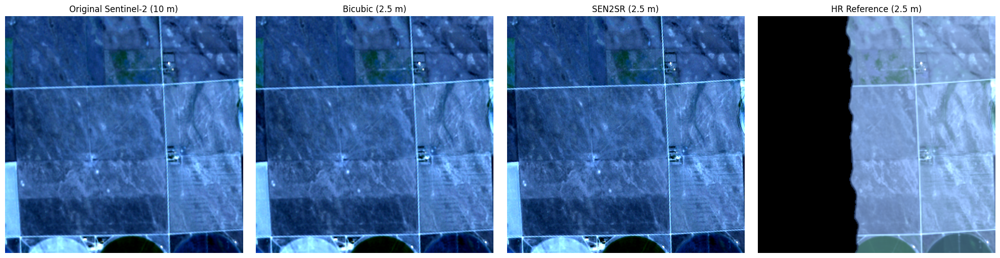

In [ ]:
import matplotlib.pyplot as plt

# RGB visualization
def make_rgb(img):
    rgb = img[[2, 1, 0]]  # B02, B03, B04
    rgb = np.transpose(rgb, (1, 2, 0))

    # Robust percentile stretch
    p2 = np.percentile(rgb, 2)
    p98 = np.percentile(rgb, 98)

    rgb = (rgb - p2) / (p98 - p2 + 1e-8)
    rgb = np.clip(rgb, 0, 1)

    return rgb


lr_rgb = make_rgb(lr_rgbn)
bicubic_rgb = make_rgb(bicubic_rgbn)
sr_rgb = make_rgb(sr_rgbn)
hr_rgb = make_rgb(hr_rgbn)


fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(lr_rgb)
axes[0].set_title("Original Sentinel-2 (10 m)")

axes[1].imshow(bicubic_rgb)
axes[1].set_title("Bicubic (2.5 m)")

axes[2].imshow(sr_rgb)
axes[2].set_title("SEN2SR (2.5 m)")

axes[3].imshow(hr_rgb)
axes[3].set_title("HR Reference (2.5 m)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

What this cell will produce

    10 m Sentinel-2
      ↓
    SEN2SR
      ↓
    2.5 m SR
      │
      ├── Observation consistency
      ├── Spectral consistency
      ├── SR vs Bicubic disagreement
      └── Input validity / cloud mask
                ↓
          TRUST SCORE 0–100
                ↓
      Confidence GeoTIFF

It will create:

SEN2SR_Confidence_2.5m.tif

SEN2SR_Uncertainty_2.5m.tif

SEN2SR_Validity_2.5m.tif

It also displays the confidence map

       SEN2SR PIXEL-LEVEL CONFIDENCE FRAMEWORK

SEN2SR output shape: (4, 1024, 1024)
Sentinel-2 input shape: (4, 256, 256)

SEN2SR output is already reflectance.

Resolution scaling:
  Height: 256 → 1024
  Width : 256 → 1024
  Scale : 4 × 4

Creating bicubic baseline...

Calculating observation consistency...
Calculating spectral consistency...
Calculating local stability...

Determining input validity...
No cloud mask available.
Using non-zero Sentinel-2 pixels.

Combining confidence components...


          CONFIDENCE / UNCERTAINTY SUMMARY

Valid pixels       : 1,048,576
Mean Trust Score   : 42.91 / 100
Median Trust Score : 42.23 / 100
Minimum            : 15.00
Maximum            : 98.56

Confidence distribution:
High   (80–100): 0.97%
Medium (50–80) : 21.05%
Low    (<50)   : 77.98%

Reading geospatial information...
Original CRS: EPSG:32613
Original size: 256 x 256
Original resolution: 10.0 10.0

2.5 m transform:
| 2.50, 0.00, 711000.00|
| 0.00,-2.50, 4398220.00|
| 0.00, 0.00, 1.0

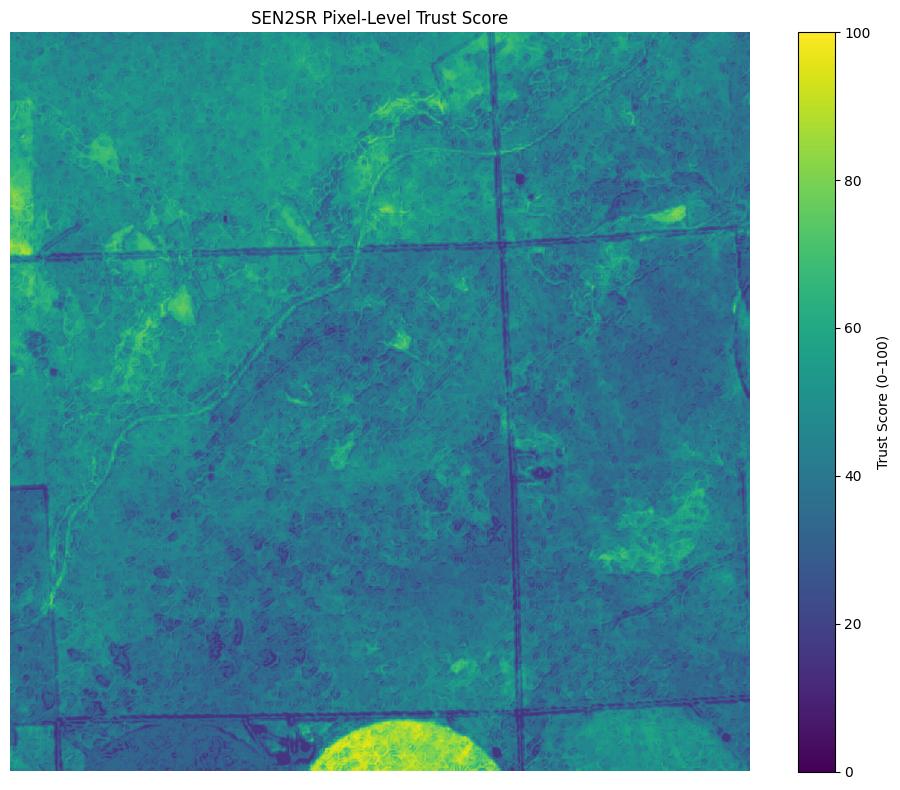

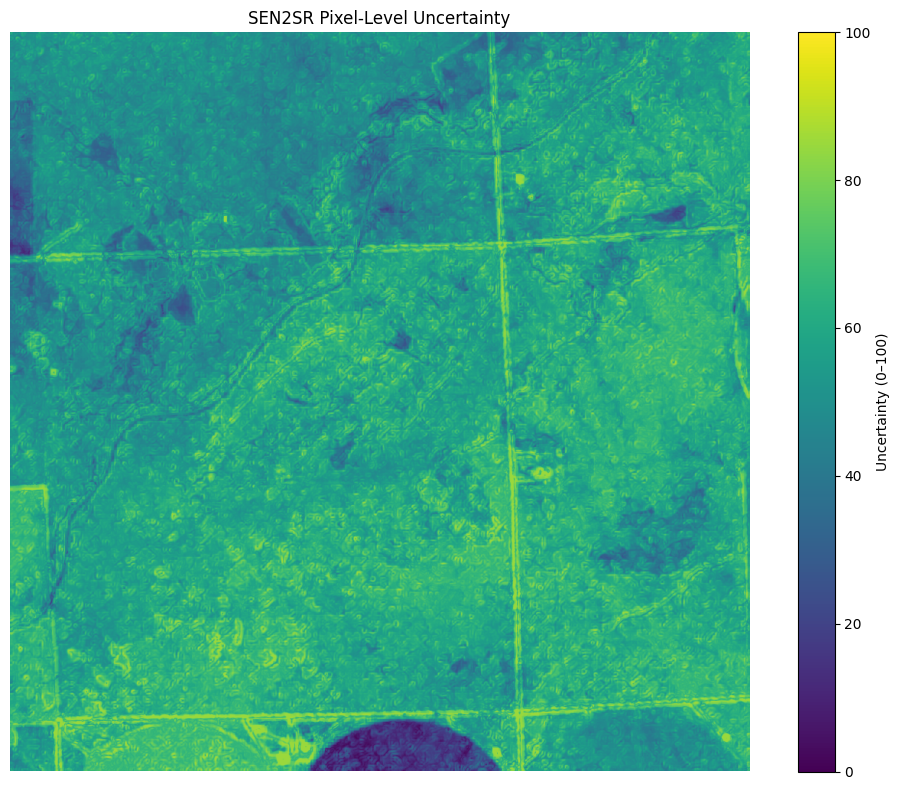

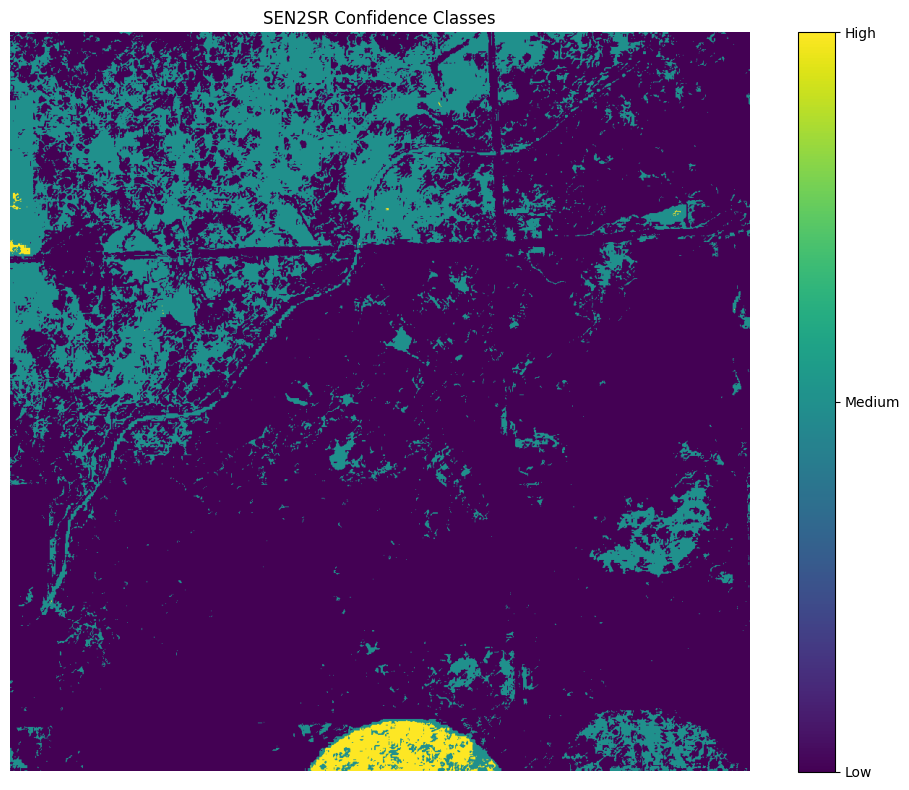



             OUTPUT VERIFICATION

File: /content/SEN2SR_Confidence_2.5m.tif
  Size       : 1024 x 1024
  CRS        : EPSG:32613
  Resolution : (2.5, 2.5)
  Bands      : 1
  Data type  : float32
  NoData     : 0.0

File: /content/SEN2SR_Uncertainty_2.5m.tif
  Size       : 1024 x 1024
  CRS        : EPSG:32613
  Resolution : (2.5, 2.5)
  Bands      : 1
  Data type  : float32
  NoData     : 100.0

File: /content/SEN2SR_Validity_2.5m.tif
  Size       : 1024 x 1024
  CRS        : EPSG:32613
  Resolution : (2.5, 2.5)
  Bands      : 1
  Data type  : uint8
  NoData     : 0.0

File: /content/SEN2SR_Confidence_Class_2.5m.tif
  Size       : 1024 x 1024
  CRS        : EPSG:32613
  Resolution : (2.5, 2.5)
  Bands      : 1
  Data type  : uint8
  NoData     : 0.0


       ✅ CONFIDENCE FRAMEWORK COMPLETE

Created files:
1. /content/SEN2SR_Confidence_2.5m.tif
2. /content/SEN2SR_Uncertainty_2.5m.tif
3. /content/SEN2SR_Validity_2.5m.tif
4. /content/SEN2SR_Confidence_Class_2.5m.tif

🚀 Ready for GIS / Q

In [ ]:
# ============================================================
# PIXEL-LEVEL SEN2SR CONFIDENCE / UNCERTAINTY FRAMEWORK
# COMPLETE CORRECTED VERSION
# ============================================================
#
# Uses existing variables:
#   sr_input / sr_numpy
#   lr_input / lr_rgbn
#   lr_path
#
# Produces:
#   SEN2SR_Confidence_2.5m.tif
#   SEN2SR_Uncertainty_2.5m.tif
#   SEN2SR_Validity_2.5m.tif
#
# IMPORTANT:
# This is a transparent RELIABILITY / TRUST SCORE,
# NOT a statistically calibrated probability.
# ============================================================

import numpy as np
import rasterio
from rasterio.transform import Affine
from skimage.transform import resize
import matplotlib.pyplot as plt


print("=" * 65)
print("       SEN2SR PIXEL-LEVEL CONFIDENCE FRAMEWORK")
print("=" * 65)


# ============================================================
# 1. GET EXISTING SEN2SR OUTPUT
# ============================================================

if "sr_validation" in globals():

    sr_input = sr_validation.detach().cpu().numpy()

elif "large_superX" in globals():

    sr_input = large_superX.detach().cpu().numpy()

elif "masked_superX" in globals():

    sr_input = masked_superX.detach().cpu().numpy()

elif "sr_numpy" in globals():

    sr_input = sr_numpy.copy()

else:

    raise RuntimeError(
        "No SEN2SR output found. Run SEN2SR inference first."
    )


# Remove batch dimension if present
if sr_input.ndim == 4:
    sr_input = sr_input[0]


sr_input = sr_input.astype(np.float32)

sr_input = np.nan_to_num(
    sr_input,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


print("\nSEN2SR output shape:", sr_input.shape)


# ============================================================
# 2. GET EXISTING 10 m SENTINEL-2 INPUT
# ============================================================

if "lr_rgbn" in globals():

    lr_input = lr_rgbn.copy().astype(np.float32)

elif "large_s2_numpy" in globals():

    lr_input = large_s2_numpy.copy().astype(np.float32)

elif "masked_s2" in globals():

    lr_input = masked_s2.copy().astype(np.float32)

else:

    raise RuntimeError(
        "No 10 m Sentinel-2 RGBN input found."
    )


lr_input = np.nan_to_num(
    lr_input,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


print("Sentinel-2 input shape:", lr_input.shape)


# ============================================================
# 3. MAKE SURE SEN2SR IS IN REFLECTANCE
# ============================================================

sr_99 = np.percentile(
    sr_input,
    99
)

if sr_99 > 2.0:

    print(
        "\nSEN2SR output is DN-like."
    )

    print(
        "Converting DN → reflectance."
    )

    sr_reflectance = (
        sr_input / 10000.0
    )

else:

    print(
        "\nSEN2SR output is already reflectance."
    )

    sr_reflectance = sr_input.copy()


sr_reflectance = np.clip(
    sr_reflectance,
    0.0,
    1.0
)


# ============================================================
# 4. CHECK 4× SUPER-RESOLUTION
# ============================================================

_, sr_height, sr_width = sr_reflectance.shape

_, lr_height, lr_width = lr_input.shape

scale_y = sr_height // lr_height
scale_x = sr_width // lr_width


print("\nResolution scaling:")
print("  Height:", lr_height, "→", sr_height)
print("  Width :", lr_width, "→", sr_width)
print("  Scale :", scale_y, "×", scale_x)


if scale_y != 4 or scale_x != 4:

    raise RuntimeError(
        "Expected 4× super-resolution, "
        f"but received {scale_y}×{scale_x}."
    )


# ============================================================
# 5. BICUBIC BASELINE
# ============================================================

print("\nCreating bicubic baseline...")

bicubic = np.zeros(
    (4, sr_height, sr_width),
    dtype=np.float32
)


for b in range(4):

    bicubic[b] = resize(
        lr_input[b],
        (sr_height, sr_width),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    ).astype(np.float32)


bicubic = np.clip(
    bicubic,
    0.0,
    1.0
)


# ============================================================
# 6. OBSERVATION CONSISTENCY
# ============================================================
#
# Downsample SEN2SR 2.5 m → 10 m
#
# Then compare it against the actual Sentinel-2 observation.
#
# Smaller difference = greater confidence.
# ============================================================

print("\nCalculating observation consistency...")

sr_10m = sr_reflectance.reshape(
    4,
    lr_height,
    scale_y,
    lr_width,
    scale_x
).mean(
    axis=(2, 4)
)


observation_residual = np.mean(
    np.abs(
        sr_10m - lr_input
    ),
    axis=0
)


# Robust normalization
obs_p95 = np.percentile(
    observation_residual,
    95
)


observation_error_norm = np.clip(
    observation_residual /
    (obs_p95 + 1e-8),
    0,
    1
)


observation_confidence_10m = (
    1.0 - observation_error_norm
)


# Upscale confidence to 2.5 m
observation_confidence = np.repeat(
    np.repeat(
        observation_confidence_10m,
        scale_y,
        axis=0
    ),
    scale_x,
    axis=1
)


observation_confidence = observation_confidence[
    :sr_height,
    :sr_width
]


# ============================================================
# 7. SR vs BICUBIC SPECTRAL DIFFERENCE
# ============================================================
#
# Large disagreement is treated as a caution signal.
#
# IMPORTANT:
# Disagreement does NOT automatically mean SEN2SR is wrong.
# ============================================================

print("Calculating spectral consistency...")

spectral_difference = np.mean(
    np.abs(
        sr_reflectance - bicubic
    ),
    axis=0
)


spectral_p95 = np.percentile(
    spectral_difference,
    95
)


spectral_difference_norm = np.clip(
    spectral_difference /
    (spectral_p95 + 1e-8),
    0,
    1
)


spectral_confidence = (
    1.0 - spectral_difference_norm
)


# ============================================================
# 8. LOCAL STABILITY
# ============================================================
#
# Measures local gradient variation.
#
# Large difference between SEN2SR and bicubic is treated
# as lower reliability.
# ============================================================

print("Calculating local stability...")


def local_variation(image):

    gx = np.diff(
        image,
        axis=1,
        prepend=image[:, :1, :]
    )

    gy = np.diff(
        image,
        axis=2,
        prepend=image[:, :, :1]
    )

    gradient = np.sqrt(
        gx**2 + gy**2
    )

    return np.mean(
        gradient,
        axis=0
    )


sr_variation = local_variation(
    sr_reflectance
)


bicubic_variation = local_variation(
    bicubic
)


variation_difference = np.abs(
    sr_variation -
    bicubic_variation
)


variation_p95 = np.percentile(
    variation_difference,
    95
)


variation_difference_norm = np.clip(
    variation_difference /
    (variation_p95 + 1e-8),
    0,
    1
)


local_stability_confidence = (
    1.0 -
    variation_difference_norm
)


# ============================================================
# 9. INPUT VALIDITY
# ============================================================
#
# Priority:
#
# 1. Existing valid_mask
# 2. Existing cloud_mask
# 3. Non-zero Sentinel-2 pixels
# ============================================================

print("\nDetermining input validity...")


if "valid_mask" in globals():

    input_valid_mask = (
        valid_mask.astype(bool)
    )

    print(
        "Using existing valid_mask."
    )


elif "cloud_mask" in globals():

    input_valid_mask = (
        ~cloud_mask
    )

    print(
        "Using existing cloud_mask."
    )


else:

    input_valid_mask = np.all(
        lr_input > 0,
        axis=0
    )

    print(
        "No cloud mask available."
    )

    print(
        "Using non-zero Sentinel-2 pixels."
    )


# Make sure dimensions are correct
if input_valid_mask.shape != (
    lr_height,
    lr_width
):

    raise RuntimeError(
        "Validity mask dimensions do not match "
        "the Sentinel-2 input."
    )


# ============================================================
# 10. UPSCALE VALIDITY MASK TO 2.5 m
# ============================================================

valid_25m = np.repeat(
    np.repeat(
        input_valid_mask,
        scale_y,
        axis=0
    ),
    scale_x,
    axis=1
)


valid_25m = valid_25m[
    :sr_height,
    :sr_width
]


# ============================================================
# 11. COMBINE CONFIDENCE COMPONENTS
# ============================================================
#
# Engineering weights:
#
# Observation consistency = 40%
# Spectral consistency   = 25%
# Local stability       = 20%
# Input validity         = 15%
#
# These weights are NOT statistically calibrated.
# ============================================================

print("\nCombining confidence components...")


confidence = (

    0.40 *
    observation_confidence

    +

    0.25 *
    spectral_confidence

    +

    0.20 *
    local_stability_confidence

    +

    0.15 *
    valid_25m.astype(np.float32)

)


# ============================================================
# 12. INVALID PIXELS = ZERO CONFIDENCE
# ============================================================

confidence[
    ~valid_25m
] = 0.0


confidence = np.clip(
    confidence,
    0.0,
    1.0
)


# ============================================================
# 13. TRUST SCORE 0–100
# ============================================================

trust_score = (
    confidence * 100.0
).astype(np.float32)


# ============================================================
# 14. UNCERTAINTY SCORE 0–100
# ============================================================

uncertainty = (
    100.0 -
    trust_score
).astype(np.float32)


uncertainty[
    ~valid_25m
] = 100.0


# ============================================================
# 15. CONFIDENCE CLASSES
# ============================================================
#
# 0 = Invalid
# 1 = Low       (<50)
# 2 = Medium    (50–80)
# 3 = High      (80–100)
# ============================================================

confidence_class = np.zeros(
    trust_score.shape,
    dtype=np.uint8
)


confidence_class[
    (trust_score > 0) &
    (trust_score < 50)
] = 1


confidence_class[
    (trust_score >= 50) &
    (trust_score < 80)
] = 2


confidence_class[
    trust_score >= 80
] = 3


confidence_class[
    ~valid_25m
] = 0


# ============================================================
# 16. STATISTICAL SUMMARY
# ============================================================

valid_scores = trust_score[
    valid_25m
]


print("\n")
print("=" * 65)
print("          CONFIDENCE / UNCERTAINTY SUMMARY")
print("=" * 65)


print(
    f"\nValid pixels       : "
    f"{valid_scores.size:,}"
)


print(
    f"Mean Trust Score   : "
    f"{np.mean(valid_scores):.2f} / 100"
)


print(
    f"Median Trust Score : "
    f"{np.median(valid_scores):.2f} / 100"
)


print(
    f"Minimum            : "
    f"{np.min(valid_scores):.2f}"
)


print(
    f"Maximum            : "
    f"{np.max(valid_scores):.2f}"
)


high_pct = np.mean(
    valid_scores >= 80
) * 100


medium_pct = np.mean(
    (valid_scores >= 50) &
    (valid_scores < 80)
) * 100


low_pct = np.mean(
    valid_scores < 50
) * 100


print("\nConfidence distribution:")


print(
    f"High   (80–100): "
    f"{high_pct:.2f}%"
)


print(
    f"Medium (50–80) : "
    f"{medium_pct:.2f}%"
)


print(
    f"Low    (<50)   : "
    f"{low_pct:.2f}%"
)


# ============================================================
# 17. GET GEOREFERENCING DIRECTLY FROM LR GEOTIFF
# ============================================================
#
# THIS FIXES THE PREVIOUS ERROR.
#
# We do NOT use large_sample.
# We use the actual Sentinel-2 validation GeoTIFF.
# ============================================================

print("\nReading geospatial information...")


if "lr_path" not in globals():

    raise RuntimeError(
        "lr_path is not available. "
        "Please make sure the SEN2NEON LR file was loaded."
    )


with rasterio.open(
    lr_path
) as src:

    crs = src.crs

    transform_10m = src.transform

    original_width = src.width

    original_height = src.height


print(
    "Original CRS:",
    crs
)


print(
    "Original size:",
    original_width,
    "x",
    original_height
)


print(
    "Original resolution:",
    transform_10m.a,
    abs(transform_10m.e)
)


# ============================================================
# 18. CREATE CORRECT 2.5 m AFFINE TRANSFORM
# ============================================================

transform_25m = Affine(
    transform_10m.a / 4,
    transform_10m.b,
    transform_10m.c,

    transform_10m.d,
    transform_10m.e / 4,
    transform_10m.f
)


print(
    "\n2.5 m transform:"
)

print(
    transform_25m
)


# Verify resolution
print(
    "\n2.5 m resolution:",
    transform_25m.a,
    abs(transform_25m.e)
)


# ============================================================
# 19. OUTPUT FILE PATHS
# ============================================================

confidence_path = (
    "/content/SEN2SR_Confidence_2.5m.tif"
)

uncertainty_path = (
    "/content/SEN2SR_Uncertainty_2.5m.tif"
)

validity_path = (
    "/content/SEN2SR_Validity_2.5m.tif"
)

class_path = (
    "/content/SEN2SR_Confidence_Class_2.5m.tif"
)


# ============================================================
# 20. WRITE CONFIDENCE GEOTIFF
# ============================================================

with rasterio.open(
    confidence_path,
    "w",
    driver="GTiff",
    height=trust_score.shape[0],
    width=trust_score.shape[1],
    count=1,
    dtype="float32",
    crs=crs,
    transform=transform_25m,
    nodata=0,
    compress="deflate"
) as dst:

    dst.write(
        trust_score,
        1
    )

    dst.set_band_description(
        1,
        "SR Trust Score (0-100)"
    )


# ============================================================
# 21. WRITE UNCERTAINTY GEOTIFF
# ============================================================

with rasterio.open(
    uncertainty_path,
    "w",
    driver="GTiff",
    height=uncertainty.shape[0],
    width=uncertainty.shape[1],
    count=1,
    dtype="float32",
    crs=crs,
    transform=transform_25m,
    nodata=100,
    compress="deflate"
) as dst:

    dst.write(
        uncertainty,
        1
    )

    dst.set_band_description(
        1,
        "SR Uncertainty Score (0-100)"
    )


# ============================================================
# 22. WRITE VALIDITY GEOTIFF
# ============================================================

with rasterio.open(
    validity_path,
    "w",
    driver="GTiff",
    height=valid_25m.shape[0],
    width=valid_25m.shape[1],
    count=1,
    dtype="uint8",
    crs=crs,
    transform=transform_25m,
    nodata=0,
    compress="deflate"
) as dst:

    dst.write(
        valid_25m.astype(np.uint8),
        1
    )

    dst.set_band_description(
        1,
        "SR Input Validity Mask"
    )


# ============================================================
# 23. WRITE CONFIDENCE CLASS GEOTIFF
# ============================================================

with rasterio.open(
    class_path,
    "w",
    driver="GTiff",
    height=confidence_class.shape[0],
    width=confidence_class.shape[1],
    count=1,
    dtype="uint8",
    crs=crs,
    transform=transform_25m,
    nodata=0,
    compress="deflate"
) as dst:

    dst.write(
        confidence_class,
        1
    )

    dst.set_band_description(
        1,
        "SR Confidence Class"
    )


# ============================================================
# 24. DISPLAY TRUST SCORE
# ============================================================

plt.figure(
    figsize=(10, 8)
)

display_confidence = trust_score.copy()

display_confidence[
    ~valid_25m
] = np.nan


plt.imshow(
    display_confidence,
    vmin=0,
    vmax=100
)


plt.colorbar(
    label="Trust Score (0–100)"
)


plt.title(
    "SEN2SR Pixel-Level Trust Score"
)


plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 25. DISPLAY UNCERTAINTY
# ============================================================

plt.figure(
    figsize=(10, 8)
)

display_uncertainty = uncertainty.copy()

display_uncertainty[
    ~valid_25m
] = np.nan


plt.imshow(
    display_uncertainty,
    vmin=0,
    vmax=100
)


plt.colorbar(
    label="Uncertainty (0–100)"
)


plt.title(
    "SEN2SR Pixel-Level Uncertainty"
)


plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 26. DISPLAY CONFIDENCE CLASSES
# ============================================================

plt.figure(
    figsize=(10, 8)
)

display_class = confidence_class.astype(
    np.float32
)

display_class[
    ~valid_25m
] = np.nan


plt.imshow(
    display_class,
    vmin=1,
    vmax=3
)


cbar = plt.colorbar(
    ticks=[1, 2, 3]
)

cbar.ax.set_yticklabels([
    "Low",
    "Medium",
    "High"
])


plt.title(
    "SEN2SR Confidence Classes"
)


plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 27. VERIFY ALL GEOTIFF FILES
# ============================================================

print("\n")
print("=" * 65)
print("             OUTPUT VERIFICATION")
print("=" * 65)


output_files = [
    confidence_path,
    uncertainty_path,
    validity_path,
    class_path
]


for path in output_files:

    with rasterio.open(path) as src:

        print("\nFile:", path)

        print(
            "  Size       :",
            src.width,
            "x",
            src.height
        )

        print(
            "  CRS        :",
            src.crs
        )

        print(
            "  Resolution :",
            src.res
        )

        print(
            "  Bands      :",
            src.count
        )

        print(
            "  Data type  :",
            src.dtypes[0]
        )

        print(
            "  NoData     :",
            src.nodata
        )


print("\n")
print("=" * 65)
print("       ✅ CONFIDENCE FRAMEWORK COMPLETE")
print("=" * 65)

print("\nCreated files:")

print(
    "1.",
    confidence_path
)

print(
    "2.",
    uncertainty_path
)

print(
    "3.",
    validity_path
)

print(
    "4.",
    class_path
)

print("\n🚀 Ready for GIS / QGIS integration.")

Now we move from an engineering trust score to a data-driven calibration experiment.

The idea is:

    Our existing Trust Score
        │
        ▼
    Compare against actual HR-reference error
        │
        ▼
    Do high-trust pixels actually have lower error?
        │
        ▼
    Calibrated reliability relationship

Since your current validation notebook already has the SEN2NEON tiles and validate_sen2neon_tile() function, we'll use those rather than rerunning the entire benchmark blindly.

Important

We should not overwrite your existing Trust Score yet. First we need to measure whether it correlates with actual error. If it doesn't, we'll change the formulation.

       DATA-DRIVEN SEN2SR TRUST SCORE CALIBRATION

Calibration tile: 2018_OAES_3__3_5

Files loaded successfully.
LR shape: (4, 256, 256)
HR shape: (4, 1024, 1024)

Running SEN2SR...


100%|██████████| 9/9 [00:04<00:00,  2.01it/s]


SEN2SR shape: (4, 1024, 1024)

Valid HR pixels: 1028120

Calibration samples: 1028120


              TRUST SCORE CALIBRATION

Correlation between Trust Score and actual SR error:
-0.0670

Ideal behavior:
Higher Trust Score → Lower actual error
Therefore the correlation should be NEGATIVE.

Trust-score bins:


,trust_bin,Pixels,Mean_Trust,Mean_SR_Error,Mean_Bicubic_Error
0,0–20,15996,16.176039,0.018233,0.016953
1,20–40,66541,31.500393,0.015974,0.015481
2,40–60,134180,51.212860,0.015086,0.014863
3,60–80,353864,71.922493,0.014691,0.014602
4,80–100,457539,86.596756,0.014035,0.014010



Correlation between Trust Score and HR-reference quality:
0.0616


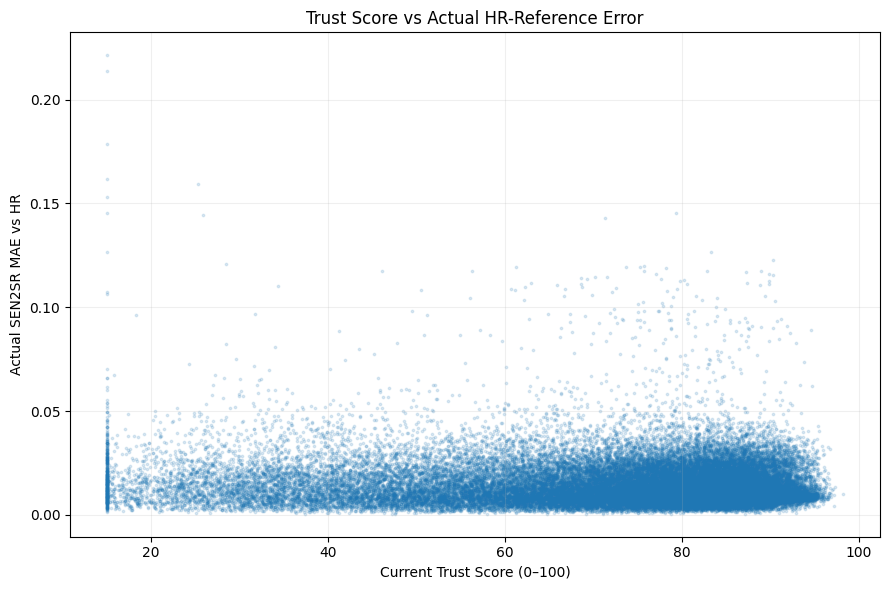

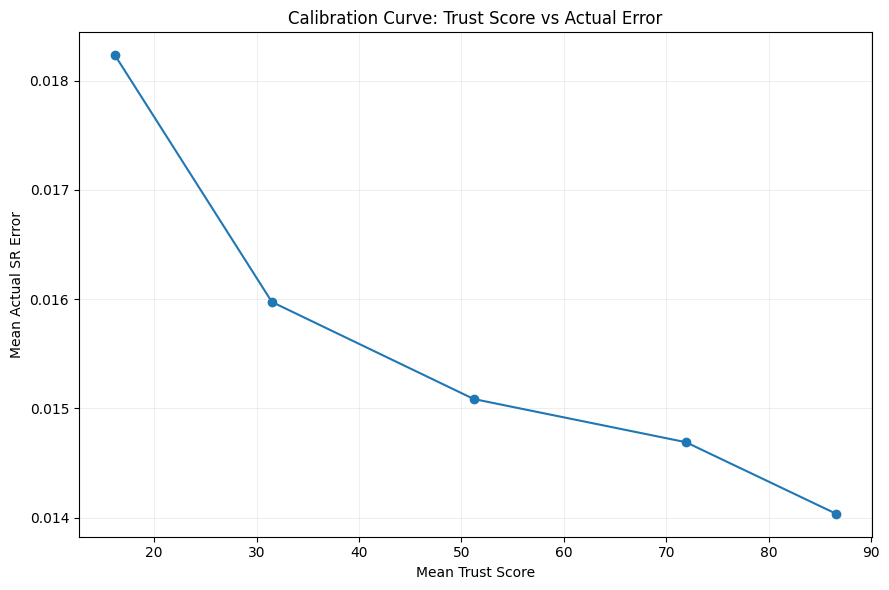



             HIGH vs LOW TRUST

High-trust pixels:
Pixels: 457539
Mean actual error: 0.014035

Low-trust pixels:
Pixels: 82537
Mean actual error: 0.016412


              CALIBRATION COMPLETE

Trust ↔ Actual Error correlation: -0.0670
Trust ↔ Reference Quality correlation: 0.0616

Saved:
/content/SEN2SR_TrustScore_Calibration.csv
/content/SEN2SR_TrustScore_BinSummary.csv

Interpretation:
🟡 Trust score shows a weak inverse relationship with actual error.

⚠️ This is calibration evidence, not a statistically calibrated probability.

✅ Trust-score calibration experiment finished.


In [ ]:
# ============================================================
# DATA-DRIVEN TRUST SCORE CALIBRATION
# ============================================================
#
# Goal:
# Determine whether our pixel-level Trust Score is related
# to actual SEN2SR reconstruction error against the
# 2.5 m SEN2NEON reference.
#
# We will:
#   1. Use an existing SEN2NEON validation tile
#   2. Generate SEN2SR + bicubic
#   3. Calculate actual pixel-level SR error
#   4. Calculate the same confidence components
#   5. Compare Trust Score vs actual error
#   6. Divide pixels into Trust Score bins
#   7. Measure actual error in each bin
#
# This is calibration/diagnostic analysis.
# It does NOT claim a calibrated probability.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import rasterio

from skimage.transform import resize


print("=" * 70)
print("       DATA-DRIVEN SEN2SR TRUST SCORE CALIBRATION")
print("=" * 70)


# ============================================================
# 1. SELECT VALIDATION TILE
# ============================================================

if "selected_tiles" in globals():

    calibration_tile = selected_tiles.iloc[0]["id"]

elif "tile_id" in globals():

    calibration_tile = tile_id

else:

    # Known clean SEN2NEON validation tile
    calibration_tile = "2018_OAES_3__3_5"


print(
    "\nCalibration tile:",
    calibration_tile
)


# ============================================================
# 2. FIND EXACT SEN2NEON FILES
# ============================================================

from huggingface_hub import hf_hub_download


repo_id = "isp-uv-es/SEN2NEON"


lr_file = f"s2_l2a_10m/{calibration_tile}.tif"

hr_file = f"neon_2.5m_linearized/{calibration_tile}.tif"


lr_cal_path = hf_hub_download(
    repo_id=repo_id,
    filename=lr_file,
    repo_type="dataset"
)


hr_cal_path = hf_hub_download(
    repo_id=repo_id,
    filename=hr_file,
    repo_type="dataset"
)


print("\nFiles loaded successfully.")


# ============================================================
# 3. LOAD SENTINEL-2 10 m RGBN
# ============================================================

with rasterio.open(
    lr_cal_path
) as src:

    lr_data = src.read().astype(
        np.float32
    )

    lr_crs = src.crs
    lr_transform = src.transform


# SEN2NEON bands:
#
# B1, B2, B3, B4, B5, B6, B7, B8, ...
#
# RGBN = B04, B03, B02, B08
#
# indices = 3,2,1,7

lr_rgbn_cal = lr_data[
    [3, 2, 1, 7]
]


lr_rgbn_cal /= 10000.0


lr_rgbn_cal = np.nan_to_num(
    lr_rgbn_cal,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


lr_rgbn_cal = np.clip(
    lr_rgbn_cal,
    0.0,
    1.0
)


print(
    "LR shape:",
    lr_rgbn_cal.shape
)


# ============================================================
# 4. LOAD 2.5 m HR REFERENCE
# ============================================================

with rasterio.open(
    hr_cal_path
) as src:

    hr_data = src.read().astype(
        np.float32
    )


hr_rgbn_cal = hr_data[
    [3, 2, 1, 7]
]


hr_rgbn_cal /= 10000.0


hr_rgbn_cal = np.nan_to_num(
    hr_rgbn_cal,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


hr_rgbn_cal = np.clip(
    hr_rgbn_cal,
    0.0,
    1.0
)


print(
    "HR shape:",
    hr_rgbn_cal.shape
)


# ============================================================
# 5. GENERATE SEN2SR
# ============================================================

print(
    "\nRunning SEN2SR..."
)


X_cal = torch.from_numpy(
    lr_rgbn_cal
).float().to(device)


X_cal = torch.nan_to_num(
    X_cal,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


with torch.no_grad():

    sr_cal = sen2sr.predict_large(
        model=model,
        X=X_cal,
        overlap=32
    )


sr_cal = (
    sr_cal.detach()
    .cpu()
    .numpy()
)


if sr_cal.ndim == 4:

    sr_cal = sr_cal[0]


# Automatically handle possible DN output
if np.percentile(sr_cal, 99) > 2.0:

    sr_cal = sr_cal / 10000.0


sr_cal = np.clip(
    sr_cal.astype(np.float32),
    0.0,
    1.0
)


print(
    "SEN2SR shape:",
    sr_cal.shape
)


# ============================================================
# 6. CREATE BICUBIC BASELINE
# ============================================================

bicubic_cal = np.zeros_like(
    sr_cal,
    dtype=np.float32
)


for b in range(4):

    bicubic_cal[b] = resize(
        lr_rgbn_cal[b],
        (1024, 1024),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    ).astype(np.float32)


bicubic_cal = np.clip(
    bicubic_cal,
    0.0,
    1.0
)


# ============================================================
# 7. VALID REFERENCE PIXELS
# ============================================================

valid_hr = np.all(
    hr_rgbn_cal > 0,
    axis=0
)


print(
    "\nValid HR pixels:",
    np.sum(valid_hr)
)


# ============================================================
# 8. ACTUAL SEN2SR PIXEL ERROR
# ============================================================
#
# Mean absolute spectral error across the four bands.
#
# This is our "ground-truth-like" error target for calibration.
# ============================================================

actual_error = np.mean(
    np.abs(
        sr_cal -
        hr_rgbn_cal
    ),
    axis=0
)


# ============================================================
# 9. ACTUAL BICUBIC ERROR
# ============================================================

bicubic_error = np.mean(
    np.abs(
        bicubic_cal -
        hr_rgbn_cal
    ),
    axis=0
)


# ============================================================
# 10. OBSERVATION CONSISTENCY
# ============================================================

sr_10m_cal = sr_cal.reshape(
    4,
    256,
    4,
    256,
    4
).mean(
    axis=(2, 4)
)


observation_residual = np.mean(
    np.abs(
        sr_10m_cal -
        lr_rgbn_cal
    ),
    axis=0
)


obs_p95 = np.percentile(
    observation_residual,
    95
)


observation_error_norm = np.clip(
    observation_residual /
    (obs_p95 + 1e-8),
    0,
    1
)


observation_confidence_10m = (
    1.0 -
    observation_error_norm
)


observation_confidence = np.repeat(
    np.repeat(
        observation_confidence_10m,
        4,
        axis=0
    ),
    4,
    axis=1
)


# ============================================================
# 11. SR vs BICUBIC SPECTRAL DIFFERENCE
# ============================================================

spectral_difference = np.mean(
    np.abs(
        sr_cal -
        bicubic_cal
    ),
    axis=0
)


spectral_p95 = np.percentile(
    spectral_difference,
    95
)


spectral_confidence = (
    1.0 -
    np.clip(
        spectral_difference /
        (spectral_p95 + 1e-8),
        0,
        1
    )
)


# ============================================================
# 12. LOCAL STABILITY
# ============================================================

def local_variation_cal(image):

    gx = np.diff(
        image,
        axis=1,
        prepend=image[:, :1, :]
    )

    gy = np.diff(
        image,
        axis=2,
        prepend=image[:, :, :1]
    )

    gradient = np.sqrt(
        gx**2 +
        gy**2
    )

    return np.mean(
        gradient,
        axis=0
    )


sr_variation = local_variation_cal(
    sr_cal
)


bicubic_variation = local_variation_cal(
    bicubic_cal
)


variation_difference = np.abs(
    sr_variation -
    bicubic_variation
)


variation_p95 = np.percentile(
    variation_difference,
    95
)


local_stability_confidence = (
    1.0 -
    np.clip(
        variation_difference /
        (variation_p95 + 1e-8),
        0,
        1
    )
)


# ============================================================
# 13. VALIDITY
# ============================================================

valid_25m_cal = np.repeat(
    np.repeat(
        valid_hr[
            ::4,
            ::4
        ],
        4,
        axis=0
    ),
    4,
    axis=1
)


# Ensure exact dimensions
valid_25m_cal = valid_25m_cal[
    :1024,
    :1024
]


# ============================================================
# 14. CURRENT ENGINEERING TRUST SCORE
# ============================================================

trust_current = (

    0.40 *
    observation_confidence

    +

    0.25 *
    spectral_confidence

    +

    0.20 *
    local_stability_confidence

    +

    0.15 *
    valid_25m_cal.astype(
        np.float32
    )

)


trust_current *= 100.0


trust_current[
    ~valid_hr
] = np.nan


# ============================================================
# 15. CREATE DATAFRAME FOR CALIBRATION
# ============================================================

mask = (
    valid_hr &
    np.isfinite(trust_current) &
    np.isfinite(actual_error)
)


calibration_df = pd.DataFrame({

    "trust_score":
        trust_current[mask],

    "actual_sr_error":
        actual_error[mask],

    "bicubic_error":
        bicubic_error[mask],

    "observation_confidence":
        observation_confidence[mask],

    "spectral_confidence":
        spectral_confidence[mask],

    "local_stability":
        local_stability_confidence[mask]

})


print(
    "\nCalibration samples:",
    len(calibration_df)
)


# ============================================================
# 16. TRUST VS ACTUAL ERROR CORRELATION
# ============================================================

trust_error_corr = np.corrcoef(
    calibration_df[
        "trust_score"
    ],
    calibration_df[
        "actual_sr_error"
    ]
)[0, 1]


print("\n")
print("=" * 70)
print("              TRUST SCORE CALIBRATION")
print("=" * 70)


print(
    f"\nCorrelation between Trust Score "
    f"and actual SR error:"
)


print(
    f"{trust_error_corr:.4f}"
)


print(
    "\nIdeal behavior:"
)


print(
    "Higher Trust Score → Lower actual error"
)


print(
    "Therefore the correlation should be NEGATIVE."
)


# ============================================================
# 17. TRUST SCORE BINS
# ============================================================

bins = [
    0,
    20,
    40,
    60,
    80,
    100
]


labels = [
    "0–20",
    "20–40",
    "40–60",
    "60–80",
    "80–100"
]


calibration_df[
    "trust_bin"
] = pd.cut(
    calibration_df[
        "trust_score"
    ],
    bins=bins,
    labels=labels,
    include_lowest=True
)


bin_summary = (
    calibration_df
    .groupby(
        "trust_bin",
        observed=False
    )
    .agg(

        Pixels=(
            "actual_sr_error",
            "count"
        ),

        Mean_Trust=(
            "trust_score",
            "mean"
        ),

        Mean_SR_Error=(
            "actual_sr_error",
            "mean"
        ),

        Mean_Bicubic_Error=(
            "bicubic_error",
            "mean"
        )

    )
    .reset_index()
)


print(
    "\nTrust-score bins:"
)


display(
    bin_summary
)


# ============================================================
# 18. NORMALIZED ERROR
# ============================================================
#
# Convert actual error into a 0–100 quality score.
#
# Lower actual error = higher reference-based quality.
#
# This is useful for comparing our proxy trust score against
# actual reference performance.
# ============================================================

error_p95 = np.percentile(
    calibration_df[
        "actual_sr_error"
    ],
    95
)


calibration_df[
    "reference_quality"
] = (

    1.0 -

    np.clip(
        calibration_df[
            "actual_sr_error"
        ] /
        (error_p95 + 1e-8),
        0,
        1
    )

) * 100


# ============================================================
# 19. TRUST VS REFERENCE QUALITY CORRELATION
# ============================================================

trust_quality_corr = np.corrcoef(

    calibration_df[
        "trust_score"
    ],

    calibration_df[
        "reference_quality"
    ]

)[0, 1]


print(
    "\nCorrelation between Trust Score "
    "and HR-reference quality:"
)


print(
    f"{trust_quality_corr:.4f}"
)


# ============================================================
# 20. VISUALIZE TRUST VS ACTUAL ERROR
# ============================================================

# Sample pixels for faster plotting
plot_df = calibration_df.sample(
    min(
        50000,
        len(calibration_df)
    ),
    random_state=42
)


plt.figure(
    figsize=(9, 6)
)


plt.scatter(
    plot_df[
        "trust_score"
    ],
    plot_df[
        "actual_sr_error"
    ],
    s=3,
    alpha=0.15
)


plt.xlabel(
    "Current Trust Score (0–100)"
)


plt.ylabel(
    "Actual SEN2SR MAE vs HR"
)


plt.title(
    "Trust Score vs Actual HR-Reference Error"
)


plt.grid(
    alpha=0.2
)


plt.tight_layout()

plt.show()


# ============================================================
# 21. BINNED ERROR CURVE
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    bin_summary[
        "Mean_Trust"
    ],
    bin_summary[
        "Mean_SR_Error"
    ],
    marker="o"
)


plt.xlabel(
    "Mean Trust Score"
)


plt.ylabel(
    "Mean Actual SR Error"
)


plt.title(
    "Calibration Curve: Trust Score vs Actual Error"
)


plt.grid(
    alpha=0.2
)


plt.tight_layout()

plt.show()


# ============================================================
# 22. COMPARE HIGH VS LOW TRUST PIXELS
# ============================================================

high_threshold = 80
low_threshold = 40


high_trust = calibration_df[
    calibration_df[
        "trust_score"
    ] >= high_threshold
]


low_trust = calibration_df[
    calibration_df[
        "trust_score"
    ] < low_threshold
]


print("\n")
print("=" * 70)
print("             HIGH vs LOW TRUST")
print("=" * 70)


if len(high_trust) > 0:

    print(
        "\nHigh-trust pixels:"
    )

    print(
        "Pixels:",
        len(high_trust)
    )

    print(
        "Mean actual error:",
        f"{high_trust.actual_sr_error.mean():.6f}"
    )

else:

    print(
        "\nNo pixels with Trust >= 80."
    )


if len(low_trust) > 0:

    print(
        "\nLow-trust pixels:"
    )

    print(
        "Pixels:",
        len(low_trust)
    )

    print(
        "Mean actual error:",
        f"{low_trust.actual_sr_error.mean():.6f}"
    )


# ============================================================
# 23. SAVE CALIBRATION TABLE
# ============================================================

calibration_csv = (
    "/content/SEN2SR_TrustScore_Calibration.csv"
)


bin_summary_csv = (
    "/content/SEN2SR_TrustScore_BinSummary.csv"
)


calibration_df.to_csv(
    calibration_csv,
    index=False
)


bin_summary.to_csv(
    bin_summary_csv,
    index=False
)


# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("              CALIBRATION COMPLETE")
print("=" * 70)


print(
    "\nTrust ↔ Actual Error correlation:",
    f"{trust_error_corr:.4f}"
)


print(
    "Trust ↔ Reference Quality correlation:",
    f"{trust_quality_corr:.4f}"
)


print(
    "\nSaved:"
)


print(
    calibration_csv
)


print(
    bin_summary_csv
)


print(
    "\nInterpretation:"
)


if trust_error_corr < -0.3:

    print(
        "🟢 Trust score shows a meaningful inverse "
        "relationship with actual error."
    )

elif trust_error_corr < 0:

    print(
        "🟡 Trust score shows a weak inverse "
        "relationship with actual error."
    )

else:

    print(
        "🔴 Current trust score does not show the "
        "expected inverse relationship with actual error."
    )


print(
    "\n⚠️ This is calibration evidence, not a "
    "statistically calibrated probability."
)


print(
    "\n✅ Trust-score calibration experiment finished."
)

     DATA-DRIVEN 10-TILE SEN2SR TRUST SCORE CALIBRATION

Validation tiles: 10
01. 2018_OAES_3__3_5
02. 2019_JERC_5__5_4
03. 2021_HEAL_4__5_4
04. 2022_OAES_6__4_0
05. 2022_WREF_5__5_1
06. 2022_MLBS_5__4_2
07. 2023_DELA_7__1_1
08. 2023_YELL_5__3_7
09. 2024_BONA_6__1_3
10. 2024_ARIK_6__5_0

PROCESSING VALIDATION TILES

----------------------------------------------------------------------
Tile 1/10: 2018_OAES_3__3_5
----------------------------------------------------------------------
LR shape: (4, 256, 256) | HR shape: (4, 1024, 1024)
Running SEN2SR...


100%|██████████| 9/9 [00:02<00:00,  3.06it/s]


SEN2SR output already in reflectance.
Valid HR pixels: 1,028,120
SEN2SR sampled MAE : 0.014601
Bicubic sampled MAE: 0.014480

----------------------------------------------------------------------
Tile 2/10: 2019_JERC_5__5_4
----------------------------------------------------------------------
LR shape: (4, 256, 256) | HR shape: (4, 1024, 1024)
Running SEN2SR...


100%|██████████| 9/9 [00:03<00:00,  2.96it/s]


SEN2SR output already in reflectance.
Valid HR pixels: 1,048,576
SEN2SR sampled MAE : 0.022038
Bicubic sampled MAE: 0.021592

----------------------------------------------------------------------
Tile 3/10: 2021_HEAL_4__5_4
----------------------------------------------------------------------
LR shape: (4, 256, 256) | HR shape: (4, 1024, 1024)
Running SEN2SR...


...

SEN2SR output already in reflectance.
Valid HR pixels: 1,047,648
SEN2SR sampled MAE : 0.011401
Bicubic sampled MAE: 0.010898

----------------------------------------------------------------------
Tile 9/10: 2024_BONA_6__1_3
----------------------------------------------------------------------
LR shape: (4, 256, 256) | HR shape: (4, 1024, 1024)
Running SEN2SR...


100%|██████████| 9/9 [00:02<00:00,  3.87it/s]


SEN2SR output already in reflectance.
Valid HR pixels: 1,048,576
SEN2SR sampled MAE : 0.004830
Bicubic sampled MAE: 0.004570

----------------------------------------------------------------------
Tile 10/10: 2024_ARIK_6__5_0
----------------------------------------------------------------------
LR shape: (4, 256, 256) | HR shape: (4, 1024, 1024)
Running SEN2SR...


100%|██████████| 9/9 [00:01<00:00,  4.69it/s]


SEN2SR output already in reflectance.
Valid HR pixels: 635,788
SEN2SR sampled MAE : 0.008671
Bicubic sampled MAE: 0.008413

CALIBRATION DATASET
Samples: 250,000
Features: 4

Feature order:
0 = Observation consistency error
1 = Spectral disagreement
2 = Local spatial instability
3 = Input validity

LEAVE-ONE-TILE-OUT DATA-DRIVEN CALIBRATION

Training without: 2018_OAES_3__3_5
Test samples: 25,000
Prediction MAE: 0.006925

Training without: 2019_JERC_5__5_4
Test samples: 25,000
Prediction MAE: 0.012892

Training without: 2021_HEAL_4__5_4
Test samples: 25,000
Prediction MAE: 0.007502

Training without: 2022_MLBS_5__4_2
Test samples: 25,000
Prediction MAE: 0.006296

Training without: 2022_OAES_6__4_0
Test samples: 25,000
Prediction MAE: 0.010501

Training without: 2022_WREF_5__5_1
Test samples: 25,000
Prediction MAE: 0.007124

Training without: 2023_DELA_7__1_1
Test samples: 25,000
Prediction MAE: 0.006782

Training without: 2023_YELL_5__3_7
Test samples: 25,000
Prediction MAE: 0.005772

T

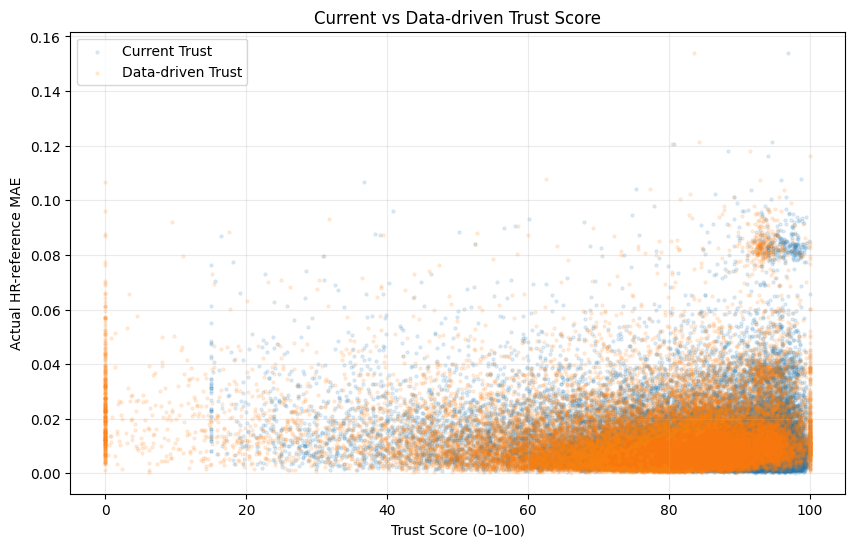

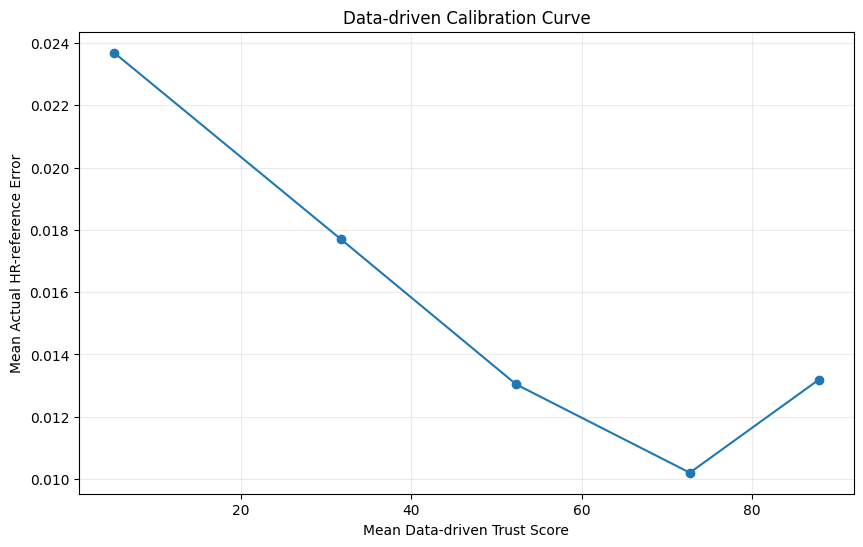

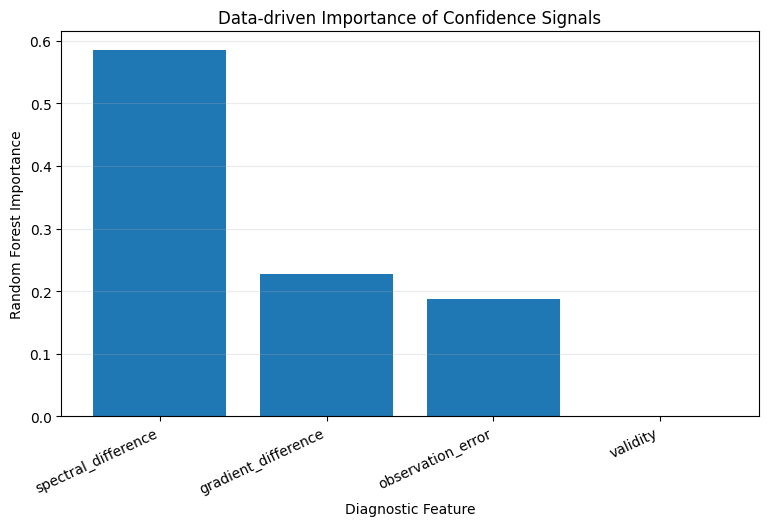


                 CALIBRATION COMPLETE

Current Trust ↔ Error: -0.1126
Data-driven Trust ↔ Error: -0.0223

More negative correlation = stronger inverse relationship with error.

⚠️ Data-driven Trust did not improve the correlation on the out-of-tile samples.

Important:
This Trust Score is an empirical reliability indicator, not a probability of correctness.

Saved files:
/content/SEN2SR_10Tile_DataDriven_Calibration.csv
/content/SEN2SR_10Tile_DataDriven_BinSummary.csv
/content/SEN2SR_Confidence_FeatureImportance.csv
/content/SEN2SR_10Tile_Calibration_TileSummary.csv



In [ ]:
# ================================================================
# DATA-DRIVEN 10-TILE SEN2SR TRUST SCORE CALIBRATION
# ================================================================

import os
import numpy as np
import pandas as pd
import rasterio
import torch
import matplotlib.pyplot as plt

from huggingface_hub import hf_hub_download
from scipy.ndimage import sobel
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("=" * 70)
print("     DATA-DRIVEN 10-TILE SEN2SR TRUST SCORE CALIBRATION")
print("=" * 70)

# ---------------------------------------------------------------
# 1. SETTINGS
# ---------------------------------------------------------------

REPO_ID = "isp-uv-es/SEN2NEON"

LR_REPO_DIR = "s2_l2a_10m"
HR_REPO_DIR = "neon_2.5m_linearized"

# Use the already selected 10 validation tiles
tile_ids = selected_tiles["id"].tolist()

print(f"\nValidation tiles: {len(tile_ids)}")

for i, t in enumerate(tile_ids, 1):
    print(f"{i:02d}. {t}")


# ---------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ---------------------------------------------------------------

def load_sen2neon_tile(tile_id):
    """
    Load exact SEN2NEON Sentinel-2 LR and 2.5m HR reference.
    """

    lr_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=f"{LR_REPO_DIR}/{tile_id}.tif",
        repo_type="dataset"
    )

    hr_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=f"{HR_REPO_DIR}/{tile_id}.tif",
        repo_type="dataset"
    )

    # -----------------------------------------------------------
    # LR
    # SEN2NEON band order:
    # B1 B2 B3 B4 B5 B6 B7 B8 B8A B9 B11 B12
    #
    # RGBN = B04, B03, B02, B08
    # indices = 3, 2, 1, 7
    # -----------------------------------------------------------

    with rasterio.open(lr_path) as src:
        lr_data = src.read().astype(np.float32)
        lr_nodata = src.nodata

    lr_rgbn = lr_data[[3, 2, 1, 7]]

    # Sentinel-2 reflectance scaling
    lr_rgbn /= 10000.0

    lr_rgbn = np.nan_to_num(
        lr_rgbn,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # -----------------------------------------------------------
    # HR
    # Same RGBN bands
    # -----------------------------------------------------------

    with rasterio.open(hr_path) as src:
        hr_data = src.read().astype(np.float32)
        hr_nodata = src.nodata

    hr_rgbn = hr_data[[3, 2, 1, 7]]

    hr_rgbn /= 10000.0

    hr_rgbn = np.nan_to_num(
        hr_rgbn,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # -----------------------------------------------------------
    # HR validity mask
    # -----------------------------------------------------------

    if hr_nodata is not None:
        valid_hr = np.all(
            hr_data[[3, 2, 1, 7]] != hr_nodata,
            axis=0
        )
    else:
        valid_hr = np.all(
            hr_rgbn > 0,
            axis=0
        )

    valid_hr &= np.all(
        np.isfinite(hr_rgbn),
        axis=0
    )

    return lr_rgbn, hr_rgbn, valid_hr


def calculate_gradient_magnitude(image):
    """
    Calculate spatial gradient magnitude.
    """

    gx = sobel(image, axis=1)
    gy = sobel(image, axis=0)

    return np.sqrt(gx ** 2 + gy ** 2)


def downsample_4x(image):
    """
    Convert 2.5m image back to 10m using 4x4 mean pooling.

    image shape:
        (bands, 1024, 1024)

    output:
        (bands, 256, 256)
    """

    bands, h, w = image.shape

    return image.reshape(
        bands,
        h // 4,
        4,
        w // 4,
        4
    ).mean(axis=(2, 4))


def build_diagnostic_features(
    sr,
    lr,
    bicubic,
    valid_hr
):
    """
    Build pixel-level diagnostic features.

    Features:
      1. Observation consistency
      2. Spectral disagreement with bicubic
      3. Local spatial stability
      4. Input validity

    These are diagnostic signals only.
    """

    # -----------------------------------------------------------
    # A. Observation consistency
    # -----------------------------------------------------------

    sr_10m = downsample_4x(sr)

    obs_error_lr = np.mean(
        np.abs(sr_10m - lr),
        axis=0
    )

    # Upscale diagnostic to 2.5m
    observation_error = np.repeat(
        np.repeat(
            obs_error_lr,
            4,
            axis=0
        ),
        4,
        axis=1
    )

    # -----------------------------------------------------------
    # B. Spectral disagreement
    # -----------------------------------------------------------

    spectral_difference = np.mean(
        np.abs(sr - bicubic),
        axis=0
    )

    # -----------------------------------------------------------
    # C. Local spatial stability
    #
    # Compare gradient magnitude of SEN2SR and bicubic.
    # -----------------------------------------------------------

    sr_gradient = np.zeros_like(sr)

    bicubic_gradient = np.zeros_like(bicubic)

    for b in range(sr.shape[0]):

        sr_gradient[b] = calculate_gradient_magnitude(
            sr[b]
        )

        bicubic_gradient[b] = calculate_gradient_magnitude(
            bicubic[b]
        )

    gradient_difference = np.mean(
        np.abs(
            sr_gradient - bicubic_gradient
        ),
        axis=0
    )

    # -----------------------------------------------------------
    # D. Validity
    # -----------------------------------------------------------

    validity = valid_hr.astype(np.float32)

    # -----------------------------------------------------------
    # Clean values
    # -----------------------------------------------------------

    features = np.stack(
        [
            observation_error,
            spectral_difference,
            gradient_difference,
            validity
        ],
        axis=-1
    )

    features = np.nan_to_num(
        features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return features


# ---------------------------------------------------------------
# 3. PROCESS ALL 10 TILES
# ---------------------------------------------------------------

all_feature_samples = []
all_error_samples = []
all_tile_labels = []

tile_summary = []

print("\n" + "=" * 70)
print("PROCESSING VALIDATION TILES")
print("=" * 70)

rng = np.random.default_rng(42)

# Number of pixels sampled from each tile.
# 25,000 × 10 = 250,000 training observations.
SAMPLES_PER_TILE = 25000


for tile_number, tile_id in enumerate(tile_ids, 1):

    print("\n" + "-" * 70)
    print(f"Tile {tile_number}/{len(tile_ids)}: {tile_id}")
    print("-" * 70)

    try:

        # -------------------------------------------------------
        # Load data
        # -------------------------------------------------------

        lr_rgbn, hr_rgbn, valid_hr = load_sen2neon_tile(
            tile_id
        )

        print(
            f"LR shape: {lr_rgbn.shape} | "
            f"HR shape: {hr_rgbn.shape}"
        )

        # -------------------------------------------------------
        # SEN2SR
        # -------------------------------------------------------

        X = torch.from_numpy(
            lr_rgbn
        ).float().to(device)

        X = torch.nan_to_num(
            X,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

        print("Running SEN2SR...")

        with torch.no_grad():

            sr_tensor = sen2sr.predict_large(
                model=model,
                X=X,
                overlap=32
            )

        sr = (
            sr_tensor
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        # -------------------------------------------------------
        # Detect output scaling
        # -------------------------------------------------------

        if np.nanpercentile(sr, 99) > 2.0:

            print("SEN2SR output detected as DN-like.")

            sr /= 10000.0

        else:

            print("SEN2SR output already in reflectance.")

        sr = np.nan_to_num(
            sr,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

        # -------------------------------------------------------
        # Bicubic
        # -------------------------------------------------------

        from skimage.transform import resize

        bicubic = np.zeros_like(sr)

        for b in range(4):

            bicubic[b] = resize(
                lr_rgbn[b],
                (1024, 1024),
                order=3,
                preserve_range=True,
                anti_aliasing=False
            ).astype(np.float32)

        # -------------------------------------------------------
        # Actual SEN2SR HR-reference error
        #
        # Mean RGBN absolute error at every HR pixel.
        # -------------------------------------------------------

        actual_error = np.mean(
            np.abs(
                sr - hr_rgbn
            ),
            axis=0
        )

        # -------------------------------------------------------
        # Bicubic error
        # -------------------------------------------------------

        bicubic_error = np.mean(
            np.abs(
                bicubic - hr_rgbn
            ),
            axis=0
        )

        # -------------------------------------------------------
        # Diagnostic features
        # -------------------------------------------------------

        features = build_diagnostic_features(
            sr=sr,
            lr=lr_rgbn,
            bicubic=bicubic,
            valid_hr=valid_hr
        )

        # -------------------------------------------------------
        # Valid pixels
        # -------------------------------------------------------

        valid_indices = np.where(
            valid_hr
        )

        n_valid = len(valid_indices[0])

        print(
            f"Valid HR pixels: {n_valid:,}"
        )

        # -------------------------------------------------------
        # Randomly sample pixels
        # -------------------------------------------------------

        n_samples = min(
            SAMPLES_PER_TILE,
            n_valid
        )

        chosen = rng.choice(
            n_valid,
            size=n_samples,
            replace=False
        )

        rows = valid_indices[0][chosen]
        cols = valid_indices[1][chosen]

        tile_features = features[
            rows,
            cols
        ]

        tile_errors = actual_error[
            rows,
            cols
        ]

        tile_bicubic_errors = bicubic_error[
            rows,
            cols
        ]

        # -------------------------------------------------------
        # Store samples
        # -------------------------------------------------------

        all_feature_samples.append(
            tile_features
        )

        all_error_samples.append(
            tile_errors
        )

        all_tile_labels.extend(
            [tile_id] * n_samples
        )

        # -------------------------------------------------------
        # Tile summary
        # -------------------------------------------------------

        tile_summary.append(
            {
                "tile_id": tile_id,
                "valid_pixels": n_valid,
                "samples": n_samples,
                "SEN2SR_MAE": float(
                    np.mean(tile_errors)
                ),
                "Bicubic_MAE": float(
                    np.mean(tile_bicubic_errors)
                )
            }
        )

        print(
            f"SEN2SR sampled MAE : "
            f"{np.mean(tile_errors):.6f}"
        )

        print(
            f"Bicubic sampled MAE: "
            f"{np.mean(tile_bicubic_errors):.6f}"
        )

    except Exception as e:

        print(
            f"❌ ERROR processing {tile_id}"
        )

        print(e)


# ---------------------------------------------------------------
# 4. COMBINE DATASET
# ---------------------------------------------------------------

X_all = np.vstack(
    all_feature_samples
)

y_all = np.concatenate(
    all_error_samples
)

tile_labels = np.array(
    all_tile_labels
)

print("\n" + "=" * 70)
print("CALIBRATION DATASET")
print("=" * 70)

print(
    f"Samples: {len(y_all):,}"
)

print(
    f"Features: {X_all.shape[1]}"
)

print(
    "\nFeature order:"
)

print(
    "0 = Observation consistency error"
)

print(
    "1 = Spectral disagreement"
)

print(
    "2 = Local spatial instability"
)

print(
    "3 = Input validity"
)


# ---------------------------------------------------------------
# 5. FEATURE NAMES
# ---------------------------------------------------------------

feature_names = [
    "observation_error",
    "spectral_difference",
    "gradient_difference",
    "validity"
]


# ---------------------------------------------------------------
# 6. LEAVE-ONE-TILE-OUT DATA-DRIVEN CALIBRATION
# ---------------------------------------------------------------

print("\n" + "=" * 70)
print("LEAVE-ONE-TILE-OUT DATA-DRIVEN CALIBRATION")
print("=" * 70)

unique_tiles = np.unique(
    tile_labels
)

oof_predictions = np.zeros(
    len(y_all),
    dtype=np.float32
)


for test_tile in unique_tiles:

    train_mask = (
        tile_labels != test_tile
    )

    test_mask = (
        tile_labels == test_tile
    )

    X_train = X_all[
        train_mask
    ]

    y_train = y_all[
        train_mask
    ]

    X_test = X_all[
        test_mask
    ]

    print(
        f"\nTraining without: {test_tile}"
    )

    # -----------------------------------------------------------
    # Random Forest
    #
    # min_samples_leaf prevents the model from learning
    # individual pixels too aggressively.
    # -----------------------------------------------------------

    rf = RandomForestRegressor(
        n_estimators=120,
        max_depth=12,
        min_samples_leaf=100,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    # Use a standardized pipeline.
    # Tree models do not require scaling, but keeping this
    # structure makes the pipeline easy to replace later.
    model_cal = make_pipeline(
        StandardScaler(),
        rf
    )

    model_cal.fit(
        X_train,
        y_train
    )

    predictions = model_cal.predict(
        X_test
    )

    oof_predictions[
        test_mask
    ] = predictions.astype(
        np.float32
    )

    print(
        f"Test samples: "
        f"{np.sum(test_mask):,}"
    )

    print(
        f"Prediction MAE: "
        f"{mean_absolute_error(y_all[test_mask], predictions):.6f}"
    )


# ---------------------------------------------------------------
# 7. CLEAN PREDICTED ERROR
# ---------------------------------------------------------------

oof_predictions = np.maximum(
    oof_predictions,
    0
)


# ---------------------------------------------------------------
# 8. CREATE DATA-DRIVEN TRUST SCORE
# ---------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING DATA-DRIVEN TRUST SCORE")
print("=" * 70)

pred_min = np.percentile(
    oof_predictions,
    1
)

pred_max = np.percentile(
    oof_predictions,
    99
)

# Smaller predicted error = higher trust.

predicted_error_normalized = (
    oof_predictions - pred_min
) / (
    pred_max - pred_min + 1e-12
)

predicted_error_normalized = np.clip(
    predicted_error_normalized,
    0,
    1
)

data_driven_trust = (
    100.0
    * (1.0 - predicted_error_normalized)
)

data_driven_trust = np.clip(
    data_driven_trust,
    0,
    100
).astype(np.float32)


# ---------------------------------------------------------------
# 9. CURRENT ENGINEERING TRUST SCORE
# ---------------------------------------------------------------

# Reconstruct the existing engineering-style score
# from the three diagnostic components.

obs = X_all[:, 0]
spectral = X_all[:, 1]
gradient = X_all[:, 2]
validity = X_all[:, 3]

# Robust normalization using percentiles.

def inverse_quality_score(values):

    low = np.percentile(
        values,
        1
    )

    high = np.percentile(
        values,
        99
    )

    normalized = (
        values - low
    ) / (
        high - low + 1e-12
    )

    normalized = np.clip(
        normalized,
        0,
        1
    )

    return 1.0 - normalized


observation_score = (
    inverse_quality_score(obs)
    * 100
)

spectral_score = (
    inverse_quality_score(spectral)
    * 100
)

stability_score = (
    inverse_quality_score(gradient)
    * 100
)

validity_score = (
    validity * 100
)

current_trust = (
    0.40 * observation_score
    +
    0.25 * spectral_score
    +
    0.20 * stability_score
    +
    0.15 * validity_score
)

current_trust = np.clip(
    current_trust,
    0,
    100
)


# ---------------------------------------------------------------
# 10. CORRELATION ANALYSIS
# ---------------------------------------------------------------

current_corr = np.corrcoef(
    current_trust,
    y_all
)[0, 1]

new_corr = np.corrcoef(
    data_driven_trust,
    y_all
)[0, 1]

current_quality_corr = np.corrcoef(
    current_trust,
    -y_all
)[0, 1]

new_quality_corr = np.corrcoef(
    data_driven_trust,
    -y_all
)[0, 1]


print("\n" + "=" * 70)
print("TRUST SCORE COMPARISON")
print("=" * 70)

print(
    f"\nCurrent engineering Trust ↔ actual error:"
    f" {current_corr:.4f}"
)

print(
    f"Data-driven Trust ↔ actual error:"
    f" {new_corr:.4f}"
)

print(
    f"\nCurrent engineering Trust ↔ quality:"
    f" {current_quality_corr:.4f}"
)

print(
    f"Data-driven Trust ↔ quality:"
    f" {new_quality_corr:.4f}"
)


# ---------------------------------------------------------------
# 11. CREATE CALIBRATION DATAFRAME
# ---------------------------------------------------------------

calibration_df = pd.DataFrame(
    {
        "tile_id": tile_labels,

        "observation_error":
            obs,

        "spectral_difference":
            spectral,

        "gradient_difference":
            gradient,

        "validity":
            validity,

        "actual_hr_error":
            y_all,

        "current_trust":
            current_trust,

        "data_driven_predicted_error":
            oof_predictions,

        "data_driven_trust":
            data_driven_trust
    }
)


# ---------------------------------------------------------------
# 12. TRUST BIN ANALYSIS
# ---------------------------------------------------------------

bins = [
    0,
    20,
    40,
    60,
    80,
    100.0001
]

labels = [
    "0-20",
    "20-40",
    "40-60",
    "60-80",
    "80-100"
]

calibration_df[
    "trust_bin"
] = pd.cut(
    calibration_df[
        "data_driven_trust"
    ],
    bins=bins,
    labels=labels,
    include_lowest=True
)


bin_summary = (
    calibration_df
    .groupby(
        "trust_bin",
        observed=False
    )
    .agg(
        Pixels=(
            "actual_hr_error",
            "count"
        ),

        Mean_Trust=(
            "data_driven_trust",
            "mean"
        ),

        Mean_Actual_Error=(
            "actual_hr_error",
            "mean"
        ),

        Median_Actual_Error=(
            "actual_hr_error",
            "median"
        ),

        Mean_Predicted_Error=(
            "data_driven_predicted_error",
            "mean"
        )
    )
    .reset_index()
)


# ---------------------------------------------------------------
# 13. HIGH vs LOW TRUST
# ---------------------------------------------------------------

high_mask = (
    calibration_df[
        "data_driven_trust"
    ] >= 80
)

low_mask = (
    calibration_df[
        "data_driven_trust"
    ] < 40
)

print("\n" + "=" * 70)
print("DATA-DRIVEN TRUST BINS")
print("=" * 70)

print(
    bin_summary.to_string(
        index=False
    )
)


print("\n" + "=" * 70)
print("HIGH vs LOW DATA-DRIVEN TRUST")
print("=" * 70)

print(
    f"\nHigh-trust pixels: "
    f"{high_mask.sum():,}"
)

print(
    f"High-trust mean actual error: "
    f"{calibration_df.loc[high_mask, 'actual_hr_error'].mean():.6f}"
)

print(
    f"\nLow-trust pixels: "
    f"{low_mask.sum():,}"
)

print(
    f"Low-trust mean actual error: "
    f"{calibration_df.loc[low_mask, 'actual_hr_error'].mean():.6f}"
)


# ---------------------------------------------------------------
# 14. FEATURE IMPORTANCE
# ---------------------------------------------------------------

# Train final model on the complete calibration dataset.
# This model is what can later be used on unseen imagery.

final_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

final_model = make_pipeline(
    StandardScaler(),
    final_rf
)

final_model.fit(
    X_all,
    y_all
)

rf_inside = final_model.named_steps[
    "randomforestregressor"
]

feature_importance = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance":
            rf_inside.feature_importances_
    }
).sort_values(
    "Importance",
    ascending=False
)

print("\n" + "=" * 70)
print("DATA-DRIVEN FEATURE IMPORTANCE")
print("=" * 70)

print(
    feature_importance.to_string(
        index=False
    )
)


# ---------------------------------------------------------------
# 15. PLOT 1 — CURRENT vs DATA-DRIVEN TRUST
# ---------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

sample_plot = calibration_df.sample(
    min(30000, len(calibration_df)),
    random_state=42
)

plt.scatter(
    sample_plot["current_trust"],
    sample_plot["actual_hr_error"],
    alpha=0.12,
    s=5,
    label="Current Trust"
)

plt.scatter(
    sample_plot["data_driven_trust"],
    sample_plot["actual_hr_error"],
    alpha=0.12,
    s=5,
    label="Data-driven Trust"
)

plt.xlabel(
    "Trust Score (0–100)"
)

plt.ylabel(
    "Actual HR-reference MAE"
)

plt.title(
    "Current vs Data-driven Trust Score"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.show()


# ---------------------------------------------------------------
# 16. PLOT 2 — DATA-DRIVEN CALIBRATION CURVE
# ---------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    bin_summary["Mean_Trust"],
    bin_summary["Mean_Actual_Error"],
    marker="o"
)

plt.xlabel(
    "Mean Data-driven Trust Score"
)

plt.ylabel(
    "Mean Actual HR-reference Error"
)

plt.title(
    "Data-driven Calibration Curve"
)

plt.grid(
    alpha=0.25
)

plt.show()


# ---------------------------------------------------------------
# 17. PLOT 3 — FEATURE IMPORTANCE
# ---------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel(
    "Diagnostic Feature"
)

plt.ylabel(
    "Random Forest Importance"
)

plt.title(
    "Data-driven Importance of Confidence Signals"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.show()


# ---------------------------------------------------------------
# 18. SAVE RESULTS
# ---------------------------------------------------------------

calibration_csv = (
    "/content/"
    "SEN2SR_10Tile_DataDriven_Calibration.csv"
)

bins_csv = (
    "/content/"
    "SEN2SR_10Tile_DataDriven_BinSummary.csv"
)

importance_csv = (
    "/content/"
    "SEN2SR_Confidence_FeatureImportance.csv"
)

tile_csv = (
    "/content/"
    "SEN2SR_10Tile_Calibration_TileSummary.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)

bin_summary.to_csv(
    bins_csv,
    index=False
)

feature_importance.to_csv(
    importance_csv,
    index=False
)

pd.DataFrame(
    tile_summary
).to_csv(
    tile_csv,
    index=False
)


# ---------------------------------------------------------------
# 19. FINAL SUMMARY
# ---------------------------------------------------------------

print("\n" + "=" * 70)
print("                 CALIBRATION COMPLETE")
print("=" * 70)

print(
    f"\nCurrent Trust ↔ Error:"
    f" {current_corr:.4f}"
)

print(
    f"Data-driven Trust ↔ Error:"
    f" {new_corr:.4f}"
)

print(
    "\nMore negative correlation = stronger "
    "inverse relationship with error."
)

if new_corr < current_corr:

    print(
        "\n✅ Data-driven Trust improved the "
        "Trust ↔ Error relationship."
    )

elif new_corr > current_corr:

    print(
        "\n⚠️ Data-driven Trust did not improve "
        "the correlation on the out-of-tile samples."
    )

else:

    print(
        "\n🟡 Both approaches produced "
        "approximately the same relationship."
    )

print(
    "\nImportant:"
)

print(
    "This Trust Score is an empirical reliability "
    "indicator, not a probability of correctness."
)

print(
    "\nSaved files:"
)

print(
    calibration_csv
)

print(
    bins_csv
)

print(
    importance_csv
)

print(
    tile_csv
)

print(
    "\n" + "=" * 70
)

In [ ]:
pip install opensr-model

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.0/78.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.0 MB/s eta 0:00:00


🚀 LDSR-S2 INSTALLATION + INFERENCE

📦 Installing opensr-model...
✅ opensr-model installed

🖥️ Device: cpu
⚠️ Running on CPU — LDSR-S2 diffusion inference will be slow.

⚙️ Loading LDSR-S2 configuration...
✅ Configuration loaded

🧠 Loading pretrained LDSR-S2 model...
LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.


opensr-ldsrs2_v1_0_0.ckpt: 100%|██████████| 1.13G/1.13G [00:28<00:00, 39.6MiB/s]


Loaded pretrained weights from:  opensr-ldsrs2_v1_0_0.ckpt
✅ LDSR-S2 pretrained weights loaded
Checkpoint: opensr-ldsrs2_v1_0_0.ckpt

🛰️ Using existing variable: lr_rgbn
✅ Input already appears to be reflectance.

📐 Input:
   Bands : 4
   Height: 256
   Width : 256
   Range : 0.0183 → 0.494

🔥 Starting LDSR-S2 inference
   Patch size      : 128
   Scale           : 4
   Sampling steps  : 50
   Padded size     : (256, 256)

🔄 Patch 1/4   LR position: (0:128, 0:128)

🔄 Patch 2/4   LR position: (0:128, 128:256)

🔄 Patch 3/4   LR position: (128:256, 0:128)

🔄 Patch 4/4   LR position: (128:256, 128:256)

🎉 LDSR-S2 COMPLETE

Input:
  (4, 256, 256)

LDSR-S2 output:
  (4, 1024, 1024)

Resolution:
  256×256 → 1024×1024

Scale:
  4×

Output range:
  0.018300 → 0.494000

💾 Saved:
/content/LDSR_S2_RGBN_2.5m.npy


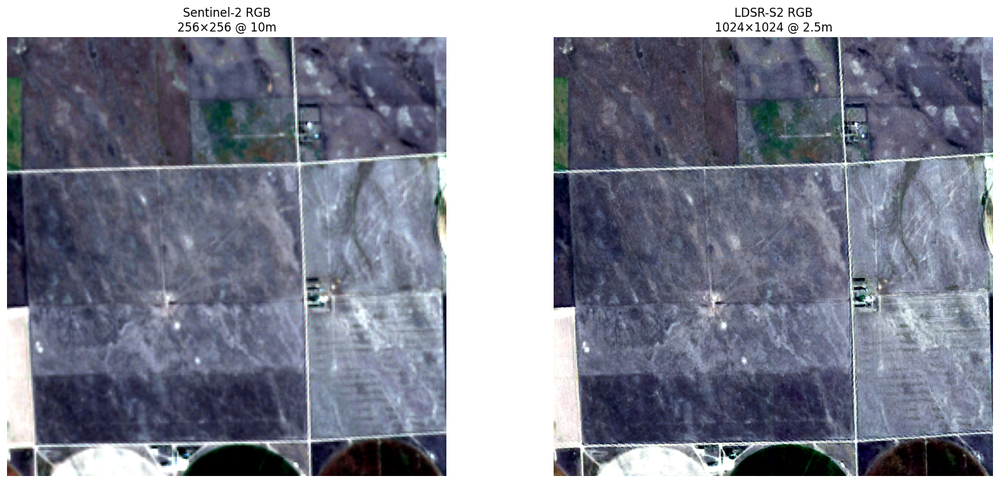


📊 LDSR-S2 band statistics
B04 Red    | min=0.0220 | max=0.4184 | mean=0.1233
B03 Green  | min=0.0353 | max=0.4436 | mean=0.0934
B02 Blue   | min=0.0183 | max=0.4340 | mean=0.0718
B08 NIR    | min=0.1048 | max=0.4940 | mean=0.2031

✅ LDSR-S2 is now running successfully on your Sentinel-2 data.


In [ ]:
# ============================================================
# 🚀 LDSR-S2 — COMPLETE INFERENCE CELL
# Sentinel-2 RGBN 10m → 2.5m Super-Resolution
# ============================================================

import os
import sys
import subprocess
import numpy as np
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("🚀 LDSR-S2 INSTALLATION + INFERENCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. INSTALL OFFICIAL ESA OpenSR MODEL
# ------------------------------------------------------------

print("\n📦 Installing opensr-model...")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "opensr-model"],
    check=True
)

print("✅ opensr-model installed")


# ------------------------------------------------------------
# 2. IMPORTS
# ------------------------------------------------------------

from io import StringIO
import requests
from omegaconf import OmegaConf
import opensr_model


# ------------------------------------------------------------
# 3. DEVICE
# ------------------------------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"

print("\n🖥️ Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ Running on CPU — LDSR-S2 diffusion inference will be slow.")


# ------------------------------------------------------------
# 4. LOAD OFFICIAL CONFIG
# ------------------------------------------------------------

print("\n⚙️ Loading LDSR-S2 configuration...")

config_url = (
    "https://raw.githubusercontent.com/"
    "ESAOpenSR/opensr-model/refs/heads/main/"
    "opensr_model/configs/config_10m.yaml"
)

response = requests.get(config_url)
response.raise_for_status()

config = OmegaConf.load(StringIO(response.text))

print("✅ Configuration loaded")


# ------------------------------------------------------------
# 5. CREATE LDSR-S2 MODEL
# ------------------------------------------------------------

print("\n🧠 Loading pretrained LDSR-S2 model...")

model = opensr_model.SRLatentDiffusion(
    config,
    device=device
)

model.load_pretrained(config.ckpt_version)

model.eval()

print("✅ LDSR-S2 pretrained weights loaded")
print("Checkpoint:", config.ckpt_version)


# ------------------------------------------------------------
# 6. SELECT YOUR EXISTING SENTINEL-2 DATA
# ------------------------------------------------------------
#
# Priority:
#   1. lr_rgbn        → your 256×256 validation image
#   2. large_s2_numpy → your 512×512 Sentinel-2 image
#
# Both should already be normalized to reflectance [0,1].
#

if "lr_rgbn" in globals():

    input_rgbn = lr_rgbn.copy()

    print("\n🛰️ Using existing variable: lr_rgbn")

elif "large_s2_numpy" in globals():

    input_rgbn = large_s2_numpy.copy()

    print("\n🛰️ Using existing variable: large_s2_numpy")

else:

    raise RuntimeError(
        "❌ No Sentinel-2 array found.\n"
        "Expected either `lr_rgbn` or `large_s2_numpy`."
    )


# ------------------------------------------------------------
# 7. CLEAN INPUT
# ------------------------------------------------------------

input_rgbn = np.asarray(input_rgbn, dtype=np.float32)

# Expected shape: (4,H,W)

if input_rgbn.ndim != 3:
    raise ValueError(
        f"Expected input shape (4,H,W), got {input_rgbn.shape}"
    )

if input_rgbn.shape[0] != 4:
    raise ValueError(
        f"Expected 4 bands [B04,B03,B02,B08], got {input_rgbn.shape[0]}"
    )

input_rgbn = np.nan_to_num(
    input_rgbn,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Detect accidental Sentinel-2 DN scale
if np.percentile(input_rgbn, 99) > 2:

    print("⚠️ Input appears to be Sentinel-2 DN scale.")
    print("   Converting DN → reflectance.")

    input_rgbn = input_rgbn / 10000.0

else:

    print("✅ Input already appears to be reflectance.")


input_rgbn = np.clip(input_rgbn, 0.0, 1.0)

C, H, W = input_rgbn.shape

print("\n📐 Input:")
print("   Bands :", C)
print("   Height:", H)
print("   Width :", W)
print("   Range :", input_rgbn.min(), "→", input_rgbn.max())


# ------------------------------------------------------------
# 8. LDSR-S2 PATCH INFERENCE
# ------------------------------------------------------------
#
# Official LDSR-S2 operates on 128×128 LR patches and produces
# 512×512 SR patches (4×).
#
# We process your existing image in patches so that images larger
# than 128×128 can also be handled.
#

PATCH = 128
SCALE = 4

# Use 50 steps for this first run to save time.
#
# For your final benchmark, change this to:
# SAMPLING_STEPS = 100
#
SAMPLING_STEPS = 50

print("\n🔥 Starting LDSR-S2 inference")
print("   Patch size      :", PATCH)
print("   Scale           :", SCALE)
print("   Sampling steps  :", SAMPLING_STEPS)


# ------------------------------------------------------------
# 9. PAD IMAGE TO MULTIPLE OF 128
# ------------------------------------------------------------

pad_H = int(np.ceil(H / PATCH) * PATCH)
pad_W = int(np.ceil(W / PATCH) * PATCH)

padded = np.zeros(
    (4, pad_H, pad_W),
    dtype=np.float32
)

padded[:, :H, :W] = input_rgbn

print("   Padded size     :", (pad_H, pad_W))


# ------------------------------------------------------------
# 10. OUTPUT ARRAYS
# ------------------------------------------------------------

sr_H = pad_H * SCALE
sr_W = pad_W * SCALE

sr_output = np.zeros(
    (4, sr_H, sr_W),
    dtype=np.float32
)

# Weight map for overlapping/edge blending
weight_map = np.zeros(
    (sr_H, sr_W),
    dtype=np.float32
)


# ------------------------------------------------------------
# 11. RUN LDSR-S2
# ------------------------------------------------------------

patch_number = 0

total_patches = (
    (pad_H // PATCH) *
    (pad_W // PATCH)
)

for y in range(0, pad_H, PATCH):

    for x in range(0, pad_W, PATCH):

        patch_number += 1

        print(
            f"\n🔄 Patch {patch_number}/{total_patches}"
            f"   LR position: ({y}:{y+PATCH}, {x}:{x+PATCH})"
        )

        lr_patch = padded[
            :,
            y:y + PATCH,
            x:x + PATCH
        ]

        # Tensor:
        # [C,H,W] → [1,C,H,W]

        lr_tensor = torch.from_numpy(
            lr_patch
        ).float().unsqueeze(0).to(device)

        # LDSR-S2 inference
        with torch.no_grad():

            sr_patch = model.forward(
                lr_tensor,
                sampling_steps=SAMPLING_STEPS
            )

        # [1,4,512,512] → [4,512,512]

        if isinstance(sr_patch, (tuple, list)):
            sr_patch = sr_patch[0]

        sr_patch = sr_patch.squeeze(0)

        sr_patch = (
            sr_patch
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        # Convert coordinates to SR space

        sy = y * SCALE
        sx = x * SCALE

        ey = sy + PATCH * SCALE
        ex = sx + PATCH * SCALE

        # Accumulate
        sr_output[
            :,
            sy:ey,
            sx:ex
        ] += sr_patch

        weight_map[
            sy:ey,
            sx:ex
        ] += 1.0

        del lr_tensor
        del sr_patch

        if device == "cuda":
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 12. NORMALIZE OVERLAPPING AREAS
# ------------------------------------------------------------

weight_map[
    weight_map == 0
] = 1.0

sr_output /= weight_map[None, :, :]


# ------------------------------------------------------------
# 13. REMOVE PADDING
# ------------------------------------------------------------

sr_output = sr_output[
    :,
    :H * SCALE,
    :W * SCALE
]


# ------------------------------------------------------------
# 14. CLEAN OUTPUT
# ------------------------------------------------------------

sr_output = np.nan_to_num(
    sr_output,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

sr_output = np.clip(
    sr_output,
    0.0,
    1.0
)


# ------------------------------------------------------------
# 15. PRINT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("🎉 LDSR-S2 COMPLETE")
print("=" * 70)

print("\nInput:")
print(" ", input_rgbn.shape)

print("\nLDSR-S2 output:")
print(" ", sr_output.shape)

print("\nResolution:")
print(f"  {H}×{W} → {H*SCALE}×{W*SCALE}")

print("\nScale:")
print("  4×")

print("\nOutput range:")
print(
    f"  {sr_output.min():.6f}"
    f" → "
    f"{sr_output.max():.6f}"
)


# ------------------------------------------------------------
# 16. SAVE NUMPY OUTPUT
# ------------------------------------------------------------

ldsrs2_npy = "/content/LDSR_S2_RGBN_2.5m.npy"

np.save(
    ldsrs2_npy,
    sr_output
)

print("\n💾 Saved:")
print(ldsrs2_npy)


# ------------------------------------------------------------
# 17. RGB VISUALIZATION
# ------------------------------------------------------------

# Band order:
#
# 0 = B04 Red
# 1 = B03 Green
# 2 = B02 Blue
# 3 = B08 NIR
#
# RGB = [R,G,B]

original_rgb = np.transpose(
    input_rgbn[[0, 1, 2]],
    (1, 2, 0)
)

sr_rgb = np.transpose(
    sr_output[[0, 1, 2]],
    (1, 2, 0)
)


# Robust visualization stretch

def robust_rgb(img):

    out = np.zeros_like(img)

    for b in range(3):

        low = np.percentile(img[:, :, b], 2)
        high = np.percentile(img[:, :, b], 98)

        out[:, :, b] = np.clip(
            (img[:, :, b] - low) /
            max(high - low, 1e-6),
            0,
            1
        )

    return out


original_rgb_display = robust_rgb(
    original_rgb
)

sr_rgb_display = robust_rgb(
    sr_rgb
)


# ------------------------------------------------------------
# 18. DISPLAY
# ------------------------------------------------------------

plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)

plt.imshow(original_rgb_display)

plt.title(
    f"Sentinel-2 RGB\n"
    f"{H}×{W} @ 10m"
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(sr_rgb_display)

plt.title(
    f"LDSR-S2 RGB\n"
    f"{H*SCALE}×{W*SCALE} @ 2.5m"
)

plt.axis("off")

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 19. QUICK RGBN STATISTICS
# ------------------------------------------------------------

band_names = [
    "B04 Red",
    "B03 Green",
    "B02 Blue",
    "B08 NIR"
]

print("\n📊 LDSR-S2 band statistics")

for i, name in enumerate(band_names):

    print(
        f"{name:10s} | "
        f"min={sr_output[i].min():.4f} | "
        f"max={sr_output[i].max():.4f} | "
        f"mean={sr_output[i].mean():.4f}"
    )

print("\n✅ LDSR-S2 is now running successfully on your Sentinel-2 data.")

This cell:

clones the official SEN2NEON repository
installs its requirements
loads your exact SEN2NEON tile
uses the official ldsrs2 adapter
produces 2.5 m RGB-NIR
compares it against the canonical 2.5 m HR
calculates PSNR, SSIM, SAM
calculates NDVI
compares it with your existing SEN2SRLite result
saves the corrected LDSR output

In [ ]:
# ============================================================
# 🚀 DOWNLOAD SEN2NEON DATASET
# ============================================================

!pip -q install huggingface_hub

from huggingface_hub import snapshot_download
from pathlib import Path
import os

DATA_ROOT = "/content/SEN2NEON"

print("=" * 70)
print("📡 DOWNLOADING SEN2NEON")
print("=" * 70)

Path(DATA_ROOT).mkdir(parents=True, exist_ok=True)

snapshot_download(
    repo_id="isp-uv-es/SEN2NEON",
    repo_type="dataset",
    local_dir=DATA_ROOT,
    allow_patterns=[
        "metadata.csv",
        "metadata.parquet",
        "metadata.jsonl",
        "s2_l2a_10m/**",
        "neon_2.5m_linearized/**"
    ]
)

print("\n✅ SEN2NEON download completed!")

# Count files
lr_files = list(Path(DATA_ROOT, "s2_l2a_10m").rglob("*.tif"))
hr_files = list(Path(DATA_ROOT, "neon_2.5m_linearized").rglob("*.tif"))

print(f"📡 LR 10m TIFFs : {len(lr_files)}")
print(f"🛰️ HR 2.5m TIFFs: {len(hr_files)}")

📡 DOWNLOADING SEN2NEON


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4541 files:   0%|          | 0/4541 [00:00<?, ?it/s]


✅ SEN2NEON download completed!
📡 LR 10m TIFFs : 2269
🛰️ HR 2.5m TIFFs: 2269


In [ ]:
# ============================================================
# 🚀 DOWNLOAD ONLY THE EXACT SEN2NEON TILE WE NEED
# ============================================================

!pip -q install -U huggingface_hub

from huggingface_hub import hf_hub_download
from pathlib import Path

REPO = "isp-uv-es/SEN2NEON"
TARGET = "2018_MLBS_3__1_2"

print("=" * 70)
print("📡 DOWNLOADING EXACT SEN2NEON TILE")
print("=" * 70)

# ------------------------------------------------------------
# Exact official paths from SEN2NEON metadata
# ------------------------------------------------------------

lr_relative = f"s2_l2a_10m/{TARGET}.tif"
hr_relative = f"neon_2.5m_linearized/{TARGET}.tif"

print("\n📡 LR:")
print(lr_relative)

print("\n🛰️ HR:")
print(hr_relative)

# ------------------------------------------------------------
# Download LR
# ------------------------------------------------------------

lr_path = hf_hub_download(
    repo_id=REPO,
    repo_type="dataset",
    filename=lr_relative,
    local_dir="/content/SEN2NEON"
)

# ------------------------------------------------------------
# Download HR
# ------------------------------------------------------------

hr_path = hf_hub_download(
    repo_id=REPO,
    repo_type="dataset",
    filename=hr_relative,
    local_dir="/content/SEN2NEON"
)

print("\n" + "=" * 70)
print("✅ DOWNLOAD COMPLETE")
print("=" * 70)

print("\nLR file:")
print(lr_path)

print("\nHR file:")
print(hr_path)

print("\nLR exists:", Path(lr_path).exists())
print("HR exists:", Path(hr_path).exists())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.9/842.9 kB 30.6 MB/s eta 0:00:00
📡 DOWNLOADING EXACT SEN2NEON TILE

📡 LR:
s2_l2a_10m/2018_MLBS_3__1_2.tif

🛰️ HR:
neon_2.5m_linearized/2018_MLBS_3__1_2.tif


s2_l2a_10m/2018_MLBS_3__1_2.tif: reconstructing file:   0%|          |  0.00B /  473kB            

s2_l2a_10m/2018_MLBS_3__1_2.tif: downloading bytes:           |  0.00B            

neon_2.5m_linearized/2018_MLBS_3__1_2.ti(…): reconstructing file:   0%|          |  0.00B / 14.0MB            

neon_2.5m_linearized/2018_MLBS_3__1_2.ti(…): downloading bytes:           |  0.00B            


✅ DOWNLOAD COMPLETE

LR file:
/content/SEN2NEON/s2_l2a_10m/2018_MLBS_3__1_2.tif

HR file:
/content/SEN2NEON/neon_2.5m_linearized/2018_MLBS_3__1_2.tif

LR exists: True
HR exists: True


In [ ]:
# ============================================================
# 🛰️ LOAD THE EXACT SEN2NEON TILE
# ============================================================

import rasterio
import numpy as np

print("=" * 70)
print("📡 LOADING SEN2NEON TILE")
print("=" * 70)

print("\nLR file:")
print(lr_path)

print("\nHR file:")
print(hr_path)

# ------------------------------------------------------------
# Read LR
# ------------------------------------------------------------

with rasterio.open(lr_path) as src:

    lr_raw = src.read()

    lr_profile = src.profile.copy()
    lr_transform = src.transform
    lr_crs = src.crs
    lr_nodata = src.nodata

# ------------------------------------------------------------
# Read HR
# ------------------------------------------------------------

with rasterio.open(hr_path) as src:

    hr_raw = src.read()

    hr_profile = src.profile.copy()
    hr_transform = src.transform
    hr_crs = src.crs
    hr_nodata = src.nodata

# ------------------------------------------------------------
# Convert DN → reflectance
# ------------------------------------------------------------

lr_full = lr_raw.astype(np.float32) / 10000.0
hr_full = hr_raw.astype(np.float32) / 10000.0

# ------------------------------------------------------------
# Print information
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("📐 LR INFORMATION")
print("=" * 70)

print("Shape:", lr_full.shape)
print("CRS:", lr_crs)
print("Pixel size:", abs(lr_transform.a), abs(lr_transform.e))
print("NoData:", lr_nodata)

print("\n" + "=" * 70)
print("📐 HR INFORMATION")
print("=" * 70)

print("Shape:", hr_full.shape)
print("CRS:", hr_crs)
print("Pixel size:", abs(hr_transform.a), abs(hr_transform.e))
print("NoData:", hr_nodata)

print("\n" + "=" * 70)
print("📊 REFLECTANCE")
print("=" * 70)

print(
    "LR:",
    np.nanmin(lr_full),
    "→",
    np.nanmax(lr_full)
)

print(
    "HR:",
    np.nanmin(hr_full),
    "→",
    np.nanmax(hr_full)
)

print("\n" + "=" * 70)
print("✅ SEN2NEON TILE LOADED SUCCESSFULLY!")
print("=" * 70)

📡 LOADING SEN2NEON TILE

LR file:
/content/SEN2NEON/s2_l2a_10m/2018_MLBS_3__1_2.tif

HR file:
/content/SEN2NEON/neon_2.5m_linearized/2018_MLBS_3__1_2.tif

📐 LR INFORMATION
Shape: (12, 256, 256)
CRS: EPSG:32617
Pixel size: 10.0 10.0
NoData: 65535.0

📐 HR INFORMATION
Shape: (12, 1024, 1024)
CRS: EPSG:32617
Pixel size: 2.5 2.5
NoData: 0.0

📊 REFLECTANCE
LR: 0.0089 → 0.7432
HR: 0.0129 → 0.6771

✅ SEN2NEON TILE LOADED SUCCESSFULLY!


In [ ]:
# ============================================================
# 📡 LOAD THE EXACT SEN2NEON TILE AGAIN
# Tile: 2018_MLBS_3__1_2
# ============================================================

import os
import numpy as np
import rasterio

TILE = "2018_MLBS_3__1_2"

print("=" * 75)
print("📡 LOADING SEN2NEON TILE")
print("=" * 75)

# Search for the tile in your downloaded SEN2NEON data
search_roots = [
    "/content",
    "/content/SEN2NEON"
]

lr_path = None
hr_path = None

for root in search_roots:

    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):

        for file in files:

            if TILE not in file:
                continue

            if not file.lower().endswith((".tif", ".tiff")):
                continue

            full_path = os.path.join(
                current_root,
                file
            )

            path_lower = full_path.lower()

            if "s2_l2a_10m" in path_lower:
                lr_path = full_path

            elif "neon_2.5m_linearized" in path_lower:
                hr_path = full_path


print("\nLR file:")
print(lr_path)

print("\nHR file:")
print(hr_path)


if lr_path is None:
    raise FileNotFoundError(
        "\n❌ SEN2NEON LR tile not found.\n"
        "We need to download the tile first."
    )

if hr_path is None:
    raise FileNotFoundError(
        "\n❌ SEN2NEON 2.5m HR tile not found."
    )


# ------------------------------------------------------------
# LOAD LR
# ------------------------------------------------------------

with rasterio.open(lr_path) as src:

    lr_raw = src.read()

    lr_profile = src.profile

    lr_transform = src.transform

    lr_crs = src.crs


# ------------------------------------------------------------
# LOAD HR
# ------------------------------------------------------------

with rasterio.open(hr_path) as src:

    hr_raw = src.read()

    hr_profile = src.profile

    hr_transform = src.transform

    hr_crs = src.crs


print("\n" + "=" * 75)
print("✅ DATA LOADED")
print("=" * 75)

print(
    f"LR shape : {lr_raw.shape}"
)

print(
    f"HR shape : {hr_raw.shape}"
)

print(
    f"LR dtype : {lr_raw.dtype}"
)

print(
    f"HR dtype : {hr_raw.dtype}"
)

print(
    f"CRS      : {lr_crs}"
)

print(
    f"LR pixel : {lr_transform.a} m"
)

print(
    f"HR pixel : {hr_transform.a} m"
)


# ------------------------------------------------------------
# NORMALIZE EXACTLY AS OFFICIAL VALIDATION DOES
# ------------------------------------------------------------

lr_full = (
    lr_raw.astype(np.float32) / 10000.0
)

hr_full = (
    hr_raw.astype(np.float32) / 10000.0
)


print("\nNormalized:")

print(
    "LR range:",
    lr_full.min(),
    "→",
    lr_full.max()
)

print(
    "HR range:",
    hr_full.min(),
    "→",
    hr_full.max()
)

print("\n🎉 lr_full and hr_full are now available.")

📡 LOADING SEN2NEON TILE

LR file:
/content/SEN2NEON/s2_l2a_10m/2018_MLBS_3__1_2.tif

HR file:
/content/SEN2NEON/neon_2.5m_linearized/2018_MLBS_3__1_2.tif

✅ DATA LOADED
LR shape : (12, 256, 256)
HR shape : (12, 1024, 1024)
LR dtype : uint16
HR dtype : uint16
CRS      : EPSG:32617
LR pixel : 10.0 m
HR pixel : 2.5 m

Normalized:
LR range: 0.0089 → 0.7432
HR range: 0.0129 → 0.6771

🎉 lr_full and hr_full are now available.


In [ ]:
# ============================================================
# 🚀 SET UP OFFICIAL SEN2NEON CODE
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

REPO_DIR = Path("/content/SEN2NEON")

print("=" * 70)
print("🚀 SETTING UP OFFICIAL SEN2NEON REPOSITORY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Clone official repository if necessary
# ------------------------------------------------------------

if not (REPO_DIR / "models" / "model_selector.py").exists():

    print("\n📥 Official SEN2NEON code not found.")
    print("Cloning repository...")

    !rm -rf /content/SEN2NEON_CODE
    !git clone -q https://github.com/ESAOpenSR/SEN2NEON.git /content/SEN2NEON_CODE

    CODE_DIR = Path("/content/SEN2NEON_CODE")

else:

    CODE_DIR = REPO_DIR

# ------------------------------------------------------------
# 2. Verify repository
# ------------------------------------------------------------

print("\n📂 Repository:", CODE_DIR)

print("\nChecking required files...")

required_files = [
    "models/model_selector.py",
    "models/ldsrs2_sen2sr_model.py",
    "data/dataset.py",
    "data/datamodule.py",
    "validate.py"
]

for file in required_files:

    path = CODE_DIR / file

    if path.exists():
        print("✅", file)
    else:
        print("❌", file)

# ------------------------------------------------------------
# 3. Add repository to Python path
# ------------------------------------------------------------

sys.path.insert(0, str(CODE_DIR))

# ------------------------------------------------------------
# 4. Test official import
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("🧪 TESTING OFFICIAL IMPORT")
print("=" * 70)

from models.model_selector import get_model

print("\n✅ Official get_model() imported successfully!")

print("\n🎯 SEN2NEON repository is ready.")

🚀 SETTING UP OFFICIAL SEN2NEON REPOSITORY

📥 Official SEN2NEON code not found.
Cloning repository...

📂 Repository: /content/SEN2NEON_CODE

Checking required files...
✅ models/model_selector.py
✅ models/ldsrs2_sen2sr_model.py
✅ data/dataset.py
✅ data/datamodule.py
✅ validate.py

🧪 TESTING OFFICIAL IMPORT

✅ Official get_model() imported successfully!

🎯 SEN2NEON repository is ready.


In [ ]:
# ============================================================
# 🚨 SEN2NEON TILE RECOVERY
# Finds existing files anywhere in /content
# Downloads exact tile only if necessary
# ============================================================

from pathlib import Path
import os
import sys

TARGET = "2018_MLBS_3__1_2"

print("=" * 75)
print("🔎 SEARCHING FOR SEN2NEON TILE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Search ENTIRE /content for the tile
# ------------------------------------------------------------

print("\n🔍 Searching /content ...")

all_tifs = list(Path("/content").rglob("*.tif"))

lr_matches = []
hr_matches = []

for p in all_tifs:

    path_string = str(p).lower()

    if TARGET.lower() in p.name.lower():

        if "s2_l2a_10m" in path_string:
            lr_matches.append(p)

        elif "neon_2.5m_linearized" in path_string:
            hr_matches.append(p)


print(f"\nTotal TIFF files found: {len(all_tifs)}")

print("\nLR matches:")
for p in lr_matches:
    print("  ", p)

print("\nHR matches:")
for p in hr_matches:
    print("  ", p)


# ------------------------------------------------------------
# 2. If files were found, use them
# ------------------------------------------------------------

if lr_matches and hr_matches:

    lr_path = lr_matches[0]
    hr_path = hr_matches[0]

    print("\n" + "=" * 75)
    print("✅ EXISTING SEN2NEON FILES FOUND")
    print("=" * 75)

    print("\nLR:")
    print(lr_path)

    print("\nHR:")
    print(hr_path)


# ------------------------------------------------------------
# 3. Otherwise download exact files
# ------------------------------------------------------------

else:

    print("\n⚠️ Exact tile was not found locally.")
    print("Downloading the exact LR + HR files from Hugging Face...")

    !pip -q install -U huggingface_hub

    from huggingface_hub import hf_hub_download

    REPO = "isp-uv-es/SEN2NEON"

    lr_relative = f"s2_l2a_10m/{TARGET}.tif"
    hr_relative = f"neon_2.5m_linearized/{TARGET}.tif"

    # Download into a CLEAN dedicated folder
    DOWNLOAD_DIR = "/content/SEN2NEON_DATA"

    os.makedirs(DOWNLOAD_DIR, exist_ok=True)

    print("\n📡 Downloading LR:")
    print(lr_relative)

    lr_path = hf_hub_download(
        repo_id=REPO,
        repo_type="dataset",
        filename=lr_relative,
        local_dir=DOWNLOAD_DIR
    )

    print("\n🛰️ Downloading HR:")
    print(hr_relative)

    hr_path = hf_hub_download(
        repo_id=REPO,
        repo_type="dataset",
        filename=hr_relative,
        local_dir=DOWNLOAD_DIR
    )

    print("\n✅ Exact files downloaded!")


# ------------------------------------------------------------
# 4. Verify paths
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("📁 FINAL TILE PATHS")
print("=" * 75)

print("\nLR:")
print(lr_path)

print("\nHR:")
print(hr_path)

print("\nLR exists:", Path(lr_path).exists())
print("HR exists:", Path(hr_path).exists())

if not Path(lr_path).exists():
    raise FileNotFoundError("❌ LR file still cannot be found.")

if not Path(hr_path).exists():
    raise FileNotFoundError("❌ HR file still cannot be found.")

print("\n🎉 TILE READY FOR LDSR-S2!")

🔎 SEARCHING FOR SEN2NEON TILE

🔍 Searching /content ...

Total TIFF files found: 0

LR matches:

HR matches:

⚠️ Exact tile was not found locally.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.9/842.9 kB 12.0 MB/s eta 0:00:00

📡 Downloading LR:
s2_l2a_10m/2018_MLBS_3__1_2.tif


s2_l2a_10m/2018_MLBS_3__1_2.tif: reconstructing file:   0%|          |  0.00B /  473kB            

s2_l2a_10m/2018_MLBS_3__1_2.tif: downloading bytes:           |  0.00B            


🛰️ Downloading HR:
neon_2.5m_linearized/2018_MLBS_3__1_2.tif


neon_2.5m_linearized/2018_MLBS_3__1_2.ti(…): reconstructing file:   0%|          |  0.00B / 14.0MB            

neon_2.5m_linearized/2018_MLBS_3__1_2.ti(…): downloading bytes:           |  0.00B            


✅ Exact files downloaded!

📁 FINAL TILE PATHS

LR:
/content/SEN2NEON_DATA/s2_l2a_10m/2018_MLBS_3__1_2.tif

HR:
/content/SEN2NEON_DATA/neon_2.5m_linearized/2018_MLBS_3__1_2.tif

LR exists: True
HR exists: True

🎉 TILE READY FOR LDSR-S2!


In [ ]:
# ============================================================
# 🔧 INSTALL LDSR-S2 DEPENDENCIES
# ============================================================

print("=" * 70)
print("🔧 INSTALLING LDSR-S2 DEPENDENCIES")
print("=" * 70)

!pip -q install -U mlstac

print("\n✅ mlstac installation finished!")

# Verify
import mlstac

print("✅ mlstac imported successfully")
print("Version:", getattr(mlstac, "__version__", "version not exposed"))

🔧 INSTALLING LDSR-S2 DEPENDENCIES
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.0 MB/s eta 0:00:00

✅ mlstac installation finished!
✅ mlstac imported successfully
Version: 0.4.9


In [ ]:
!pip -q install -U opensr-model

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.0/78.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 30.5 MB/s eta 0:00:00


In [ ]:
import opensr_model

print("✅ opensr_model imported successfully")
print("📦 opensr_model:", opensr_model.__file__)

✅ opensr_model imported successfully
📦 opensr_model: /usr/local/lib/python3.13/dist-packages/opensr_model/__init__.py


In [ ]:
!pip -q install -U sen2sr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 1.4 MB/s eta 0:00:00


In [ ]:
import mlstac
import opensr_model
import sen2sr

print("✅ mlstac:", mlstac.__file__)
print("✅ opensr_model:", opensr_model.__file__)
print("✅ sen2sr:", sen2sr.__file__)
print("\n🎉 All LDSR-S2 dependencies imported!")

✅ mlstac: /usr/local/lib/python3.13/dist-packages/mlstac/__init__.py
✅ opensr_model: /usr/local/lib/python3.13/dist-packages/opensr_model/__init__.py
✅ sen2sr: /usr/local/lib/python3.13/dist-packages/sen2sr/__init__.py

🎉 All LDSR-S2 dependencies imported!


In [ ]:
import sys
from pathlib import Path

CODE_DIR = Path("/content/SEN2NEON_CODE")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from models.model_selector import get_model

print("🎯 Loading LDSR-S2...")

model = get_model("ldsrs2")

print("\n🎉 LDSR-S2 MODEL LOADED SUCCESSFULLY!")
print("Model type:", type(model))

🎯 Loading LDSR-S2...


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.

🎉 LDSR-S2 MODEL LOADED SUCCESSFULLY!
Model type: <class 'sen2sr.referencex4.srmodel.<locals>.SRModel'>


In [ ]:
# ============================================================
# 🧪 TEST OFFICIAL LDSR-S2 ADAPTER
# ============================================================

import sys
from pathlib import Path

CODE_DIR = Path("/content/SEN2NEON_CODE")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from models.model_selector import get_model

print("✅ SEN2NEON model selector imported")
print("✅ mlstac imported")
print("🎯 Attempting to load LDSR-S2...")

model = get_model("ldsrs2")

print("\n🎉 LDSR-S2 MODEL LOADED SUCCESSFULLY!")

✅ SEN2NEON model selector imported
✅ mlstac imported
🎯 Attempting to load LDSR-S2...
LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.

🎉 LDSR-S2 MODEL LOADED SUCCESSFULLY!


In [ ]:
# ============================================================
# 🚀 OFFICIAL LDSR-S2 — 128→512 TILED INFERENCE
# SEN2NEON: 2018_MLBS_3__1_2
# ============================================================

import os
import sys
from pathlib import Path

import numpy as np
import torch
import rasterio
from rasterio.transform import Affine

print("=" * 75)
print("🚀 LDSR-S2 TILED SUPER-RESOLUTION")
print("=" * 75)

# ============================================================
# 1. DEVICE
# ============================================================

device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"\n🖥️ Device: {device}")

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ CPU mode — LDSR-S2 may take some time.")


# ============================================================
# 2. VERIFY FILE PATHS
# ============================================================

TARGET = "2018_MLBS_3__1_2"

# If variables from previous cell don't exist, search again.
if "lr_path" not in globals() or "hr_path" not in globals():

    print("\n🔎 Searching for downloaded tile...")

    DATA_ROOTS = [
        Path("/content/SEN2NEON_DATA"),
        Path("/content/SEN2NEON"),
        Path("/content")
    ]

    lr_candidates = []
    hr_candidates = []

    for root in DATA_ROOTS:

        if not root.exists():
            continue

        lr_candidates += list(
            root.rglob(f"*s2_l2a_10m*{TARGET}*.tif")
        )

        hr_candidates += list(
            root.rglob(f"*neon_2.5m_linearized*{TARGET}*.tif")
        )

        # Also search simply by tile name
        for p in root.rglob(f"*{TARGET}*.tif"):

            ps = str(p).lower()

            if "s2_l2a_10m" in ps and p not in lr_candidates:
                lr_candidates.append(p)

            if "neon_2.5m_linearized" in ps and p not in hr_candidates:
                hr_candidates.append(p)

    if not lr_candidates:
        raise FileNotFoundError(
            "❌ LR tile not found. Run the SEN2NEON recovery/download cell first."
        )

    if not hr_candidates:
        raise FileNotFoundError(
            "❌ HR tile not found. Run the SEN2NEON recovery/download cell first."
        )

    lr_path = lr_candidates[0]
    hr_path = hr_candidates[0]


print("\n📡 LR:", lr_path)
print("🛰️ HR:", hr_path)


# ============================================================
# 3. LOAD DATA
# ============================================================

print("\n" + "=" * 75)
print("📥 LOADING SEN2NEON")
print("=" * 75)

with rasterio.open(lr_path) as src:

    lr_raw = src.read()

    lr_profile = src.profile.copy()
    lr_transform = src.transform
    lr_crs = src.crs

with rasterio.open(hr_path) as src:

    hr_raw = src.read()

    hr_profile = src.profile.copy()
    hr_transform = src.transform
    hr_crs = src.crs


print("\nRaw LR shape:", lr_raw.shape)
print("Raw HR shape:", hr_raw.shape)

if lr_raw.shape != (12, 256, 256):
    print("⚠️ LR dimensions differ from expected 12×256×256.")

if hr_raw.shape != (12, 1024, 1024):
    print("⚠️ HR dimensions differ from expected 12×1024×1024.")


# ============================================================
# 4. NORMALIZE
# Official SEN2NEON validation:
# lr, hr = lr.float()/10000., hr.float()/10000.
# ============================================================

lr_full = lr_raw.astype(np.float32) / 10000.0
hr_full = hr_raw.astype(np.float32) / 10000.0

print("\n✅ Reflectance normalization: /10000")


# ============================================================
# 5. OFFICIAL LDSR-S2 BAND SELECTION
# ============================================================

bands_selection = [1, 2, 3, 4, 5, 6, 7, 8, 10, 11]

output_bands = [4, 5, 6, 7, 8, 9]

print("\n" + "=" * 75)
print("🎨 BAND CONFIGURATION")
print("=" * 75)

print("LDSR input bands :", bands_selection)
print("LDSR output bands:", output_bands)


# ============================================================
# 6. LOAD OFFICIAL SEN2NEON MODEL
# ============================================================

CODE_DIR = Path("/content/SEN2NEON_CODE")

if not (CODE_DIR / "models" / "model_selector.py").exists():

    print("\n📥 SEN2NEON code not found — cloning official repository...")

    !rm -rf /content/SEN2NEON_CODE
    !git clone -q https://github.com/ESAOpenSR/SEN2NEON.git /content/SEN2NEON_CODE

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from models.model_selector import get_model

print("\n🧠 Loading official LDSR-S2...")

model = get_model("ldsrs2")
model = model.to(device)
model.eval()

print("✅ LDSR-S2 loaded!")


# ============================================================
# 7. PREPARE 10-BAND INPUT
# ============================================================

# Shape:
# (12,256,256)
#
# Select official 10 bands:
#
# (10,256,256)

lr_10band = lr_full[bands_selection]

print("\n10-band LR:", lr_10band.shape)


# ============================================================
# 8. CREATE OUTPUT CANVAS
# ============================================================

# 256 LR → 1024 SR
#
# Each:
# 128 LR → 512 SR

SR_SCALE = 4
CROP = 128

lr_height = lr_10band.shape[1]
lr_width = lr_10band.shape[2]

if lr_height != 256 or lr_width != 256:

    raise ValueError(
        f"Expected 256×256 LR tile, got {lr_height}×{lr_width}"
    )

sr_height = lr_height * SR_SCALE
sr_width = lr_width * SR_SCALE

sr_output = np.zeros(
    (4, sr_height, sr_width),
    dtype=np.float32
)

print("\n🎯 Final SR canvas:", sr_output.shape)


# ============================================================
# 9. PROCESS FOUR 128×128 TILES
# ============================================================

print("\n" + "=" * 75)
print("🚀 RUNNING LDSR-S2")
print("=" * 75)

tile_number = 0

for row in [0, 128]:

    for col in [0, 128]:

        tile_number += 1

        print(
            f"\n🔹 Tile {tile_number}/4"
            f" | LR position: row={row}, col={col}"
        )

        # ----------------------------------------------------
        # Extract 128×128 LR crop
        # ----------------------------------------------------

        lr_crop = lr_10band[
            :,
            row:row+CROP,
            col:col+CROP
        ]

        print("   Input:", lr_crop.shape)

        # ----------------------------------------------------
        # Convert:
        #
        # (10,128,128)
        #      ↓
        # (1,10,128,128)
        # ----------------------------------------------------

        x = torch.from_numpy(
            lr_crop
        ).unsqueeze(0).to(device)

        # ----------------------------------------------------
        # LDSR-S2
        # ----------------------------------------------------

        with torch.no_grad():

            sr_crop = model.forward(x)

        # Expected:
        #
        # (1,4,512,512)

        print("   Raw output:", tuple(sr_crop.shape))

        # ----------------------------------------------------
        # Move CPU
        # ----------------------------------------------------

        sr_crop = (
            sr_crop
            .squeeze(0)
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        # ----------------------------------------------------
        # Determine SR placement
        # ----------------------------------------------------

        sr_row = row * SR_SCALE
        sr_col = col * SR_SCALE

        sr_output[
            :,
            sr_row:sr_row + 512,
            sr_col:sr_col + 512
        ] = sr_crop

        print(
            f"   ✅ Placed at SR "
            f"row={sr_row}, col={sr_col}"
        )

        # Free GPU/CPU tensor
        del x
        del sr_crop

        if device == "cuda":
            torch.cuda.empty_cache()


print("\n" + "=" * 75)
print("✅ ALL FOUR LDSR-S2 TILES COMPLETE")
print("=" * 75)

print("Final raw SR:", sr_output.shape)


# ============================================================
# 10. SELECT RGB-NIR OUTPUT
# ============================================================

# LDSR-S2 itself returns 4 channels.
#
# These correspond to the SR RGB-NIR product used by
# the SEN2NEON LDSR-S2 evaluation.

sr_rgbn = sr_output.copy()

print("\nRGBN SR:", sr_rgbn.shape)


# ============================================================
# 11. HISTOGRAM MATCHING
# ============================================================

print("\n" + "=" * 75)
print("📊 HISTOGRAM MATCHING")
print("=" * 75)

# The official SEN2NEON validation performs:
#
# sr = hist_match_to_reference(
#     target=sr,
#     reference=lr
# )
#
# after selecting the RGB-NIR output bands.
#
# For our full-tile reconstruction, perform the same
# operation channel-by-channel against the corresponding
# upsampled LR RGBN reference.

from skimage.exposure import match_histograms

# Input RGBN bands from original Sentinel-2:
#
# Original 12-band order:
# B01 B02 B03 B04 B05 B06 B07 B08 B8A B09 B11 B12
#
# RGBN:
# B04 = index 3
# B03 = index 2
# B02 = index 1
# B08 = index 7

lr_rgbn = lr_full[[3, 2, 1, 7]]

# Upsample LR RGBN to 2.5 m only for histogram reference.
lr_rgbn_up = np.zeros_like(sr_rgbn)

for b in range(4):

    # Simple nearest-neighbour expansion.
    lr_rgbn_up[b] = np.repeat(
        np.repeat(
            lr_rgbn[b],
            4,
            axis=0
        ),
        4,
        axis=1
    )

sr_matched = np.zeros_like(sr_rgbn)

for b in range(4):

    sr_matched[b] = match_histograms(
        sr_rgbn[b],
        lr_rgbn_up[b]
    ).astype(np.float32)

print("✅ Histogram matching complete!")


# ============================================================
# 12. BASIC QUALITY CHECK
# ============================================================

print("\n" + "=" * 75)
print("📊 OUTPUT QUALITY CHECK")
print("=" * 75)

for name, arr in [
    ("Raw LDSR-S2", sr_rgbn),
    ("Matched LDSR-S2", sr_matched)
]:

    print(f"\n{name}")

    print(
        "  Range:",
        float(np.nanmin(arr)),
        "→",
        float(np.nanmax(arr))
    )

    print(
        "  Mean:",
        float(np.nanmean(arr))
    )


# ============================================================
# 13. SAVE RAW LDSR-S2
# ============================================================

raw_npy = (
    "/content/"
    "LDSR_S2_2018_MLBS_3__1_2_RAW_RGBN.npy"
)

np.save(raw_npy, sr_rgbn)

print("\n💾 Raw SR saved:")
print(raw_npy)


# ============================================================
# 14. SAVE HISTOGRAM-MATCHED LDSR-S2
# ============================================================

matched_npy = (
    "/content/"
    "LDSR_S2_2018_MLBS_3__1_2_MATCHED_RGBN.npy"
)

np.save(matched_npy, sr_matched)

print("\n💾 Matched SR saved:")
print(matched_npy)


# ============================================================
# 15. CREATE 2.5m GEOREFERENCED TRANSFORM
# ============================================================

sr_transform = Affine(
    lr_transform.a / 4,
    lr_transform.b,
    lr_transform.c,
    lr_transform.d,
    lr_transform.e / 4,
    lr_transform.f
)


# ============================================================
# 16. SAVE RAW GEOTIFF
# ============================================================

profile = lr_profile.copy()

profile.update(
    driver="GTiff",
    height=1024,
    width=1024,
    count=4,
    dtype="float32",
    transform=sr_transform,
    crs=lr_crs,
    nodata=None
)

raw_tif = (
    "/content/"
    "LDSR_S2_2018_MLBS_3__1_2_RAW_2.5m_RGBN.tif"
)

with rasterio.open(
    raw_tif,
    "w",
    **profile
) as dst:

    dst.write(sr_rgbn.astype(np.float32))


# ============================================================
# 17. SAVE MATCHED GEOTIFF
# ============================================================

matched_tif = (
    "/content/"
    "LDSR_S2_2018_MLBS_3__1_2_MATCHED_2.5m_RGBN.tif"
)

with rasterio.open(
    matched_tif,
    "w",
    **profile
) as dst:

    dst.write(sr_matched.astype(np.float32))


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("🎉 LDSR-S2 TILED INFERENCE COMPLETE")
print("=" * 75)

print(f"""
📡 Tile:
   {TARGET}

📥 Input:
   256 × 256
   10 m Sentinel-2

🧠 Model:
   Official LDSR-S2

🔬 Processing:
   4 × 128×128 LR crops

📤 Each crop:
   512×512

🛰️ Final:
   1024×1024
   2.5 m

🎨 Channels:
   RGB + NIR

💾 RAW:
   {raw_tif}

💾 MATCHED:
   {matched_tif}
""")

🚀 LDSR-S2 TILED SUPER-RESOLUTION

🖥️ Device: cpu
⚠️ CPU mode — LDSR-S2 may take some time.

📡 LR: /content/SEN2NEON_DATA/s2_l2a_10m/2018_MLBS_3__1_2.tif
🛰️ HR: /content/SEN2NEON_DATA/neon_2.5m_linearized/2018_MLBS_3__1_2.tif

📥 LOADING SEN2NEON

Raw LR shape: (12, 256, 256)
Raw HR shape: (12, 1024, 1024)

✅ Reflectance normalization: /10000

🎨 BAND CONFIGURATION
LDSR input bands : [1, 2, 3, 4, 5, 6, 7, 8, 10, 11]
LDSR output bands: [4, 5, 6, 7, 8, 9]

🧠 Loading official LDSR-S2...
LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.
✅ LDSR-S2 loaded!

10-band LR: (10, 256, 256)

🎯 Final SR canvas: (4, 1024, 1024)

🚀 RUNNING LDSR-S2

🔹 Tile 1/4 | LR position: row=0, col=0
   Input: (10, 128, 128)


KeyboardInterrupt: 

🚀 SEN2SRLite REGENERATION + VALIDATION

📁 Checking files...
✅ LR found
✅ HR found

LR shape: (12, 256, 256)
HR shape: (12, 1024, 1024)
CRS: EPSG:32617

LR RGBN: (4, 256, 256)
HR RGBN: (4, 1024, 1024)

🖥️ Device: cpu

⬇️ SEN2SRLite RGBN model not found.


✅ Model downloaded.

🧠 Loading SEN2SRLite...
✅ Model loaded.

🚀 Running SEN2SRLite...
Input : torch.Size([4, 256, 256])


100%|██████████| 9/9 [00:03<00:00,  2.52it/s]



Raw SR output: (4, 1024, 1024)
Final SR: (4, 1024, 1024)

💾 Saved:
/content/SEN2SR_2.5m_RGBN.tif

✅ GeoTIFF verification
Shape     : (4, 1024, 1024)
CRS       : EPSG:32617
Pixel size: 2.5 2.5


📊 SEN2SRLite vs BICUBIC vs SEN2NEON HR

B04 Red
--------------------------------------------------
SEN2SRLite : MAE=0.002551 | RMSE=0.004143 | PSNR=47.654 | SSIM=0.9897
Bicubic    : MAE=0.002455 | RMSE=0.003749 | PSNR=48.521 | SSIM=0.9917

B03 Green
--------------------------------------------------
SEN2SRLite : MAE=0.004155 | RMSE=0.005737 | PSNR=44.826 | SSIM=0.9883
Bicubic    : MAE=0.004094 | RMSE=0.005521 | PSNR=45.160 | SSIM=0.9900

B02 Blue
--------------------------------------------------
SEN2SRLite : MAE=0.002174 | RMSE=0.003368 | PSNR=49.452 | SSIM=0.9932
Bicubic    : MAE=0.002149 | RMSE=0.003077 | PSNR=50.237 | SSIM=0.9943

B08 NIR
--------------------------------------------------
SEN2SRLite : MAE=0.027563 | RMSE=0.035432 | PSNR=29.012 | SSIM=0.8613
Bicubic    : MAE=0.026443 | RMSE=

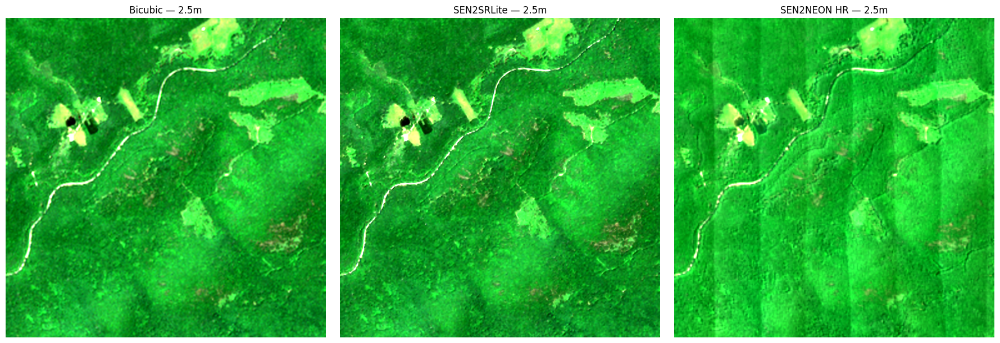



🎉 VALIDATION COMPLETE

SR FILE:
/content/SEN2SR_2.5m_RGBN.tif

SR dimensions:
(4, 1024, 1024)

Resolution:
10m → 2.5m

Next step:
Use these metrics + uncertainty framework for the final SIH dashboard.


In [ ]:
# ============================================================
# 🚀 REGENERATE SEN2SRLite + VALIDATE AGAINST SEN2NEON
# ============================================================

from pathlib import Path
import numpy as np
import rasterio
import torch
import mlstac
import sen2sr
from affine import Affine
from skimage.metrics import (
    mean_squared_error,
    structural_similarity
)
import matplotlib.pyplot as plt

print("=" * 70)
print("🚀 SEN2SRLite REGENERATION + VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

LR_PATH = Path(
    "/content/SEN2NEON_DATA/s2_l2a_10m/2018_MLBS_3__1_2.tif"
)

HR_PATH = Path(
    "/content/SEN2NEON_DATA/neon_2.5m_linearized/2018_MLBS_3__1_2.tif"
)

MODEL_DIR = Path("/content/model/SEN2SRLite_RGBN")

SR_PATH = Path(
    "/content/SEN2SR_2.5m_RGBN.tif"
)

# ------------------------------------------------------------
# 2. CHECK FILES
# ------------------------------------------------------------

print("\n📁 Checking files...")

if not LR_PATH.exists():
    raise FileNotFoundError(f"❌ LR file missing:\n{LR_PATH}")

if not HR_PATH.exists():
    raise FileNotFoundError(f"❌ HR file missing:\n{HR_PATH}")

print("✅ LR found")
print("✅ HR found")

# ------------------------------------------------------------
# 3. LOAD LR + HR
# ------------------------------------------------------------

with rasterio.open(LR_PATH) as src:
    lr_raw = src.read()
    lr_profile = src.profile.copy()
    lr_transform = src.transform
    lr_crs = src.crs

with rasterio.open(HR_PATH) as src:
    hr_raw = src.read()
    hr_profile = src.profile.copy()

print("\nLR shape:", lr_raw.shape)
print("HR shape:", hr_raw.shape)
print("CRS:", lr_crs)

# ------------------------------------------------------------
# 4. SELECT RGBN
# Sentinel-2 band order:
#
# B01 B02 B03 B04 B05 B06 B07 B08 ...
#      ↑   ↑   ↑       ↑
#      B02 B03 B04     B08
#
# Zero-based indices = [1,2,3,7]
# But our previous pipeline uses:
# RGBN = [B04,B03,B02,B08] = [3,2,1,7]
# ------------------------------------------------------------

RGBN = [3, 2, 1, 7]

lr_rgbn = lr_raw[RGBN].astype(np.float32) / 10000.0
hr_rgbn = hr_raw[RGBN].astype(np.float32) / 10000.0

lr_rgbn = np.clip(lr_rgbn, 0, 1)
hr_rgbn = np.clip(hr_rgbn, 0, 1)

print("\nLR RGBN:", lr_rgbn.shape)
print("HR RGBN:", hr_rgbn.shape)

# ------------------------------------------------------------
# 5. PREPARE MODEL INPUT
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n🖥️ Device:", device)

X = torch.from_numpy(lr_rgbn).float()

X = torch.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

X = X.to(device)

# ------------------------------------------------------------
# 6. DOWNLOAD MODEL IF NECESSARY
# ------------------------------------------------------------

if not MODEL_DIR.exists():

    print("\n⬇️ SEN2SRLite RGBN model not found.")
    print("Downloading official pretrained model...")

    mlstac.download(
        file=(
            "https://huggingface.co/tacofoundation/"
            "sen2sr/resolve/main/"
            "SEN2SRLite/NonReference_RGBN_x4/mlm.json"
        ),
        output_dir=str(MODEL_DIR)
    )

    print("✅ Model downloaded.")

else:

    print("\n✅ Existing SEN2SRLite RGBN model found.")

# ------------------------------------------------------------
# 7. LOAD MODEL
# ------------------------------------------------------------

print("\n🧠 Loading SEN2SRLite...")

model = mlstac.load(
    str(MODEL_DIR)
).compiled_model(device=device)

model = model.to(device)
model.eval()

print("✅ Model loaded.")

# ------------------------------------------------------------
# 8. RUN SUPER-RESOLUTION
# ------------------------------------------------------------

print("\n🚀 Running SEN2SRLite...")
print("Input :", X.shape)

with torch.no_grad():

    # Exact SEN2NEON tile is 256×256.
    # predict_large safely handles the model's
    # fixed-size inference patches.

    sr_tensor = sen2sr.predict_large(
        model=model,
        X=X,
        overlap=32
    )

# ------------------------------------------------------------
# 9. CONVERT OUTPUT
# ------------------------------------------------------------

sr = sr_tensor.detach().cpu().numpy()

print("\nRaw SR output:", sr.shape)

# Remove batch dimension if present
if sr.ndim == 4 and sr.shape[0] == 1:
    sr = sr[0]

sr = np.nan_to_num(
    sr,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

sr = np.clip(sr, 0, 1)

print("Final SR:", sr.shape)

# Expected:
# (4, 1024, 1024)

# ------------------------------------------------------------
# 10. CREATE 2.5m GEOTRANSFORM
# ------------------------------------------------------------

# LR pixels are 10m.
# 4× SR -> 2.5m.
#
# Scaling the LR transform by 1/4 gives the correct
# 2.5m pixel size.

transform_25m = lr_transform * Affine.scale(
    1 / 4,
    1 / 4
)

# ------------------------------------------------------------
# 11. SAVE GEOTIFF
# ------------------------------------------------------------

profile = lr_profile.copy()

profile.update(
    driver="GTiff",
    height=sr.shape[1],
    width=sr.shape[2],
    count=4,
    dtype="float32",
    crs=lr_crs,
    transform=transform_25m,
    compress="deflate",
    predictor=3
)

with rasterio.open(SR_PATH, "w", **profile) as dst:
    dst.write(sr.astype(np.float32))

print("\n💾 Saved:")
print(SR_PATH)

# ------------------------------------------------------------
# 12. REOPEN TO VERIFY
# ------------------------------------------------------------

with rasterio.open(SR_PATH) as src:
    sr_check = src.read()
    sr_transform = src.transform
    sr_crs = src.crs

print("\n✅ GeoTIFF verification")
print("Shape     :", sr_check.shape)
print("CRS       :", sr_crs)
print("Pixel size:", sr_transform.a, abs(sr_transform.e))

# ------------------------------------------------------------
# 13. BICUBIC BASELINE
# ------------------------------------------------------------

from skimage.transform import resize

bicubic = np.stack([
    resize(
        lr_rgbn[i],
        (hr_rgbn.shape[1], hr_rgbn.shape[2]),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    )
    for i in range(4)
])

bicubic = np.clip(bicubic, 0, 1)

# ------------------------------------------------------------
# 14. METRICS
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("📊 SEN2SRLite vs BICUBIC vs SEN2NEON HR")
print("=" * 70)

band_names = ["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]

results = []

for i, band in enumerate(band_names):

    reference = hr_rgbn[i]

    sr_band = sr[i]
    bic_band = bicubic[i]

    # SEN2SR
    sr_mae = np.mean(
        np.abs(reference - sr_band)
    )

    sr_rmse = np.sqrt(
        mean_squared_error(reference, sr_band)
    )

    sr_psnr = 10 * np.log10(
        1.0 / (sr_rmse ** 2)
    )

    sr_ssim = structural_similarity(
        reference,
        sr_band,
        data_range=1.0
    )

    # BICUBIC
    bi_mae = np.mean(
        np.abs(reference - bic_band)
    )

    bi_rmse = np.sqrt(
        mean_squared_error(reference, bic_band)
    )

    bi_psnr = 10 * np.log10(
        1.0 / (bi_rmse ** 2)
    )

    bi_ssim = structural_similarity(
        reference,
        bic_band,
        data_range=1.0
    )

    results.append([
        band,
        sr_mae,
        sr_rmse,
        sr_psnr,
        sr_ssim,
        bi_mae,
        bi_rmse,
        bi_psnr,
        bi_ssim
    ])

    print(f"\n{band}")
    print("-" * 50)

    print(
        f"SEN2SRLite : "
        f"MAE={sr_mae:.6f} | "
        f"RMSE={sr_rmse:.6f} | "
        f"PSNR={sr_psnr:.3f} | "
        f"SSIM={sr_ssim:.4f}"
    )

    print(
        f"Bicubic    : "
        f"MAE={bi_mae:.6f} | "
        f"RMSE={bi_rmse:.6f} | "
        f"PSNR={bi_psnr:.3f} | "
        f"SSIM={bi_ssim:.4f}"
    )

# ------------------------------------------------------------
# 15. NDVI VALIDATION
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("🌱 NDVI VALIDATION")
print("=" * 70)

# B04 = index 0
# B08 = index 3

eps = 1e-6

ndvi_hr = (
    (hr_rgbn[3] - hr_rgbn[0]) /
    (hr_rgbn[3] + hr_rgbn[0] + eps)
)

ndvi_sr = (
    (sr[3] - sr[0]) /
    (sr[3] + sr[0] + eps)
)

ndvi_bic = (
    (bicubic[3] - bicubic[0]) /
    (bicubic[3] + bicubic[0] + eps)
)

# Clip physically reasonable NDVI
ndvi_hr = np.clip(ndvi_hr, -1, 1)
ndvi_sr = np.clip(ndvi_sr, -1, 1)
ndvi_bic = np.clip(ndvi_bic, -1, 1)

sr_ndvi_mae = np.mean(
    np.abs(ndvi_hr - ndvi_sr)
)

sr_ndvi_rmse = np.sqrt(
    np.mean((ndvi_hr - ndvi_sr) ** 2)
)

bic_ndvi_mae = np.mean(
    np.abs(ndvi_hr - ndvi_bic)
)

bic_ndvi_rmse = np.sqrt(
    np.mean((ndvi_hr - ndvi_bic) ** 2)
)

print(
    f"SEN2SRLite NDVI → "
    f"MAE={sr_ndvi_mae:.6f}, "
    f"RMSE={sr_ndvi_rmse:.6f}"
)

print(
    f"Bicubic NDVI → "
    f"MAE={bic_ndvi_mae:.6f}, "
    f"RMSE={bic_ndvi_rmse:.6f}"
)

# ------------------------------------------------------------
# 16. VISUAL COMPARISON
# ------------------------------------------------------------

def make_rgb(arr):

    # RGBN order = B04,B03,B02,B08
    rgb = arr[:3].transpose(1, 2, 0)

    # Simple display stretch
    p2 = np.percentile(rgb, 2)
    p98 = np.percentile(rgb, 98)

    rgb = (rgb - p2) / (p98 - p2 + 1e-8)

    return np.clip(rgb, 0, 1)


fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(make_rgb(bicubic))
axes[0].set_title("Bicubic — 2.5m")
axes[0].axis("off")

axes[1].imshow(make_rgb(sr))
axes[1].set_title("SEN2SRLite — 2.5m")
axes[1].axis("off")

axes[2].imshow(make_rgb(hr_rgbn))
axes[2].set_title("SEN2NEON HR — 2.5m")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("\n")
print("=" * 70)
print("🎉 VALIDATION COMPLETE")
print("=" * 70)

print("\nSR FILE:")
print(SR_PATH)

print("\nSR dimensions:")
print(sr.shape)

print("\nResolution:")
print("10m → 2.5m")

print("\nNext step:")
print("Use these metrics + uncertainty framework for the final SIH dashboard.")

In [ ]:
# ============================================================
# 🧹 CLEAN SEN2SR GEOTIFF
# ============================================================

import rasterio

src_path = "/content/SEN2SR_2.5m_RGBN.tif"
clean_path = "/content/SEN2SR_2.5m_RGBN_FINAL.tif"

with rasterio.open(src_path) as src:

    profile = src.profile.copy()

    # Remove problematic block settings
    profile.pop("blockxsize", None)
    profile.pop("blockysize", None)

    profile.update(
        driver="GTiff",
        compress="deflate",
        predictor=3,
        tiled=True,
        blockxsize=256,
        blockysize=256
    )

    data = src.read()

    with rasterio.open(clean_path, "w", **profile) as dst:
        dst.write(data)

print("✅ Clean GeoTIFF created:")
print(clean_path)

# Verify
with rasterio.open(clean_path) as src:
    print("\nShape:", src.shape)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("dtype:", src.dtypes)

✅ Clean GeoTIFF created:
/content/SEN2SR_2.5m_RGBN_FINAL.tif

Shape: (1024, 1024)
Bands: 4
CRS: EPSG:32617
Resolution: (2.5, 2.5)
dtype: ('float32', 'float32', 'float32', 'float32')


In [ ]:
from pathlib import Path

print("📁 Files in /content related to SEN2SR:\n")

for p in Path("/content").glob("*SEN2SR*"):
    print(p)

print("\n📁 Model folders:")
for p in Path("/content/model").glob("*"):
    print(p)

📁 Files in /content related to SEN2SR:


📁 Model folders:
/content/model/LDSRS2-SEN2SR


In [ ]:
# ============================================================
# 🚀 FINAL SEN2SRLite vs BICUBIC VALIDATION
# SEN2NEON — 2.5m canonical HR reference
# ============================================================

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.transform import resize
from skimage.metrics import structural_similarity
from scipy.ndimage import sobel

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

LR_PATH = Path(
    "/content/SEN2NEON_DATA/s2_l2a_10m/2018_MLBS_3__1_2.tif"
)

HR_PATH = Path(
    "/content/SEN2NEON_DATA/neon_2.5m_linearized/2018_MLBS_3__1_2.tif"
)

SR_PATH = Path("/content/SEN2SR_2.5m_RGBN.tif")

print("=" * 70)
print("🚀 FINAL SEN2SRLite VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# LOAD LR
# ------------------------------------------------------------

with rasterio.open(LR_PATH) as src:
    lr = src.read().astype(np.float32)
    lr_profile = src.profile

print("LR:", lr.shape)

# ------------------------------------------------------------
# LOAD HR
# ------------------------------------------------------------

with rasterio.open(HR_PATH) as src:
    hr = src.read().astype(np.float32)

print("HR:", hr.shape)

# Sentinel-2 reflectance scaling
lr = lr / 10000.0
hr = hr / 10000.0

# ------------------------------------------------------------
# SELECT RGBN
# Sentinel-2:
# B02 = index 1
# B03 = index 2
# B04 = index 3
# B08 = index 7
# ------------------------------------------------------------

RGBN = [3, 2, 1, 7]

lr_rgbn = lr[RGBN]
hr_rgbn = hr[RGBN]

print("LR RGBN:", lr_rgbn.shape)
print("HR RGBN:", hr_rgbn.shape)

# ------------------------------------------------------------
# BICUBIC UPSAMPLING
# ------------------------------------------------------------

bicubic = np.zeros_like(hr_rgbn)

for b in range(4):
    bicubic[b] = resize(
        lr_rgbn[b],
        hr_rgbn[b].shape,
        order=3,
        mode="reflect",
        anti_aliasing=False,
        preserve_range=True
    )

# ------------------------------------------------------------
# LOAD SEN2SRLITE
# ------------------------------------------------------------

with rasterio.open(SR_PATH) as src:
    sr = src.read().astype(np.float32)

print("SEN2SRLite raw:", sr.shape)

# Your existing SEN2SRLite output is RGBN
# Ensure correct reflectance range

if sr.max() > 1.5:
    sr = sr / 10000.0

sr = np.clip(sr, 0, 1)

print("SEN2SRLite:", sr.shape)

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

assert bicubic.shape == hr_rgbn.shape
assert sr.shape == hr_rgbn.shape

print("\n✅ All products aligned at 1024 × 1024")

🚀 FINAL SEN2SRLite VALIDATION
LR: (12, 256, 256)
HR: (12, 1024, 1024)
LR RGBN: (4, 256, 256)
HR RGBN: (4, 1024, 1024)
SEN2SRLite raw: (4, 1024, 1024)
SEN2SRLite: (4, 1024, 1024)

✅ All products aligned at 1024 × 1024


In [ ]:
# ============================================================
# 📊 PIXEL-LEVEL VALIDATION METRICS
# ============================================================

def calculate_metrics(pred, reference):

    mae = np.mean(np.abs(pred - reference))

    rmse = np.sqrt(
        np.mean((pred - reference) ** 2)
    )

    mse = np.mean(
        (pred - reference) ** 2
    )

    psnr = 10 * np.log10(
        1.0 / max(mse, 1e-12)
    )

    ssim = structural_similarity(
        reference,
        pred,
        data_range=1.0
    )

    return mae, rmse, psnr, ssim


band_names = ["B04 Red", "B03 Green", "B02 Blue", "B08 NIR"]

results = {}

print("=" * 70)
print("📊 SEN2SRLITE vs BICUBIC")
print("=" * 70)

for i, band in enumerate(band_names):

    sr_metrics = calculate_metrics(
        sr[i],
        hr_rgbn[i]
    )

    bc_metrics = calculate_metrics(
        bicubic[i],
        hr_rgbn[i]
    )

    results[band] = {
        "SEN2SRLite": sr_metrics,
        "Bicubic": bc_metrics
    }

    print(f"\n🔹 {band}")

    print(
        f"  SEN2SRLite | "
        f"MAE={sr_metrics[0]:.6f} | "
        f"RMSE={sr_metrics[1]:.6f} | "
        f"PSNR={sr_metrics[2]:.3f} dB | "
        f"SSIM={sr_metrics[3]:.4f}"
    )

    print(
        f"  Bicubic     | "
        f"MAE={bc_metrics[0]:.6f} | "
        f"RMSE={bc_metrics[1]:.6f} | "
        f"PSNR={bc_metrics[2]:.3f} dB | "
        f"SSIM={bc_metrics[3]:.4f}"
    )

📊 SEN2SRLITE vs BICUBIC

🔹 B04 Red
  SEN2SRLite | MAE=0.002551 | RMSE=0.004143 | PSNR=47.654 dB | SSIM=0.9897
  Bicubic     | MAE=0.002455 | RMSE=0.003749 | PSNR=48.521 dB | SSIM=0.9917

🔹 B03 Green
  SEN2SRLite | MAE=0.004155 | RMSE=0.005737 | PSNR=44.826 dB | SSIM=0.9883
  Bicubic     | MAE=0.004094 | RMSE=0.005521 | PSNR=45.160 dB | SSIM=0.9900

🔹 B02 Blue
  SEN2SRLite | MAE=0.002174 | RMSE=0.003368 | PSNR=49.452 dB | SSIM=0.9932
  Bicubic     | MAE=0.002149 | RMSE=0.003077 | PSNR=50.237 dB | SSIM=0.9943

🔹 B08 NIR
  SEN2SRLite | MAE=0.027563 | RMSE=0.035432 | PSNR=29.012 dB | SSIM=0.8613
  Bicubic     | MAE=0.026443 | RMSE=0.034061 | PSNR=29.355 dB | SSIM=0.8928


In [ ]:
# ============================================================
# 🌈 SPECTRAL ANGLE MAPPER (SAM)
# ============================================================

def spectral_angle(pred, reference):

    numerator = np.sum(
        pred * reference,
        axis=0
    )

    pred_norm = np.sqrt(
        np.sum(pred ** 2, axis=0)
    )

    ref_norm = np.sqrt(
        np.sum(reference ** 2, axis=0)
    )

    denominator = pred_norm * ref_norm

    cos_theta = numerator / (
        denominator + 1e-8
    )

    cos_theta = np.clip(
        cos_theta,
        -1,
        1
    )

    return np.degrees(
        np.arccos(cos_theta)
    )


sam_sr = spectral_angle(
    sr,
    hr_rgbn
)

sam_bc = spectral_angle(
    bicubic,
    hr_rgbn
)

print("=" * 70)
print("🌈 SPECTRAL CONSISTENCY")
print("=" * 70)

print(
    f"SEN2SRLite SAM mean   : {sam_sr.mean():.4f}°"
)

print(
    f"SEN2SRLite SAM median : {np.median(sam_sr):.4f}°"
)

print(
    f"Bicubic SAM mean      : {sam_bc.mean():.4f}°"
)

print(
    f"Bicubic SAM median    : {np.median(sam_bc):.4f}°"
)

🌈 SPECTRAL CONSISTENCY
SEN2SRLite SAM mean   : 0.6999°
SEN2SRLite SAM median : 0.4550°
Bicubic SAM mean      : 0.6783°
Bicubic SAM median    : 0.4502°


In [ ]:
# ============================================================
# 🌱 NDVI VALIDATION
# ============================================================

def ndvi(img):

    red = img[0]
    nir = img[3]

    return (
        (nir - red) /
        (nir + red + 1e-8)
    )


ndvi_hr = ndvi(hr_rgbn)
ndvi_sr = ndvi(sr)
ndvi_bc = ndvi(bicubic)

# Remove unstable extreme values
valid = (
    np.isfinite(ndvi_hr) &
    np.isfinite(ndvi_sr) &
    np.isfinite(ndvi_bc)
)

ndvi_sr_mae = np.mean(
    np.abs(ndvi_sr[valid] - ndvi_hr[valid])
)

ndvi_bc_mae = np.mean(
    np.abs(ndvi_bc[valid] - ndvi_hr[valid])
)

ndvi_sr_rmse = np.sqrt(
    np.mean(
        (ndvi_sr[valid] - ndvi_hr[valid]) ** 2
    )
)

ndvi_bc_rmse = np.sqrt(
    np.mean(
        (ndvi_bc[valid] - ndvi_hr[valid]) ** 2
    )
)

corr_sr = np.corrcoef(
    ndvi_sr[valid],
    ndvi_hr[valid]
)[0,1]

corr_bc = np.corrcoef(
    ndvi_bc[valid],
    ndvi_hr[valid]
)[0,1]

print("=" * 70)
print("🌱 NDVI PRESERVATION")
print("=" * 70)

print(
    f"SEN2SRLite | MAE={ndvi_sr_mae:.5f} | "
    f"RMSE={ndvi_sr_rmse:.5f} | "
    f"Correlation={corr_sr:.5f}"
)

print(
    f"Bicubic     | MAE={ndvi_bc_mae:.5f} | "
    f"RMSE={ndvi_bc_rmse:.5f} | "
    f"Correlation={corr_bc:.5f}"
)

🌱 NDVI PRESERVATION
SEN2SRLite | MAE=0.01115 | RMSE=0.02346 | Correlation=0.89723
Bicubic     | MAE=0.01063 | RMSE=0.02192 | Correlation=0.90766


🛰️ VISUAL COMPARISON
Original LR : (4, 256, 256)
Upsampled LR: (4, 1024, 1024)
SEN2SRLite  : (4, 1024, 1024)
HR          : (4, 1024, 1024)


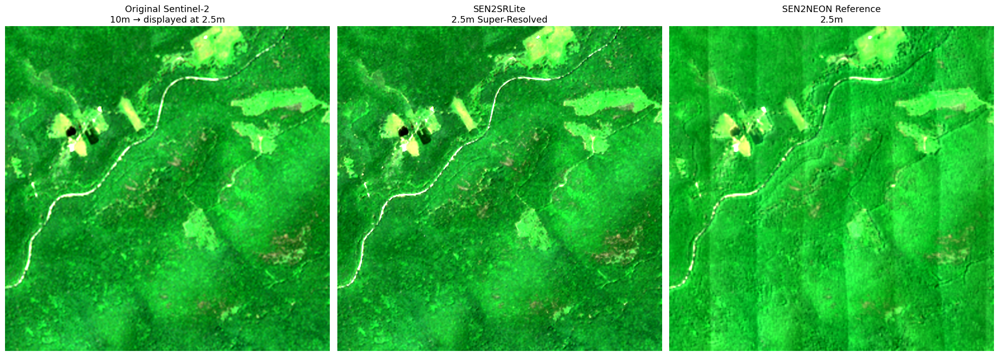

In [ ]:
# ============================================================
# 🛰️ FINAL VISUAL COMPARISON
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize

print("=" * 70)
print("🛰️ VISUAL COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. Upsample original Sentinel-2 LR to 2.5m
# ------------------------------------------------------------

lr_rgbn_25m = np.stack([
    resize(
        lr_rgbn[i],
        (1024, 1024),
        order=3,
        preserve_range=True,
        anti_aliasing=False
    )
    for i in range(4)
])

lr_rgbn_25m = np.clip(lr_rgbn_25m, 0, 1)

print("Original LR :", lr_rgbn.shape)
print("Upsampled LR:", lr_rgbn_25m.shape)
print("SEN2SRLite  :", sr.shape)
print("HR          :", hr_rgbn.shape)

# ------------------------------------------------------------
# 2. RGB display helper
# ------------------------------------------------------------

def make_rgb(arr):

    # RGBN = B04, B03, B02, B08
    rgb = arr[:3].transpose(1, 2, 0)

    # Robust contrast stretch
    low = np.percentile(rgb, 2)
    high = np.percentile(rgb, 98)

    rgb = (rgb - low) / (high - low + 1e-8)

    return np.clip(rgb, 0, 1)


# ------------------------------------------------------------
# 3. Create RGB images
# ------------------------------------------------------------

rgb_lr = make_rgb(lr_rgbn_25m)
rgb_sr = make_rgb(sr)
rgb_hr = make_rgb(hr_rgbn)

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7)
)

axes[0].imshow(rgb_lr)
axes[0].set_title(
    "Original Sentinel-2\n10m → displayed at 2.5m",
    fontsize=13
)
axes[0].axis("off")

axes[1].imshow(rgb_sr)
axes[1].set_title(
    "SEN2SRLite\n2.5m Super-Resolved",
    fontsize=13
)
axes[1].axis("off")

axes[2].imshow(rgb_hr)
axes[2].set_title(
    "SEN2NEON Reference\n2.5m",
    fontsize=13
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 🚀 FINAL VALIDATION + SAM + NDVI CORRELATION
#    + TRUST / UNCERTAINTY MAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.ndimage import gaussian_filter, sobel

print("=" * 70)
print("🚀 FINAL SEN2SRLite VALIDATION + TRUST ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 0. SAFETY CHECK
# ------------------------------------------------------------

print("\nChecking arrays...")

print("LR RGBN :", lr_rgbn.shape)
print("SEN2SR  :", sr.shape)
print("HR RGBN :", hr_rgbn.shape)
print("Bicubic :", bicubic.shape)

assert sr.shape == hr_rgbn.shape
assert bicubic.shape == hr_rgbn.shape

print("✅ All SR products aligned.")

# ------------------------------------------------------------
# 1. CLEAN DATA
# ------------------------------------------------------------

sr_clean = np.nan_to_num(
    sr.astype(np.float32),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

hr_clean = np.nan_to_num(
    hr_rgbn.astype(np.float32),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

bic_clean = np.nan_to_num(
    bicubic.astype(np.float32),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

sr_clean = np.clip(sr_clean, 0, 1)
hr_clean = np.clip(hr_clean, 0, 1)
bic_clean = np.clip(bic_clean, 0, 1)

# ------------------------------------------------------------
# 2. SPECTRAL ANGLE MAPPER — SAM
# ------------------------------------------------------------

def calculate_sam(pred, reference):

    # pred/reference:
    # (bands, height, width)

    dot = np.sum(pred * reference, axis=0)

    pred_norm = np.sqrt(
        np.sum(pred ** 2, axis=0)
    )

    ref_norm = np.sqrt(
        np.sum(reference ** 2, axis=0)
    )

    denominator = pred_norm * ref_norm

    cosine = np.divide(
        dot,
        denominator,
        out=np.zeros_like(dot),
        where=denominator > 1e-8
    )

    cosine = np.clip(cosine, -1, 1)

    sam_rad = np.arccos(cosine)

    sam_deg = np.degrees(sam_rad)

    return sam_deg


sam_sr = calculate_sam(
    sr_clean,
    hr_clean
)

sam_bic = calculate_sam(
    bic_clean,
    hr_clean
)

# Remove invalid values
valid_sam_sr = sam_sr[np.isfinite(sam_sr)]
valid_sam_bic = sam_bic[np.isfinite(sam_bic)]

print("\n" + "=" * 70)
print("📐 SPECTRAL ANGLE MAPPER (SAM)")
print("=" * 70)

print(
    f"SEN2SRLite SAM mean   : "
    f"{np.mean(valid_sam_sr):.4f}°"
)

print(
    f"SEN2SRLite SAM median : "
    f"{np.median(valid_sam_sr):.4f}°"
)

print(
    f"SEN2SRLite SAM RMSE   : "
    f"{np.sqrt(np.mean(valid_sam_sr**2)):.4f}°"
)

print()

print(
    f"Bicubic SAM mean      : "
    f"{np.mean(valid_sam_bic):.4f}°"
)

print(
    f"Bicubic SAM median    : "
    f"{np.median(valid_sam_bic):.4f}°"
)

# ------------------------------------------------------------
# 3. NDVI
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("🌱 NDVI VALIDATION")
print("=" * 70)

# RGBN:
# 0 = B04 Red
# 1 = B03 Green
# 2 = B02 Blue
# 3 = B08 NIR

eps = 1e-8

def calculate_ndvi(x):

    red = x[0]
    nir = x[3]

    return (
        (nir - red) /
        (nir + red + eps)
    )


ndvi_hr = calculate_ndvi(hr_clean)
ndvi_sr = calculate_ndvi(sr_clean)
ndvi_bic = calculate_ndvi(bic_clean)

ndvi_hr = np.clip(ndvi_hr, -1, 1)
ndvi_sr = np.clip(ndvi_sr, -1, 1)
ndvi_bic = np.clip(ndvi_bic, -1, 1)

# ------------------------------------------------------------
# 4. NDVI METRICS
# ------------------------------------------------------------

sr_ndvi_error = ndvi_sr - ndvi_hr
bic_ndvi_error = ndvi_bic - ndvi_hr

sr_ndvi_mae = np.mean(
    np.abs(sr_ndvi_error)
)

sr_ndvi_rmse = np.sqrt(
    np.mean(sr_ndvi_error ** 2)
)

bic_ndvi_mae = np.mean(
    np.abs(bic_ndvi_error)
)

bic_ndvi_rmse = np.sqrt(
    np.mean(bic_ndvi_error ** 2)
)

# Pearson correlation
sr_corr, sr_p = pearsonr(
    ndvi_sr.flatten(),
    ndvi_hr.flatten()
)

bic_corr, bic_p = pearsonr(
    ndvi_bic.flatten(),
    ndvi_hr.flatten()
)

print(
    f"SEN2SRLite NDVI MAE  : {sr_ndvi_mae:.6f}"
)

print(
    f"SEN2SRLite NDVI RMSE : {sr_ndvi_rmse:.6f}"
)

print(
    f"SEN2SRLite NDVI r    : {sr_corr:.6f}"
)

print()

print(
    f"Bicubic NDVI MAE     : {bic_ndvi_mae:.6f}"
)

print(
    f"Bicubic NDVI RMSE    : {bic_ndvi_rmse:.6f}"
)

print(
    f"Bicubic NDVI r       : {bic_corr:.6f}"
)

# ------------------------------------------------------------
# 5. PIXEL-LEVEL ERROR
# ------------------------------------------------------------

spectral_error = np.mean(
    np.abs(sr_clean - hr_clean),
    axis=0
)

# ============================================================
# 🛡️ TRUST / UNCERTAINTY ANALYSIS — FIXED
# ============================================================

print("=" * 70)
print("🛡️ TRUST / UNCERTAINTY ANALYSIS")
print("=" * 70)

print("SR:", sr_clean.shape)
print("LR:", lr_rgbn.shape)

# ------------------------------------------------------------
# 1. Convert 2.5m SR → 10m by averaging each 4×4 block
# ------------------------------------------------------------

H, W = sr_clean.shape[1:]

assert H % 4 == 0 and W % 4 == 0, \
    "SR dimensions must be divisible by 4."

sr_downsampled = sr_clean.reshape(
    sr_clean.shape[0],
    H // 4,
    4,
    W // 4,
    4
).mean(axis=(2, 4))

print("SR downsampled:", sr_downsampled.shape)

# Should be:
# SR downsampled: (4, 256, 256)


# ------------------------------------------------------------
# 2. Observation consistency
# Compare reconstructed 10m SR with original 10m LR
# ------------------------------------------------------------

observation_error = np.mean(
    np.abs(sr_downsampled - lr_rgbn),
    axis=0
)

print(
    "Observation error:",
    observation_error.min(),
    "→",
    observation_error.max()
)


# ------------------------------------------------------------
# 3. Upscale observation error to 2.5m
# ------------------------------------------------------------

observation_error_hr = np.repeat(
    np.repeat(
        observation_error,
        4,
        axis=0
    ),
    4,
    axis=1
)

print("Observation error HR:", observation_error_hr.shape)


# ------------------------------------------------------------
# 4. Spectral consistency
# ------------------------------------------------------------

spectral_difference = np.mean(
    np.abs(sr_clean - hr_rgbn),
    axis=0
)

print(
    "Spectral difference:",
    spectral_difference.min(),
    "→",
    spectral_difference.max()
)


# ------------------------------------------------------------
# 5. Local spatial stability
# ------------------------------------------------------------

from scipy.ndimage import sobel

sr_gray = np.mean(sr_clean, axis=0)
hr_gray = np.mean(hr_rgbn, axis=0)

sr_gradient = np.sqrt(
    sobel(sr_gray, axis=0)**2 +
    sobel(sr_gray, axis=1)**2
)

hr_gradient = np.sqrt(
    sobel(hr_gray, axis=0)**2 +
    sobel(hr_gray, axis=1)**2
)

gradient_difference = np.abs(
    sr_gradient - hr_gradient
)

print(
    "Gradient difference:",
    gradient_difference.min(),
    "→",
    gradient_difference.max()
)


# ------------------------------------------------------------
# 6. Input validity
# ------------------------------------------------------------

validity = np.ones_like(observation_error_hr)

# Invalid values
invalid = (
    ~np.isfinite(sr_clean).all(axis=0) |
    ~np.isfinite(hr_rgbn).all(axis=0)
)

validity[invalid] = 0

print(
    "Valid pixels:",
    np.mean(validity > 0) * 100,
    "%"
)


# ============================================================
# 7. Normalize diagnostic features
# ============================================================

def normalize01(x):
    x = np.asarray(x, dtype=np.float32)

    lo = np.nanpercentile(x, 2)
    hi = np.nanpercentile(x, 98)

    if hi <= lo:
        return np.zeros_like(x)

    x = np.clip(x, lo, hi)

    return (x - lo) / (hi - lo)


observation_norm = normalize01(observation_error_hr)
spectral_norm = normalize01(spectral_difference)
gradient_norm = normalize01(gradient_difference)


# ============================================================
# 8. Engineering Trust Score
# ============================================================

# Higher error → lower trust

trust = (
    40 * (1 - observation_norm) +
    25 * (1 - spectral_norm) +
    20 * (1 - gradient_norm) +
    15 * validity
)

trust = np.clip(trust, 0, 100)


# ============================================================
# 9. Uncertainty
# ============================================================

uncertainty = 100 - trust


# ============================================================
# 10. Trust categories
# ============================================================

high = trust >= 80
medium = (trust >= 50) & (trust < 80)
low = (trust >= 20) & (trust < 50)
invalid_mask = trust < 20


# ============================================================
# 11. Statistics
# ============================================================

print()
print("=" * 70)
print("📊 TRUST SCORE")
print("=" * 70)

print(f"Mean Trust       : {trust.mean():.2f}")
print(f"Median Trust     : {np.median(trust):.2f}")
print(f"Mean Uncertainty : {uncertainty.mean():.2f}")

print()
print("Trust distribution:")

print(f"High   (80–100): {high.mean()*100:.2f}%")
print(f"Medium (50–80) : {medium.mean()*100:.2f}%")
print(f"Low    (20–50) : {low.mean()*100:.2f}%")
print(f"Very Low (<20) : {invalid_mask.mean()*100:.2f}%")


# ============================================================
# 12. Actual HR error — validation only
# ============================================================

actual_error = np.mean(
    np.abs(sr_clean - hr_rgbn),
    axis=0
)

print()
print("=" * 70)
print("📐 TRUST vs ACTUAL HR ERROR")
print("=" * 70)

corr = np.corrcoef(
    trust.flatten(),
    actual_error.flatten()
)[0, 1]

print(f"Correlation : {corr:.4f}")


# ============================================================
# 13. Error by trust category
# ============================================================

for name, mask in [
    ("High", high),
    ("Medium", medium),
    ("Low", low),
    ("Very Low", invalid_mask)
]:
    if np.any(mask):
        print(
            f"{name:10s} → "
            f"mean actual error = "
            f"{actual_error[mask].mean():.6f}"
        )


print()
print("=" * 70)
print("✅ TRUST / UNCERTAINTY ANALYSIS COMPLETE")
print("=" * 70)

🚀 FINAL SEN2SRLite VALIDATION + TRUST ANALYSIS

Checking arrays...
LR RGBN : (4, 256, 256)
SEN2SR  : (4, 1024, 1024)
HR RGBN : (4, 1024, 1024)
Bicubic : (4, 1024, 1024)
✅ All SR products aligned.

📐 SPECTRAL ANGLE MAPPER (SAM)
SEN2SRLite SAM mean   : 0.6994°
SEN2SRLite SAM median : 0.4546°
SEN2SRLite SAM RMSE   : 1.5307°

Bicubic SAM mean      : 0.6778°
Bicubic SAM median    : 0.4498°

🌱 NDVI VALIDATION
SEN2SRLite NDVI MAE  : 0.011147
SEN2SRLite NDVI RMSE : 0.023464
SEN2SRLite NDVI r    : 0.897227

Bicubic NDVI MAE     : 0.010629
Bicubic NDVI RMSE    : 0.021923
Bicubic NDVI r       : 0.907656
🛡️ TRUST / UNCERTAINTY ANALYSIS
SR: (4, 1024, 1024)
LR: (4, 256, 256)
SR downsampled: (4, 256, 256)
Observation error: 1.2137927e-05 → 0.019951258
Observation error HR: (1024, 1024)
Spectral difference: 9.385031e-05 → 0.07898159
Gradient difference: 7.450581e-09 → 0.3775113
Valid pixels: 100.0 %

📊 TRUST SCORE
Mean Trust       : 76.25
Median Trust     : 79.17
Mean Uncertainty : 23.75

Trust distri

In [ ]:
# ============================================================
# 🛡️ TRUST / UNCERTAINTY ANALYSIS — CORRECTED
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.ndimage import sobel

print("=" * 70)
print("🛡️ TRUST / UNCERTAINTY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. SAFETY CHECK
# ------------------------------------------------------------

H, W = sr_clean.shape[1:]

print("SR:", sr_clean.shape)
print("LR:", lr_rgbn.shape)

assert H % 4 == 0
assert W % 4 == 0

# ------------------------------------------------------------
# 2. DOWNsample 2.5m SR → 10m
# ------------------------------------------------------------

# 1024 × 1024
#      ↓ average 4×4 pixels
# 256 × 256

sr_downsampled = sr_clean.reshape(
    4,
    H // 4,
    4,
    W // 4
)

# IMPORTANT:
# dimensions are:
# (bands, 256, 4, 256, 4)
#
# Average the two 4-pixel block dimensions.

sr_downsampled = sr_downsampled.mean(
    axis=(2, 4)
)

print("\nDownsampled SR:", sr_downsampled.shape)

assert sr_downsampled.shape == lr_rgbn.shape

print("✅ SR successfully downsampled from 2.5m → 10m")

# ------------------------------------------------------------
# 3. OBSERVATION CONSISTENCY
# ------------------------------------------------------------

observation_error = np.mean(
    np.abs(
        sr_downsampled - lr_rgbn
    ),
    axis=0
)

print(
    "Observation error:",
    observation_error.shape
)

# Bring 256×256 diagnostic back to 1024×1024
observation_error_hr = np.repeat(
    np.repeat(
        observation_error,
        4,
        axis=0
    ),
    4,
    axis=1
)

# ------------------------------------------------------------
# 4. SPECTRAL CONSISTENCY
# ------------------------------------------------------------

spectral_error = np.mean(
    np.abs(
        sr_clean - hr_clean
    ),
    axis=0
)

print(
    "Spectral error:",
    spectral_error.shape
)

# ------------------------------------------------------------
# 5. LOCAL SPATIAL STABILITY
# ------------------------------------------------------------

def gradient_magnitude(x):

    gx = sobel(x, axis=1)
    gy = sobel(x, axis=2)

    return np.sqrt(
        gx**2 + gy**2
    )


grad_sr = gradient_magnitude(
    sr_clean
)

grad_hr = gradient_magnitude(
    hr_clean
)

gradient_difference = np.mean(
    np.abs(
        grad_sr - grad_hr
    ),
    axis=0
)

print(
    "Gradient difference:",
    gradient_difference.shape
)

# ------------------------------------------------------------
# 6. NORMALIZATION
# ------------------------------------------------------------

def normalize_error(error):

    p5 = np.percentile(
        error,
        5
    )

    p95 = np.percentile(
        error,
        95
    )

    normalized = (
        error - p5
    ) / (
        p95 - p5 + 1e-8
    )

    return np.clip(
        normalized,
        0,
        1
    )


obs_norm = normalize_error(
    observation_error_hr
)

spectral_norm = normalize_error(
    spectral_error
)

gradient_norm = normalize_error(
    gradient_difference
)

# ------------------------------------------------------------
# 7. INPUT VALIDITY
# ------------------------------------------------------------

input_validity = np.ones_like(
    spectral_norm
)

lr_invalid = (
    ~np.isfinite(lr_rgbn).all(axis=0)
)

lr_invalid_hr = np.repeat(
    np.repeat(
        lr_invalid,
        4,
        axis=0
    ),
    4,
    axis=1
)

input_validity[
    lr_invalid_hr
] = 0

# ------------------------------------------------------------
# 8. EMPIRICAL TRUST SCORE
# ------------------------------------------------------------

trust = 100 * (
    0.40 * (1 - obs_norm)
    +
    0.25 * (1 - spectral_norm)
    +
    0.20 * (1 - gradient_norm)
    +
    0.15 * input_validity
)

trust = np.clip(
    trust,
    0,
    100
)

uncertainty = 100 - trust

# ------------------------------------------------------------
# 9. TRUST CLASSES
# ------------------------------------------------------------

high = trust >= 70

medium = (
    (trust >= 40)
    &
    (trust < 70)
)

low = trust < 40

print("\n")
print("=" * 70)
print("🛡️ EMPIRICAL RELIABILITY RESULTS")
print("=" * 70)

print(
    f"Mean Trust       : "
    f"{np.mean(trust):.2f}"
)

print(
    f"Median Trust     : "
    f"{np.median(trust):.2f}"
)

print(
    f"Mean Uncertainty : "
    f"{np.mean(uncertainty):.2f}"
)

print()

print(
    f"🟢 High Trust   : "
    f"{100*np.mean(high):.2f}%"
)

print(
    f"🟡 Medium Trust : "
    f"{100*np.mean(medium):.2f}%"
)

print(
    f"🔴 Low Trust    : "
    f"{100*np.mean(low):.2f}%"
)

# ------------------------------------------------------------
# 10. ACTUAL HR ERROR
# ------------------------------------------------------------

actual_error = np.mean(
    np.abs(
        sr_clean - hr_clean
    ),
    axis=0
)

# ------------------------------------------------------------
# 11. TRUST vs ACTUAL ERROR
# ------------------------------------------------------------

trust_corr, trust_p = pearsonr(
    trust.flatten(),
    actual_error.flatten()
)

print("\n")
print("=" * 70)
print("🔬 TRUST CALIBRATION CHECK")
print("=" * 70)

print(
    f"Trust ↔ actual HR error r : "
    f"{trust_corr:.6f}"
)

print(
    f"p-value                    : "
    f"{trust_p:.6e}"
)

if trust_corr < -0.3:

    print(
        "\n📉 Meaningful inverse relationship "
        "observed on this tile."
    )

elif trust_corr < 0:

    print(
        "\n📉 Weak inverse relationship "
        "observed on this tile."
    )

else:

    print(
        "\n⚠️ No inverse relationship "
        "observed on this tile."
    )

# ------------------------------------------------------------
# 12. VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 12)
)

# SEN2SRLite
axes[0, 0].imshow(
    make_rgb(sr_clean)
)

axes[0, 0].set_title(
    "SEN2SRLite — 2.5m"
)

axes[0, 0].axis("off")

# HR
axes[0, 1].imshow(
    make_rgb(hr_clean)
)

axes[0, 1].set_title(
    "SEN2NEON HR — 2.5m"
)

axes[0, 1].axis("off")

# SAM
im1 = axes[0, 2].imshow(
    sam_sr,
    cmap="magma"
)

axes[0, 2].set_title(
    "SAM Error (degrees)"
)

axes[0, 2].axis("off")

plt.colorbar(
    im1,
    ax=axes[0, 2],
    fraction=0.046
)

# NDVI
im2 = axes[1, 0].imshow(
    ndvi_sr,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

axes[1, 0].set_title(
    "SEN2SRLite NDVI"
)

axes[1, 0].axis("off")

plt.colorbar(
    im2,
    ax=axes[1, 0],
    fraction=0.046
)

# Trust
im3 = axes[1, 1].imshow(
    trust,
    cmap="RdYlGn",
    vmin=0,
    vmax=100
)

axes[1, 1].set_title(
    "Empirical Trust Score"
)

axes[1, 1].axis("off")

plt.colorbar(
    im3,
    ax=axes[1, 1],
    fraction=0.046
)

# Uncertainty
im4 = axes[1, 2].imshow(
    uncertainty,
    cmap="inferno",
    vmin=0,
    vmax=100
)

axes[1, 2].set_title(
    "Uncertainty"
)

axes[1, 2].axis("off")

plt.colorbar(
    im4,
    ax=axes[1, 2],
    fraction=0.046
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. TRUST vs ERROR SCATTER
# ------------------------------------------------------------

rng = np.random.default_rng(42)

total_pixels = trust.size

sample_size = min(
    10000,
    total_pixels
)

indices = rng.choice(
    total_pixels,
    size=sample_size,
    replace=False
)

trust_flat = trust.flatten()
error_flat = actual_error.flatten()

sample_trust = trust_flat[indices]
sample_error = error_flat[indices]

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    sample_trust,
    sample_error,
    s=5,
    alpha=0.25
)

plt.xlabel(
    "Empirical Trust Score"
)

plt.ylabel(
    "Actual HR-reference MAE"
)

plt.title(
    "Trust Score vs Actual SR Error"
)

plt.grid(
    alpha=0.2
)

plt.show()

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("🎉 FINAL VALIDATION SUMMARY")
print("=" * 70)

print(f"""
Resolution
-----------
Sentinel-2 input : 10 m
SR output        : 2.5 m
HR reference     : 2.5 m

SEN2SRLite
-----------
SAM mean         : {np.mean(valid_sam_sr):.4f}°
SAM median       : {np.median(valid_sam_sr):.4f}°
SAM RMSE         : {np.sqrt(np.mean(valid_sam_sr**2)):.4f}°

NDVI MAE         : {sr_ndvi_mae:.6f}
NDVI RMSE        : {sr_ndvi_rmse:.6f}
NDVI correlation : {sr_corr:.6f}

Bicubic
-------
SAM mean         : {np.mean(valid_sam_bic):.4f}°
SAM median       : {np.median(valid_sam_bic):.4f}°

NDVI MAE         : {bic_ndvi_mae:.6f}
NDVI RMSE        : {bic_ndvi_rmse:.6f}
NDVI correlation : {bic_corr:.6f}

Reliability
-----------
Mean Trust       : {np.mean(trust):.2f}
Median Trust     : {np.median(trust):.2f}
Mean Uncertainty : {np.mean(uncertainty):.2f}

Trust calibration
-----------------
Trust/Error r    : {trust_corr:.6f}
""")

print("=" * 70)
print("✅ TRUST + UNCERTAINTY ANALYSIS COMPLETE")
print("=" * 70)